In [1]:
import numpy as np
import pandas as pd
import joblib
import json

from pathlib import Path

# Scikit-learn models and evaluation tools
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# Project paths
PROJECT_ROOT = Path(r"C:\CricIQ")

MODEL_DIR = PROJECT_ROOT / "data" / "processed" / "model_ready"

# Load feature matrices
X_train = np.load(MODEL_DIR / "X_train.npy")
X_validation = np.load(MODEL_DIR / "X_validation.npy")
X_test = np.load(MODEL_DIR / "X_test.npy")

# Load target arrays
y_train = np.load(MODEL_DIR / "y_train.npy")
y_validation = np.load(MODEL_DIR / "y_validation.npy")
y_test = np.load(MODEL_DIR / "y_test.npy")

# Load fitted preprocessing pipeline
preprocessor = joblib.load(
    MODEL_DIR / "cricketiq_preprocessor.joblib"
)

# Load metadata
with open(MODEL_DIR / "metadata.json", "r") as file:
    metadata = json.load(file)

print("CRICKETIQ DATA LOADED SUCCESSFULLY")
print("=" * 60)

print("\nFeature matrix shapes:")
print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)

print("\nTarget shapes:")
print("y_train:", y_train.shape)
print("y_validation:", y_validation.shape)
print("y_test:", y_test.shape)

print("\nPreprocessor:", type(preprocessor).__name__)
print("Metadata:", metadata)

CRICKETIQ DATA LOADED SUCCESSFULLY

Feature matrix shapes:
X_train: (1830, 637)
X_validation: (392, 637)
X_test: (392, 637)

Target shapes:
y_train: (1830,)
y_validation: (392,)
y_test: (392,)

Preprocessor: ColumnTransformer
Metadata: {'training_matches': 1830, 'validation_matches': 392, 'testing_matches': 392, 'transformed_feature_count': 637, 'target': 'team_1_win', 'prediction_type': 'binary_classification', 'split_strategy': 'chronological', 'train_end_date': '2019-10-02', 'validation_end_date': '2023-09-06', 'test_end_date': '2026-10-25'}


In [2]:
# Check target classes
print("TARGET DISTRIBUTION")
print("=" * 60)

for name, y in [
    ("Training", y_train),
    ("Validation", y_validation),
    ("Testing", y_test)
]:
    counts = pd.Series(y).value_counts().sort_index()
    percentages = pd.Series(y).value_counts(normalize=True).sort_index() * 100

    print(f"\n{name}:")
    print("Team 2 wins (0):", counts.get(0, 0))
    print("Team 1 wins (1):", counts.get(1, 0))
    print("Class percentages:")
    print(percentages.round(2))

# Check data integrity
print("\n\nDATA INTEGRITY")
print("=" * 60)

print("Missing values in X_train:", np.isnan(X_train).sum())
print("Missing values in X_validation:", np.isnan(X_validation).sum())
print("Missing values in X_test:", np.isnan(X_test).sum())

print("Infinite values in X_train:", np.isinf(X_train).sum())
print("Infinite values in X_validation:", np.isinf(X_validation).sum())
print("Infinite values in X_test:", np.isinf(X_test).sum())

print("\nUnique target labels:")
print("Training:", np.unique(y_train))
print("Validation:", np.unique(y_validation))
print("Testing:", np.unique(y_test))

TARGET DISTRIBUTION

Training:
Team 2 wins (0): 806
Team 1 wins (1): 1024
Class percentages:
0    44.04
1    55.96
Name: proportion, dtype: float64

Validation:
Team 2 wins (0): 195
Team 1 wins (1): 197
Class percentages:
0    49.74
1    50.26
Name: proportion, dtype: float64

Testing:
Team 2 wins (0): 195
Team 1 wins (1): 197
Class percentages:
0    49.74
1    50.26
Name: proportion, dtype: float64


DATA INTEGRITY
Missing values in X_train: 0
Missing values in X_validation: 0
Missing values in X_test: 0
Infinite values in X_train: 0
Infinite values in X_validation: 0
Infinite values in X_test: 0

Unique target labels:
Training: [0 1]
Validation: [0 1]
Testing: [0 1]


In [3]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
logistic_model = LogisticRegression(
    max_iter=2000,
    C=1.0,
    solver="lbfgs",
    class_weight=None,
    random_state=42
)

# Train using training data only
logistic_model.fit(X_train, y_train)

# Generate predictions
y_train_pred = logistic_model.predict(X_train)
y_validation_pred = logistic_model.predict(X_validation)

# Generate probability predictions
y_train_prob = logistic_model.predict_proba(X_train)[:, 1]
y_validation_prob = logistic_model.predict_proba(X_validation)[:, 1]

print("LOGISTIC REGRESSION TRAINING COMPLETED")
print("=" * 60)

print("Model:", logistic_model)
print("\nTraining predictions:", len(y_train_pred))
print("Validation predictions:", len(y_validation_pred))

print("\nSample validation predictions:")
print("Actual outcomes:    ", y_validation[:10])
print("Predicted outcomes: ", y_validation_pred[:10])
print("Team 1 win probabilities:", np.round(y_validation_prob[:10], 3))

LOGISTIC REGRESSION TRAINING COMPLETED
Model: LogisticRegression(max_iter=2000, random_state=42)

Training predictions: 1830
Validation predictions: 392

Sample validation predictions:
Actual outcomes:     [0 0 0 0 0 0 1 1 0 1]
Predicted outcomes:  [0 1 1 1 1 1 1 1 1 1]
Team 1 win probabilities: [0.068 0.594 0.651 0.813 0.947 0.647 0.941 0.946 0.908 0.96 ]


In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

def evaluate_model(model_name, y_actual, y_pred, y_prob):

    print(f"\n{model_name}")
    print("=" * 60)

    print(f"Accuracy:  {accuracy_score(y_actual, y_pred):.4f}")
    print(f"Precision: {precision_score(y_actual, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_actual, y_pred):.4f}")
    print(f"F1 Score:  {f1_score(y_actual, y_pred):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_actual, y_prob):.4f}")
    print(f"Log Loss:  {log_loss(y_actual, y_prob):.4f}")
    print(f"Brier:     {brier_score_loss(y_actual, y_prob):.4f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_actual, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_actual,
        y_pred,
        target_names=["Team 2 Win", "Team 1 Win"]
    ))


# Training evaluation
evaluate_model(
    "LOGISTIC REGRESSION - TRAINING",
    y_train,
    y_train_pred,
    y_train_prob
)

# Validation evaluation
evaluate_model(
    "LOGISTIC REGRESSION - VALIDATION",
    y_validation,
    y_validation_pred,
    y_validation_prob
)


LOGISTIC REGRESSION - TRAINING
Accuracy:  0.8273
Precision: 0.8278
Recall:    0.8730
F1 Score:  0.8498
ROC-AUC:   0.9188
Log Loss:  0.3580
Brier:     0.1144

Confusion Matrix:
[[620 186]
 [130 894]]

Classification Report:
              precision    recall  f1-score   support

  Team 2 Win       0.83      0.77      0.80       806
  Team 1 Win       0.83      0.87      0.85      1024

    accuracy                           0.83      1830
   macro avg       0.83      0.82      0.82      1830
weighted avg       0.83      0.83      0.83      1830


LOGISTIC REGRESSION - VALIDATION
Accuracy:  0.6760
Precision: 0.6535
Recall:    0.7563
F1 Score:  0.7012
ROC-AUC:   0.7621
Log Loss:  0.6198
Brier:     0.2090

Confusion Matrix:
[[116  79]
 [ 48 149]]

Classification Report:
              precision    recall  f1-score   support

  Team 2 Win       0.71      0.59      0.65       195
  Team 1 Win       0.65      0.76      0.70       197

    accuracy                           0.68       392
   ma

In [5]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=5,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest_model.fit(X_train, y_train)

# Generate predictions
rf_train_pred = random_forest_model.predict(X_train)
rf_validation_pred = random_forest_model.predict(X_validation)

# Generate probability predictions
rf_train_prob = random_forest_model.predict_proba(X_train)[:, 1]
rf_validation_prob = random_forest_model.predict_proba(X_validation)[:, 1]

print("RANDOM FOREST TRAINING COMPLETED")
print("=" * 60)

print("Number of trees:", random_forest_model.n_estimators)
print("Training predictions:", len(rf_train_pred))
print("Validation predictions:", len(rf_validation_pred))

print("\nSample validation predictions:")
print("Actual outcomes:    ", y_validation[:10])
print("Predicted outcomes: ", rf_validation_pred[:10])
print("Team 1 win probabilities:", np.round(rf_validation_prob[:10], 3))

RANDOM FOREST TRAINING COMPLETED
Number of trees: 300
Training predictions: 1830
Validation predictions: 392

Sample validation predictions:
Actual outcomes:     [0 0 0 0 0 0 1 1 0 1]
Predicted outcomes:  [0 0 1 1 1 0 1 1 1 1]
Team 1 win probabilities: [0.253 0.455 0.519 0.594 0.699 0.481 0.588 0.589 0.74  0.747]


In [6]:
# Evaluate Random Forest on training data
evaluate_model(
    "RANDOM FOREST - TRAINING",
    y_train,
    rf_train_pred,
    rf_train_prob
)

# Evaluate Random Forest on validation data
evaluate_model(
    "RANDOM FOREST - VALIDATION",
    y_validation,
    rf_validation_pred,
    rf_validation_prob
)


RANDOM FOREST - TRAINING
Accuracy:  0.9650
Precision: 0.9554
Recall:    0.9834
F1 Score:  0.9692
ROC-AUC:   0.9960
Log Loss:  0.2818
Brier:     0.0716

Confusion Matrix:
[[ 759   47]
 [  17 1007]]

Classification Report:
              precision    recall  f1-score   support

  Team 2 Win       0.98      0.94      0.96       806
  Team 1 Win       0.96      0.98      0.97      1024

    accuracy                           0.97      1830
   macro avg       0.97      0.96      0.96      1830
weighted avg       0.97      0.97      0.96      1830


RANDOM FOREST - VALIDATION
Accuracy:  0.7270
Precision: 0.6907
Recall:    0.8274
F1 Score:  0.7529
ROC-AUC:   0.8012
Log Loss:  0.5472
Brier:     0.1832

Confusion Matrix:
[[122  73]
 [ 34 163]]

Classification Report:
              precision    recall  f1-score   support

  Team 2 Win       0.78      0.63      0.70       195
  Team 1 Win       0.69      0.83      0.75       197

    accuracy                           0.73       392
   macro avg 

In [7]:
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Validation Accuracy": accuracy_score(y_validation, y_validation_pred),
        "Validation Precision": precision_score(y_validation, y_validation_pred),
        "Validation Recall": recall_score(y_validation, y_validation_pred),
        "Validation F1": f1_score(y_validation, y_validation_pred),
        "Validation ROC-AUC": roc_auc_score(y_validation, y_validation_prob),
        "Validation Log Loss": log_loss(y_validation, y_validation_prob),
        "Validation Brier": brier_score_loss(y_validation, y_validation_prob)
    },
    {
        "Model": "Random Forest",
        "Train Accuracy": accuracy_score(y_train, rf_train_pred),
        "Validation Accuracy": accuracy_score(y_validation, rf_validation_pred),
        "Validation Precision": precision_score(y_validation, rf_validation_pred),
        "Validation Recall": recall_score(y_validation, rf_validation_pred),
        "Validation F1": f1_score(y_validation, rf_validation_pred),
        "Validation ROC-AUC": roc_auc_score(y_validation, rf_validation_prob),
        "Validation Log Loss": log_loss(y_validation, rf_validation_prob),
        "Validation Brier": brier_score_loss(y_validation, rf_validation_prob)
    }
])

model_comparison = model_comparison.round(4)

display(
    model_comparison.sort_values(
        by="Validation ROC-AUC",
        ascending=False
    )
)

,Model,Train Accuracy,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC,Validation Log Loss,Validation Brier
1,Random Forest,0.9650,0.727,0.6907,0.8274,0.7529,0.8012,0.5472,0.1832
0,Logistic Regression,0.8273,0.676,0.6535,0.7563,0.7012,0.7621,0.6198,0.2090


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

# Hyperparameter combinations
rf_configs = [
    {"max_depth": 8,  "min_samples_leaf": 10, "max_features": "sqrt"},
    {"max_depth": 8,  "min_samples_leaf": 20, "max_features": "sqrt"},
    {"max_depth": 8,  "min_samples_leaf": 30, "max_features": "sqrt"},
    {"max_depth": 12, "min_samples_leaf": 10, "max_features": "sqrt"},
    {"max_depth": 12, "min_samples_leaf": 20, "max_features": "sqrt"},
    {"max_depth": 12, "min_samples_leaf": 30, "max_features": "sqrt"},
    {"max_depth": 16, "min_samples_leaf": 10, "max_features": "sqrt"},
    {"max_depth": 16, "min_samples_leaf": 20, "max_features": "sqrt"},
    {"max_depth": 16, "min_samples_leaf": 30, "max_features": "sqrt"},
    {"max_depth": 12, "min_samples_leaf": 10, "max_features": 0.5},
    {"max_depth": 12, "min_samples_leaf": 20, "max_features": 0.5},
    {"max_depth": 16, "min_samples_leaf": 20, "max_features": 0.5}
]

rf_tuning_results = []

for i, config in enumerate(rf_configs, start=1):

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=config["max_depth"],
        min_samples_leaf=config["min_samples_leaf"],
        max_features=config["max_features"],
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    validation_pred = model.predict(X_validation)
    validation_prob = model.predict_proba(X_validation)[:, 1]

    rf_tuning_results.append({
        "Experiment": i,
        "Max Depth": config["max_depth"],
        "Min Samples Leaf": config["min_samples_leaf"],
        "Max Features": config["max_features"],
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_validation, validation_pred),
        "Validation F1": f1_score(y_validation, validation_pred),
        "Validation ROC-AUC": roc_auc_score(y_validation, validation_prob),
        "Validation Log Loss": log_loss(y_validation, validation_prob),
        "Validation Brier": brier_score_loss(y_validation, validation_prob)
    })

    print(f"Experiment {i}/{len(rf_configs)} completed")

rf_tuning_results = pd.DataFrame(rf_tuning_results)

rf_tuning_results = rf_tuning_results.sort_values(
    by="Validation ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(rf_tuning_results.round(4))

Experiment 1/12 completed
Experiment 2/12 completed
Experiment 3/12 completed
Experiment 4/12 completed
Experiment 5/12 completed
Experiment 6/12 completed
Experiment 7/12 completed
Experiment 8/12 completed
Experiment 9/12 completed
Experiment 10/12 completed
Experiment 11/12 completed
Experiment 12/12 completed


,Experiment,Max Depth,Min Samples Leaf,Max Features,Train Accuracy,Validation Accuracy,Validation F1,Validation ROC-AUC,Validation Log Loss,Validation Brier
0,10,12,10,0.5,0.9224,0.7423,0.7699,0.8135,0.5086,0.1720
1,3,8,30,sqrt,0.8109,0.7423,0.7740,0.8099,0.5587,0.1869
2,6,12,30,sqrt,0.8164,0.7423,0.7740,0.8093,0.5590,0.1871
3,9,16,30,sqrt,0.8169,0.7449,0.7768,0.8092,0.5591,0.1871
4,12,16,20,0.5,0.8497,0.7398,0.7692,0.8084,0.5129,0.1732
5,11,12,20,0.5,0.8497,0.7372,0.7664,0.8079,0.5130,0.1733
6,5,12,20,sqrt,0.8421,0.7398,0.7703,0.8068,0.5517,0.1844
7,2,8,20,sqrt,0.8273,0.7398,0.7723,0.8064,0.5527,0.1848
8,8,16,20,sqrt,0.8415,0.7398,0.7692,0.8058,0.5519,0.1845
9,7,16,10,sqrt,0.9022,0.7321,0.7608,0.8030,0.5488,0.1835


In [9]:
# Experiment 10: Best probability performance
rf_exp10_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

# Experiment 9: Best classification performance
rf_exp9_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=16,
    min_samples_leaf=30,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Train both models
rf_exp10_model.fit(X_train, y_train)
rf_exp9_model.fit(X_train, y_train)

# Generate predictions and probabilities
rf_exp10_train_pred = rf_exp10_model.predict(X_train)
rf_exp10_val_pred = rf_exp10_model.predict(X_validation)
rf_exp10_val_prob = rf_exp10_model.predict_proba(X_validation)[:, 1]

rf_exp9_train_pred = rf_exp9_model.predict(X_train)
rf_exp9_val_pred = rf_exp9_model.predict(X_validation)
rf_exp9_val_prob = rf_exp9_model.predict_proba(X_validation)[:, 1]

# Evaluate Experiment 10
evaluate_model(
    "RANDOM FOREST - EXPERIMENT 10",
    y_validation,
    rf_exp10_val_pred,
    rf_exp10_val_prob
)

# Evaluate Experiment 9
evaluate_model(
    "RANDOM FOREST - EXPERIMENT 9",
    y_validation,
    rf_exp9_val_pred,
    rf_exp9_val_prob
)

# Compare training accuracy
print("\nTRAINING ACCURACY")
print("=" * 60)
print("Experiment 10:", round(
    accuracy_score(y_train, rf_exp10_train_pred), 4
))
print("Experiment 9:", round(
    accuracy_score(y_train, rf_exp9_train_pred), 4
))


RANDOM FOREST - EXPERIMENT 10
Accuracy:  0.7423
Precision: 0.6983
Recall:    0.8579
F1 Score:  0.7699
ROC-AUC:   0.8135
Log Loss:  0.5086
Brier:     0.1720

Confusion Matrix:
[[122  73]
 [ 28 169]]

Classification Report:
              precision    recall  f1-score   support

  Team 2 Win       0.81      0.63      0.71       195
  Team 1 Win       0.70      0.86      0.77       197

    accuracy                           0.74       392
   macro avg       0.76      0.74      0.74       392
weighted avg       0.76      0.74      0.74       392


RANDOM FOREST - EXPERIMENT 9
Accuracy:  0.7449
Precision: 0.6932
Recall:    0.8832
F1 Score:  0.7768
ROC-AUC:   0.8092
Log Loss:  0.5591
Brier:     0.1871

Confusion Matrix:
[[118  77]
 [ 23 174]]

Classification Report:
              precision    recall  f1-score   support

  Team 2 Win       0.84      0.61      0.70       195
  Team 1 Win       0.69      0.88      0.78       197

    accuracy                           0.74       392
   macro a

In [10]:
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
    print("XGBoost is ready!")
except ImportError:
    print("XGBoost is not installed.")
    print("Run: %pip install xgboost")

XGBoost is not installed.
Run: %pip install xgboost


In [11]:
%pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
    --------------------------------------- 1.8/101.7 MB 12.6 MB/s eta 0:00:08
   - -------------------------------------- 2.9/101.7 MB 8.0 MB/s eta 0:00:13
   - -------------------------------------- 3.4/101.7 MB 6.1 MB/s eta 0:00:17
   - -------------------------------------- 4.5/101.7 MB 5.6 MB/s eta 0:00:18
   -- ------------------------------------- 5.2/101.7 MB 5.3 MB/s eta 0:00:19
   -- ------------------------------------- 5.8/101.7 MB 4.8 MB/s eta 0:00:21
   -- ------------------------------------- 6.0/101.7 MB 4.5 MB/s eta 0:00:22
   -- ------------------------------------- 6.6/101.7 MB 4.1 MB/s eta 0:00:24
   -- ------------------------------------- 7.1/101.7 MB 3.8 MB/s eta 0:00:25
   -- ------------------------------------- 7.6/101.7 MB 3.7 MB/s eta 0:00:26
   --- ------------------------------------ 8.1/101.7 MB 3.6 MB/s eta 0:00:27
   --- ------------------------------------ 8.7/101.7 MB 3.5 MB/s eta 

In [12]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("XGBoost is ready!")

XGBoost version: 3.2.0
XGBoost is ready!


In [13]:
from xgboost import XGBClassifier

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.03,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train using training data only
xgb_model.fit(X_train, y_train)

# Generate predictions
xgb_train_pred = xgb_model.predict(X_train)
xgb_validation_pred = xgb_model.predict(X_validation)

# Generate probability predictions
xgb_train_prob = xgb_model.predict_proba(X_train)[:, 1]
xgb_validation_prob = xgb_model.predict_proba(X_validation)[:, 1]

print("XGBOOST TRAINING COMPLETED")
print("=" * 60)

print("Number of trees:", xgb_model.n_estimators)
print("Maximum tree depth:", xgb_model.max_depth)
print("Learning rate:", xgb_model.learning_rate)

print("\nTraining predictions:", len(xgb_train_pred))
print("Validation predictions:", len(xgb_validation_pred))

print("\nSample validation predictions:")
print("Actual outcomes:    ", y_validation[:10])
print("Predicted outcomes: ", xgb_validation_pred[:10])
print(
    "Team 1 win probabilities:",
    np.round(xgb_validation_prob[:10], 3)
)

XGBOOST TRAINING COMPLETED
Number of trees: 300
Maximum tree depth: 4
Learning rate: 0.03

Training predictions: 1830
Validation predictions: 392

Sample validation predictions:
Actual outcomes:     [0 0 0 0 0 0 1 1 0 1]
Predicted outcomes:  [0 1 1 0 1 0 1 1 1 1]
Team 1 win probabilities: [0.045 0.527 0.616 0.339 0.786 0.271 0.759 0.895 0.723 0.725]


In [14]:
# Evaluate XGBoost on training data
evaluate_model(
    "XGBOOST - TRAINING",
    y_train,
    xgb_train_pred,
    xgb_train_prob
)

# Evaluate XGBoost on validation data
evaluate_model(
    "XGBOOST - VALIDATION",
    y_validation,
    xgb_validation_pred,
    xgb_validation_prob
)


XGBOOST - TRAINING
Accuracy:  0.9317
Precision: 0.9174
Recall:    0.9648
F1 Score:  0.9405
ROC-AUC:   0.9855
Log Loss:  0.2708
Brier:     0.0744

Confusion Matrix:
[[717  89]
 [ 36 988]]

Classification Report:
              precision    recall  f1-score   support

  Team 2 Win       0.95      0.89      0.92       806
  Team 1 Win       0.92      0.96      0.94      1024

    accuracy                           0.93      1830
   macro avg       0.93      0.93      0.93      1830
weighted avg       0.93      0.93      0.93      1830


XGBOOST - VALIDATION
Accuracy:  0.7194
Precision: 0.6867
Recall:    0.8122
F1 Score:  0.7442
ROC-AUC:   0.7993
Log Loss:  0.5288
Brier:     0.1783

Confusion Matrix:
[[122  73]
 [ 37 160]]

Classification Report:
              precision    recall  f1-score   support

  Team 2 Win       0.77      0.63      0.69       195
  Team 1 Win       0.69      0.81      0.74       197

    accuracy                           0.72       392
   macro avg       0.73      

In [15]:
xgb_configs = [
    {"max_depth": 2, "learning_rate": 0.02, "min_child_weight": 10},
    {"max_depth": 2, "learning_rate": 0.05, "min_child_weight": 10},
    {"max_depth": 3, "learning_rate": 0.02, "min_child_weight": 10},
    {"max_depth": 3, "learning_rate": 0.05, "min_child_weight": 10},
    {"max_depth": 3, "learning_rate": 0.03, "min_child_weight": 20},
    {"max_depth": 4, "learning_rate": 0.02, "min_child_weight": 10},
    {"max_depth": 4, "learning_rate": 0.03, "min_child_weight": 20},
    {"max_depth": 5, "learning_rate": 0.02, "min_child_weight": 20}
]

xgb_tuning_results = []

for i, config in enumerate(xgb_configs, start=1):

    model = XGBClassifier(
        n_estimators=300,
        max_depth=config["max_depth"],
        learning_rate=config["learning_rate"],
        min_child_weight=config["min_child_weight"],
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    validation_pred = model.predict(X_validation)
    validation_prob = model.predict_proba(X_validation)[:, 1]

    xgb_tuning_results.append({
        "Experiment": i,
        "Max Depth": config["max_depth"],
        "Learning Rate": config["learning_rate"],
        "Min Child Weight": config["min_child_weight"],
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_validation, validation_pred),
        "Validation F1": f1_score(y_validation, validation_pred),
        "Validation ROC-AUC": roc_auc_score(y_validation, validation_prob),
        "Validation Log Loss": log_loss(y_validation, validation_prob),
        "Validation Brier": brier_score_loss(y_validation, validation_prob)
    })

    print(f"Experiment {i}/{len(xgb_configs)} completed")

xgb_tuning_results = pd.DataFrame(xgb_tuning_results)

xgb_tuning_results = xgb_tuning_results.sort_values(
    by="Validation ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(xgb_tuning_results.round(4))

Experiment 1/8 completed
Experiment 2/8 completed
Experiment 3/8 completed
Experiment 4/8 completed
Experiment 5/8 completed
Experiment 6/8 completed
Experiment 7/8 completed
Experiment 8/8 completed


,Experiment,Max Depth,Learning Rate,Min Child Weight,Train Accuracy,Validation Accuracy,Validation F1,Validation ROC-AUC,Validation Log Loss,Validation Brier
0,5,3,0.03,20,0.8497,0.7347,0.7524,0.8206,0.5115,0.1706
1,3,3,0.02,10,0.8164,0.7270,0.7517,0.8200,0.5083,0.1699
2,1,2,0.02,10,0.7913,0.7347,0.7593,0.8187,0.5093,0.1702
3,8,5,0.02,20,0.8628,0.7296,0.7512,0.8156,0.5183,0.1728
4,7,4,0.03,20,0.8781,0.7194,0.7393,0.8108,0.5243,0.1750
5,6,4,0.02,10,0.8699,0.7296,0.7523,0.8099,0.5181,0.1738
6,4,3,0.05,10,0.9148,0.7219,0.7435,0.8084,0.5235,0.1758
7,2,2,0.05,10,0.8497,0.7219,0.7447,0.8078,0.5197,0.1743


In [16]:
# Best XGBoost configuration: Experiment 5
xgb_best_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_best_model.fit(X_train, y_train)

# Training predictions
xgb_best_train_pred = xgb_best_model.predict(X_train)

# Validation predictions
xgb_best_val_pred = xgb_best_model.predict(X_validation)
xgb_best_val_prob = xgb_best_model.predict_proba(X_validation)[:, 1]

# Evaluate XGBoost
evaluate_model(
    "BEST XGBOOST - EXPERIMENT 5",
    y_validation,
    xgb_best_val_pred,
    xgb_best_val_prob
)

print("\nTRAINING ACCURACY")
print("=" * 60)
print(
    "XGBoost Experiment 5:",
    round(accuracy_score(y_train, xgb_best_train_pred), 4)
)


BEST XGBOOST - EXPERIMENT 5
Accuracy:  0.7347
Precision: 0.7085
Recall:    0.8020
F1 Score:  0.7524
ROC-AUC:   0.8206
Log Loss:  0.5115
Brier:     0.1706

Confusion Matrix:
[[130  65]
 [ 39 158]]

Classification Report:
              precision    recall  f1-score   support

  Team 2 Win       0.77      0.67      0.71       195
  Team 1 Win       0.71      0.80      0.75       197

    accuracy                           0.73       392
   macro avg       0.74      0.73      0.73       392
weighted avg       0.74      0.73      0.73       392


TRAINING ACCURACY
XGBoost Experiment 5: 0.8497


In [17]:
finalist_comparison = pd.DataFrame([
    {
        "Model": "Random Forest - Exp 9",
        "Train Accuracy": accuracy_score(y_train, rf_exp9_train_pred),
        "Validation Accuracy": accuracy_score(y_validation, rf_exp9_val_pred),
        "Validation Precision": precision_score(y_validation, rf_exp9_val_pred),
        "Validation Recall": recall_score(y_validation, rf_exp9_val_pred),
        "Validation F1": f1_score(y_validation, rf_exp9_val_pred),
        "Validation ROC-AUC": roc_auc_score(y_validation, rf_exp9_val_prob),
        "Validation Log Loss": log_loss(y_validation, rf_exp9_val_prob),
        "Validation Brier": brier_score_loss(y_validation, rf_exp9_val_prob)
    },
    {
        "Model": "Random Forest - Exp 10",
        "Train Accuracy": accuracy_score(y_train, rf_exp10_train_pred),
        "Validation Accuracy": accuracy_score(y_validation, rf_exp10_val_pred),
        "Validation Precision": precision_score(y_validation, rf_exp10_val_pred),
        "Validation Recall": recall_score(y_validation, rf_exp10_val_pred),
        "Validation F1": f1_score(y_validation, rf_exp10_val_pred),
        "Validation ROC-AUC": roc_auc_score(y_validation, rf_exp10_val_prob),
        "Validation Log Loss": log_loss(y_validation, rf_exp10_val_prob),
        "Validation Brier": brier_score_loss(y_validation, rf_exp10_val_prob)
    },
    {
        "Model": "XGBoost - Exp 5",
        "Train Accuracy": accuracy_score(y_train, xgb_best_train_pred),
        "Validation Accuracy": accuracy_score(y_validation, xgb_best_val_pred),
        "Validation Precision": precision_score(y_validation, xgb_best_val_pred),
        "Validation Recall": recall_score(y_validation, xgb_best_val_pred),
        "Validation F1": f1_score(y_validation, xgb_best_val_pred),
        "Validation ROC-AUC": roc_auc_score(y_validation, xgb_best_val_prob),
        "Validation Log Loss": log_loss(y_validation, xgb_best_val_prob),
        "Validation Brier": brier_score_loss(y_validation, xgb_best_val_prob)
    }
])

display(
    finalist_comparison
    .sort_values("Validation ROC-AUC", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Model,Train Accuracy,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC,Validation Log Loss,Validation Brier
0,XGBoost - Exp 5,0.8497,0.7347,0.7085,0.8020,0.7524,0.8206,0.5115,0.1706
1,Random Forest - Exp 10,0.9224,0.7423,0.6983,0.8579,0.7699,0.8135,0.5086,0.1720
2,Random Forest - Exp 9,0.8169,0.7449,0.6932,0.8832,0.7768,0.8092,0.5591,0.1871


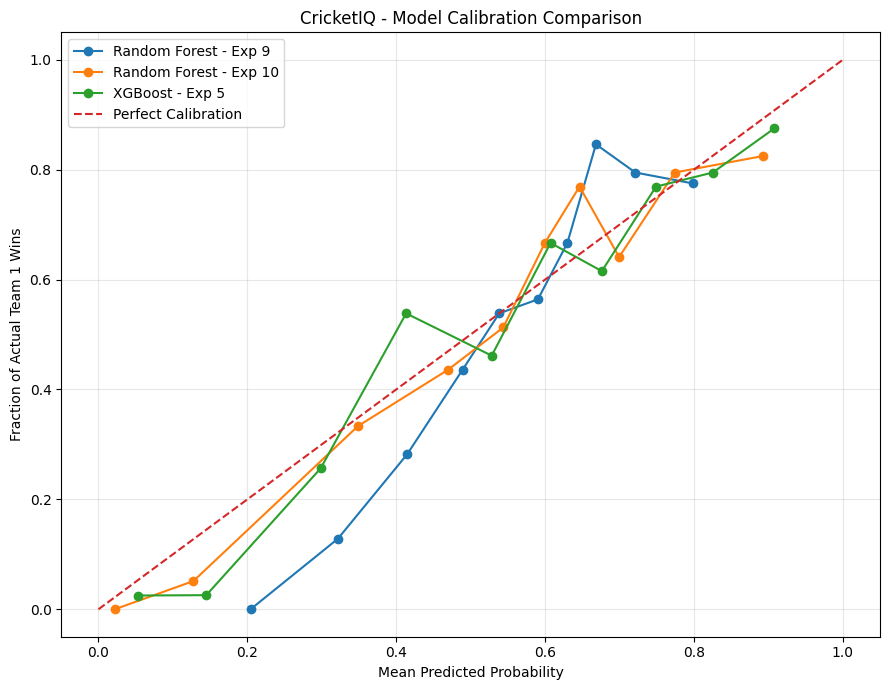

In [18]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Store finalist predictions
calibration_models = {
    "Random Forest - Exp 9": rf_exp9_val_prob,
    "Random Forest - Exp 10": rf_exp10_val_prob,
    "XGBoost - Exp 5": xgb_best_val_prob
}

# Plot calibration curves
plt.figure(figsize=(9, 7))

for model_name, probabilities in calibration_models.items():

    fraction_positive, mean_predicted = calibration_curve(
        y_validation,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=model_name
    )

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Actual Team 1 Wins")
plt.title("CricketIQ - Model Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
def calculate_ece(y_true, y_prob, n_bins=10):

    calibration_data = pd.DataFrame({
        "actual": y_true,
        "probability": y_prob
    })

    calibration_data["bin"] = pd.qcut(
        calibration_data["probability"],
        q=n_bins,
        duplicates="drop"
    )

    bin_results = calibration_data.groupby(
        "bin", observed=True
    ).agg(
        mean_probability=("probability", "mean"),
        actual_win_rate=("actual", "mean"),
        match_count=("actual", "size")
    )

    bin_results["calibration_error"] = abs(
        bin_results["mean_probability"] -
        bin_results["actual_win_rate"]
    )

    ece = (
        bin_results["calibration_error"] *
        bin_results["match_count"]
    ).sum() / len(calibration_data)

    max_error = bin_results["calibration_error"].max()

    return ece, max_error, bin_results


calibration_results = []

for model_name, probabilities in calibration_models.items():

    ece, max_error, bin_details = calculate_ece(
        y_validation,
        probabilities
    )

    calibration_results.append({
        "Model": model_name,
        "Brier Score": brier_score_loss(
            y_validation, probabilities
        ),
        "ECE": ece,
        "Maximum Bin Error": max_error
    })

calibration_comparison = pd.DataFrame(
    calibration_results
).sort_values("ECE")

display(calibration_comparison.round(4))

,Model,Brier Score,ECE,Maximum Bin Error
1,Random Forest - Exp 10,0.1720,0.0515,0.1229
2,XGBoost - Exp 5,0.1706,0.0584,0.1251
0,Random Forest - Exp 9,0.1871,0.0923,0.2044


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.30, 0.71, 0.05)

threshold_results = []

models_to_analyze = {
    "Random Forest - Exp 10": rf_exp10_val_prob,
    "XGBoost - Exp 5": xgb_best_val_prob
}

for model_name, probabilities in models_to_analyze.items():

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Accuracy": accuracy_score(
                y_validation, predictions
            ),
            "Precision": precision_score(
                y_validation, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_validation, predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_validation, predictions,
                zero_division=0
            )
        })

threshold_results = pd.DataFrame(threshold_results)

display(
    threshold_results.round(4)
)

,Model,Threshold,Accuracy,Precision,Recall,F1
0,Random Forest - Exp 10,0.30,0.7015,0.6299,0.9848,0.7683
1,Random Forest - Exp 10,0.35,0.7143,0.6451,0.9594,0.7714
2,Random Forest - Exp 10,0.40,0.7219,0.6583,0.9289,0.7705
3,Random Forest - Exp 10,0.45,0.7398,0.6806,0.9086,0.7783
4,Random Forest - Exp 10,0.50,0.7423,0.6983,0.8579,0.7699
5,Random Forest - Exp 10,0.55,0.7423,0.7264,0.7817,0.7531
6,Random Forest - Exp 10,0.60,0.7423,0.7667,0.7005,0.7321
7,Random Forest - Exp 10,0.65,0.6760,0.7652,0.5127,0.6140
8,Random Forest - Exp 10,0.70,0.6276,0.7684,0.3706,0.5000
9,XGBoost - Exp 5,0.30,0.7066,0.6385,0.9594,0.7667


In [21]:
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef
)

balanced_results = []

for model_name, probabilities in models_to_analyze.items():

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        balanced_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Accuracy": accuracy_score(
                y_validation, predictions
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_validation, predictions
            ),
            "Macro F1": f1_score(
                y_validation, predictions,
                average="macro"
            ),
            "MCC": matthews_corrcoef(
                y_validation, predictions
            )
        })

balanced_results = pd.DataFrame(balanced_results)

display(
    balanced_results
    .sort_values("Balanced Accuracy", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Model,Threshold,Accuracy,Balanced Accuracy,Macro F1,MCC
0,XGBoost - Exp 5,0.60,0.7449,0.7451,0.7446,0.4916
1,Random Forest - Exp 10,0.60,0.7423,0.7426,0.7420,0.4867
2,Random Forest - Exp 10,0.55,0.7423,0.7421,0.7419,0.4859
3,Random Forest - Exp 10,0.50,0.7423,0.7418,0.7386,0.4974
4,XGBoost - Exp 5,0.40,0.7398,0.7390,0.7327,0.5047
5,Random Forest - Exp 10,0.45,0.7398,0.7389,0.7317,0.5085
6,XGBoost - Exp 5,0.55,0.7347,0.7345,0.7344,0.4701
7,XGBoost - Exp 5,0.50,0.7347,0.7343,0.7333,0.4732
8,XGBoost - Exp 5,0.35,0.7296,0.7285,0.7166,0.5045
9,XGBoost - Exp 5,0.45,0.7270,0.7265,0.7234,0.4648


In [22]:
# Load transformed feature names
feature_names = pd.read_csv(
    MODEL_DIR / "model_feature_names.csv"
)["feature_name"].tolist()

# XGBoost feature importance
xgb_importance = pd.DataFrame({
    "Feature": feature_names,
    "XGBoost Importance": xgb_best_model.feature_importances_
})

# Random Forest feature importance
rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Random Forest Importance": rf_exp10_model.feature_importances_
})

# Merge both models
importance_comparison = xgb_importance.merge(
    rf_importance,
    on="Feature"
)

# Display top 25 XGBoost features
print("TOP 25 XGBOOST FEATURES")
print("=" * 70)

display(
    importance_comparison
    .sort_values("XGBoost Importance", ascending=False)
    .head(25)
    .round(5)
)

# Display top 25 Random Forest features
print("\nTOP 25 RANDOM FOREST FEATURES")
print("=" * 70)

display(
    importance_comparison
    .sort_values("Random Forest Importance", ascending=False)
    .head(25)
    .round(5)
)

TOP 25 XGBOOST FEATURES


,Feature,XGBoost Importance,Random Forest Importance
268,numeric__team_2_player_recorded_players,0.03746,0.08541
147,numeric__team_1_player_player_coverage_ratio,0.02584,0.02534
269,numeric__team_2_player_player_records,0.02065,0.08960
146,numeric__team_1_player_player_records,0.01627,0.02486
145,numeric__team_1_player_recorded_players,0.01614,0.03521
24,numeric__elo_difference,0.01582,0.07937
2,numeric__win_pct_difference,0.01280,0.03008
6,numeric__team_1_h2h_win_pct,0.01142,0.00618
7,numeric__team_2_h2h_win_pct,0.00909,0.00629
87,numeric__team_1_player_pre_match_career_bowlin...,0.00854,0.00067



TOP 25 RANDOM FOREST FEATURES


,Feature,XGBoost Importance,Random Forest Importance
269,numeric__team_2_player_player_records,0.02065,0.08960
268,numeric__team_2_player_recorded_players,0.03746,0.08541
24,numeric__elo_difference,0.01582,0.07937
270,numeric__team_2_player_player_coverage_ratio,0.00384,0.06262
145,numeric__team_1_player_recorded_players,0.01614,0.03521
2,numeric__win_pct_difference,0.01280,0.03008
147,numeric__team_1_player_player_coverage_ratio,0.02584,0.02534
146,numeric__team_1_player_player_records,0.01627,0.02486
636,categorical__team_2_player_full_player_coverag...,0.00346,0.01629
635,categorical__team_2_player_full_player_coverag...,0.00738,0.01443


In [23]:
# Display complete feature names without truncation
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 100)

# Top 25 XGBoost features
top_xgb_features = (
    importance_comparison
    .sort_values("XGBoost Importance", ascending=False)
    .head(25)
)

print("TOP 25 XGBOOST FEATURES - COMPLETE NAMES")
display(top_xgb_features)

# Top 25 Random Forest features
top_rf_features = (
    importance_comparison
    .sort_values("Random Forest Importance", ascending=False)
    .head(25)
)

print("\nTOP 25 RANDOM FOREST FEATURES - COMPLETE NAMES")
display(top_rf_features)

# Specifically inspect player coverage features
coverage_features = importance_comparison[
    importance_comparison["Feature"].str.contains(
        "recorded_players|player_records|coverage_ratio|full_player_coverage",
        case=False,
        regex=True
    )
].sort_values("XGBoost Importance", ascending=False)

print("\nPLAYER COVERAGE FEATURE IMPORTANCE")
display(coverage_features)

TOP 25 XGBOOST FEATURES - COMPLETE NAMES


,Feature,XGBoost Importance,Random Forest Importance
268,numeric__team_2_player_recorded_players,0.037460,0.085408
147,numeric__team_1_player_player_coverage_ratio,0.025841,0.025335
269,numeric__team_2_player_player_records,0.020648,0.089602
146,numeric__team_1_player_player_records,0.016265,0.024861
145,numeric__team_1_player_recorded_players,0.016138,0.035205
24,numeric__elo_difference,0.015820,0.079365
2,numeric__win_pct_difference,0.012798,0.030082
6,numeric__team_1_h2h_win_pct,0.011422,0.006180
7,numeric__team_2_h2h_win_pct,0.009088,0.006289
87,numeric__team_1_player_pre_match_career_bowling_runs_conceded_sum,0.008542,0.000673



TOP 25 RANDOM FOREST FEATURES - COMPLETE NAMES


,Feature,XGBoost Importance,Random Forest Importance
269,numeric__team_2_player_player_records,0.020648,0.089602
268,numeric__team_2_player_recorded_players,0.037460,0.085408
24,numeric__elo_difference,0.015820,0.079365
270,numeric__team_2_player_player_coverage_ratio,0.003838,0.062615
145,numeric__team_1_player_recorded_players,0.016138,0.035205
2,numeric__win_pct_difference,0.012798,0.030082
147,numeric__team_1_player_player_coverage_ratio,0.025841,0.025335
146,numeric__team_1_player_player_records,0.016265,0.024861
636,categorical__team_2_player_full_player_coverage_True,0.003458,0.016287
635,categorical__team_2_player_full_player_coverage_False,0.007381,0.014430



PLAYER COVERAGE FEATURE IMPORTANCE


,Feature,XGBoost Importance,Random Forest Importance
268,numeric__team_2_player_recorded_players,0.037460,0.085408
147,numeric__team_1_player_player_coverage_ratio,0.025841,0.025335
269,numeric__team_2_player_player_records,0.020648,0.089602
146,numeric__team_1_player_player_records,0.016265,0.024861
145,numeric__team_1_player_recorded_players,0.016138,0.035205
634,categorical__team_1_player_full_player_coverage_True,0.008368,0.006400
635,categorical__team_2_player_full_player_coverage_False,0.007381,0.014430
633,categorical__team_1_player_full_player_coverage_False,0.004643,0.008514
270,numeric__team_2_player_player_coverage_ratio,0.003838,0.062615
636,categorical__team_2_player_full_player_coverage_True,0.003458,0.016287


In [24]:
# Load original team-level player features
team_player_features = pd.read_csv(
    PROJECT_ROOT / "data" / "features" / "player_data" /
    "cricketiq_team_match_player_features.csv",
    low_memory=False
)

# Identify relevant columns
coverage_columns = [
    col for col in team_player_features.columns
    if any(term in col.lower() for term in [
        "recorded_players",
        "player_records",
        "coverage_ratio",
        "full_player_coverage",
        "low_player_coverage",
        "has_player_data"
    ])
]

print("PLAYER COVERAGE SOURCE COLUMNS")
print("=" * 70)

for col in coverage_columns:
    print(
        f"{col:<55} | "
        f"dtype: {team_player_features[col].dtype}"
    )

print("\nSAMPLE PLAYER COVERAGE RECORDS")
print("=" * 70)

display(
    team_player_features[
        ["match_date", "team", "opponent"] + coverage_columns
    ].head(15)
)

print("\nSUMMARY STATISTICS")
print("=" * 70)

display(
    team_player_features[coverage_columns].describe(include="all").T
)

PLAYER COVERAGE SOURCE COLUMNS
recorded_players                                        | dtype: int64
player_records                                          | dtype: int64
has_player_data                                         | dtype: bool
low_player_coverage                                     | dtype: bool
full_player_coverage                                    | dtype: bool
player_coverage_ratio                                   | dtype: float64

SAMPLE PLAYER COVERAGE RECORDS


,match_date,team,opponent,recorded_players,player_records,has_player_data,low_player_coverage,full_player_coverage,player_coverage_ratio
0,2010-07-03,Afghanistan,Ireland,11,11,True,False,True,1.000000
1,2010-07-03,Ireland,Afghanistan,11,11,True,False,True,1.000000
2,2012-02-10,Afghanistan,Pakistan,11,11,True,False,True,1.000000
3,2012-02-10,Pakistan,Afghanistan,10,10,True,False,False,0.909091
4,2012-07-05,Afghanistan,Ireland,11,11,True,False,True,1.000000
5,2012-07-05,Ireland,Afghanistan,11,11,True,False,True,1.000000
6,2012-08-25,Afghanistan,Australia,11,11,True,False,True,1.000000
7,2012-08-25,Australia,Afghanistan,11,11,True,False,True,1.000000
8,2014-02-27,Afghanistan,Pakistan,11,11,True,False,True,1.000000
9,2014-02-27,Pakistan,Afghanistan,11,11,True,False,True,1.000000



SUMMARY STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
recorded_players,5496.0,NaN,NaN,NaN,10.611172,1.190811,1.0,11.0,11.0,11.0,12.0
player_records,5496.0,NaN,NaN,NaN,10.611172,1.190811,1.0,11.0,11.0,11.0,12.0
has_player_data,5496,1,True,5496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
low_player_coverage,5496,2,False,5379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
full_player_coverage,5496,2,True,4460,NaN,NaN,NaN,NaN,NaN,NaN,NaN
player_coverage_ratio,5496.0,NaN,NaN,NaN,0.964652,0.108256,0.090909,1.0,1.0,1.0,1.090909


In [25]:
coverage_mask = importance_comparison["Feature"].str.contains(
    "recorded_players|player_records|coverage_ratio|full_player_coverage|low_player_coverage|has_player_data",
    case=False,
    regex=True
)

coverage_importance = importance_comparison[coverage_mask]

total_xgb_importance = (
    importance_comparison["XGBoost Importance"].sum()
)

total_rf_importance = (
    importance_comparison["Random Forest Importance"].sum()
)

coverage_xgb = (
    coverage_importance["XGBoost Importance"].sum()
)

coverage_rf = (
    coverage_importance["Random Forest Importance"].sum()
)

print("PLAYER COVERAGE IMPORTANCE")
print("=" * 60)

print(
    f"XGBoost: {coverage_xgb:.4f} "
    f"({coverage_xgb / total_xgb_importance * 100:.2f}%)"
)

print(
    f"Random Forest: {coverage_rf:.4f} "
    f"({coverage_rf / total_rf_importance * 100:.2f}%)"
)

print("\nNumber of coverage-related transformed features:")
print(len(coverage_importance))

PLAYER COVERAGE IMPORTANCE
XGBoost: 0.1440 (14.40%)
Random Forest: 0.3687 (36.87%)

Number of coverage-related transformed features:
10


In [26]:
# Reload the original integrated match dataset
integrated_df = pd.read_csv(
    PROJECT_ROOT / "data" / "features" /
    "cricketiq_integrated_match_features.csv",
    low_memory=False
)

# Convert match date
integrated_df["match_date"] = pd.to_datetime(
    integrated_df["match_date"],
    errors="coerce"
)

# Identify player-coverage-related columns
coverage_tokens = [
    "recorded_players",
    "player_records",
    "coverage_ratio",
    "full_player_coverage",
    "low_player_coverage",
    "has_player_data"
]

coverage_columns = [
    col for col in integrated_df.columns
    if col.startswith(("team_1_player_", "team_2_player_"))
    and any(token in col.lower() for token in coverage_tokens)
]

print("INTEGRATED DATASET")
print("=" * 60)
print("Shape:", integrated_df.shape)
print("Date range:",
      integrated_df["match_date"].min(),
      "to",
      integrated_df["match_date"].max())

print("\nCOVERAGE FEATURES TO EXCLUDE")
print("=" * 60)

for col in coverage_columns:
    print(col)

print("\nTotal coverage columns:", len(coverage_columns))

# Check target and chronological split boundaries
print("\nTARGET AND SPLIT CHECK")
print("=" * 60)
print("Target column exists:", "team_1_win" in integrated_df.columns)
print("Rows with valid target:",
      integrated_df["team_1_win"].notna().sum())

INTEGRATED DATASET
Shape: (2753, 294)
Date range: 2002-06-27 00:00:00 to 2026-10-25 00:00:00

COVERAGE FEATURES TO EXCLUDE
team_1_player_recorded_players
team_1_player_player_records
team_1_player_has_player_data
team_1_player_low_player_coverage
team_1_player_full_player_coverage
team_1_player_player_coverage_ratio
team_2_player_recorded_players
team_2_player_player_records
team_2_player_has_player_data
team_2_player_low_player_coverage
team_2_player_full_player_coverage
team_2_player_player_coverage_ratio

Total coverage columns: 12

TARGET AND SPLIT CHECK
Target column exists: True
Rows with valid target: 2614


In [27]:
# Keep only matches with a decisive binary outcome
model_df = integrated_df[
    integrated_df["team_1_win"].notna()
].copy()

# Preserve chronological ordering
model_df = model_df.sort_values(
    ["match_date", "match_id"]
).reset_index(drop=True)

# Recreate the original chronological split boundaries
train_end = pd.Timestamp("2019-10-02")
validation_end = pd.Timestamp("2023-09-06")

train_df = model_df[model_df["match_date"] <= train_end].copy()

validation_df = model_df[
    (model_df["match_date"] > train_end) &
    (model_df["match_date"] <= validation_end)
].copy()

test_df = model_df[
    model_df["match_date"] > validation_end
].copy()

# Remove target, identifiers, post-match outcomes, toss information,
# metadata, and all player-coverage-related features
excluded_columns = [
    "team_1_win",
    "winner",
    "result_type",
    "match_id",
    "integration_key",
    "toss_winner",
    "toss_decision",
    "match_date",
    "source",
    "city",
    "city_original",
    "has_player_features"
]

excluded_columns += coverage_columns

# Keep only columns that actually exist
excluded_columns = [
    col for col in excluded_columns
    if col in model_df.columns
]

# Build raw feature datasets
X_train_raw = train_df.drop(columns=excluded_columns)
X_validation_raw = validation_df.drop(columns=excluded_columns)
X_test_raw = test_df.drop(columns=excluded_columns)

# Targets
y_train_clean = train_df["team_1_win"].astype(int)
y_validation_clean = validation_df["team_1_win"].astype(int)
y_test_clean = test_df["team_1_win"].astype(int)

# Identify categorical and numerical columns
categorical_columns = X_train_raw.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_columns = [
    col for col in X_train_raw.columns
    if col not in categorical_columns
]

# Check for constant features in training data
constant_columns = [
    col for col in X_train_raw.columns
    if X_train_raw[col].nunique(dropna=False) <= 1
]

print("LEAKAGE-SAFE DATASET CHECK")
print("=" * 60)

print("Training:", X_train_raw.shape)
print("Validation:", X_validation_raw.shape)
print("Test:", X_test_raw.shape)

print("\nTarget distributions:")
print("Train:\n", y_train_clean.value_counts().sort_index())
print("Validation:\n", y_validation_clean.value_counts().sort_index())
print("Test:\n", y_test_clean.value_counts().sort_index())

print("\nFeature counts:")
print("Total:", X_train_raw.shape[1])
print("Categorical:", len(categorical_columns))
print("Numerical:", len(numerical_columns))

print("\nConstant training features:", constant_columns)
print("\nCategorical columns:")
print(categorical_columns)

print("\nCoverage columns remaining:",
      [col for col in X_train_raw.columns
       if any(token in col.lower() for token in coverage_tokens)])

LEAKAGE-SAFE DATASET CHECK
Training: (1830, 270)
Validation: (392, 270)
Test: (392, 270)

Target distributions:
Train:
 team_1_win
0     806
1    1024
Name: count, dtype: int64
Validation:
 team_1_win
0    195
1    197
Name: count, dtype: int64
Test:
 team_1_win
0    195
1    197
Name: count, dtype: int64

Feature counts:
Total: 270
Categorical: 5
Numerical: 265

Constant training features: []

Categorical columns:
['team_1', 'team_2', 'venue', 'city_standard', 'venue_country']

Coverage columns remaining: []


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import joblib
import json
import numpy as np

# Work on copies so the original raw datasets remain unchanged
X_train_clean = X_train_raw.copy()
X_validation_clean = X_validation_raw.copy()
X_test_clean = X_test_raw.copy()

# Identify common venues using TRAINING DATA ONLY
venue_counts = X_train_clean["venue"].value_counts()
common_venues = venue_counts[venue_counts >= 5].index

# Map rare and unseen venues to Other
for dataset in [X_train_clean, X_validation_clean, X_test_clean]:
    dataset["venue"] = dataset["venue"].where(
        dataset["venue"].isin(common_venues),
        "Other"
    )

print("Common venues retained:", len(common_venues))

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor_clean = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numerical_columns),
        ("categorical", categorical_pipeline, categorical_columns)
    ],
    remainder="drop",
    sparse_threshold=0.0
)

# Fit ONLY on training data
X_train_clean_processed = preprocessor_clean.fit_transform(X_train_clean)

# Transform validation and test without fitting
X_validation_clean_processed = preprocessor_clean.transform(X_validation_clean)
X_test_clean_processed = preprocessor_clean.transform(X_test_clean)

# Create a separate output directory
CLEAN_MODEL_DIR = (
    PROJECT_ROOT / "data" / "processed" / "model_ready_pre_match"
)
CLEAN_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save transformed feature matrices
np.save(CLEAN_MODEL_DIR / "X_train.npy", X_train_clean_processed)
np.save(CLEAN_MODEL_DIR / "X_validation.npy", X_validation_clean_processed)
np.save(CLEAN_MODEL_DIR / "X_test.npy", X_test_clean_processed)

# Save target arrays
np.save(CLEAN_MODEL_DIR / "y_train.npy", y_train_clean.to_numpy())
np.save(CLEAN_MODEL_DIR / "y_validation.npy", y_validation_clean.to_numpy())
np.save(CLEAN_MODEL_DIR / "y_test.npy", y_test_clean.to_numpy())

# Save fitted preprocessor
joblib.dump(
    preprocessor_clean,
    CLEAN_MODEL_DIR / "cricketiq_preprocessor.joblib"
)

# Save transformed feature names
feature_names_clean = preprocessor_clean.get_feature_names_out()

pd.DataFrame({
    "feature_name": feature_names_clean
}).to_csv(
    CLEAN_MODEL_DIR / "model_feature_names.csv",
    index=False
)

# Save basic metadata
metadata_clean = {
    "training_rows": len(X_train_clean),
    "validation_rows": len(X_validation_clean),
    "test_rows": len(X_test_clean),
    "raw_feature_count": X_train_clean.shape[1],
    "processed_feature_count": len(feature_names_clean),
    "categorical_columns": categorical_columns,
    "numerical_columns": numerical_columns,
    "rare_venue_threshold": 5,
    "common_venue_count": len(common_venues),
    "coverage_features_removed": coverage_columns,
    "train_end_date": str(train_end.date()),
    "validation_end_date": str(validation_end.date())
}

with open(CLEAN_MODEL_DIR / "metadata.json", "w") as f:
    json.dump(metadata_clean, f, indent=4)

print("\nPREPROCESSING COMPLETE")
print("=" * 60)
print("Training shape:", X_train_clean_processed.shape)
print("Validation shape:", X_validation_clean_processed.shape)
print("Test shape:", X_test_clean_processed.shape)
print("Feature names:", len(feature_names_clean))
print("Saved to:", CLEAN_MODEL_DIR)

Common venues retained: 94

PREPROCESSING COMPLETE
Training shape: (1830, 639)
Validation shape: (392, 639)
Test shape: (392, 639)
Feature names: 639
Saved to: C:\CricIQ\data\processed\model_ready_pre_match


In [29]:
# Load the newly saved arrays
X_train_clean_processed = np.load(CLEAN_MODEL_DIR / "X_train.npy")
X_validation_clean_processed = np.load(CLEAN_MODEL_DIR / "X_validation.npy")
X_test_clean_processed = np.load(CLEAN_MODEL_DIR / "X_test.npy")

y_train_clean = np.load(CLEAN_MODEL_DIR / "y_train.npy")
y_validation_clean = np.load(CLEAN_MODEL_DIR / "y_validation.npy")
y_test_clean = np.load(CLEAN_MODEL_DIR / "y_test.npy")

feature_names_clean = pd.read_csv(
    CLEAN_MODEL_DIR / "model_feature_names.csv"
)["feature_name"].tolist()

# Check for coverage-related features in transformed names
coverage_terms = [
    "recorded_players",
    "player_records",
    "coverage_ratio",
    "full_player_coverage",
    "low_player_coverage",
    "has_player_data"
]

remaining_coverage_features = [
    feature for feature in feature_names_clean
    if any(term in feature.lower() for term in coverage_terms)
]

# Validation checks
print("FINAL DATASET VALIDATION")
print("=" * 60)

print("Training:", X_train_clean_processed.shape, y_train_clean.shape)
print("Validation:", X_validation_clean_processed.shape, y_validation_clean.shape)
print("Test:", X_test_clean_processed.shape, y_test_clean.shape)

print("\nNaN checks:")
print("Train:", np.isnan(X_train_clean_processed).sum())
print("Validation:", np.isnan(X_validation_clean_processed).sum())
print("Test:", np.isnan(X_test_clean_processed).sum())

print("\nInfinite value checks:")
print("Train:", np.isinf(X_train_clean_processed).sum())
print("Validation:", np.isinf(X_validation_clean_processed).sum())
print("Test:", np.isinf(X_test_clean_processed).sum())

print("\nRemaining coverage features:", remaining_coverage_features)
print("Unique target labels:", np.unique(y_train_clean))

assert X_train_clean_processed.shape[0] == len(y_train_clean)
assert X_validation_clean_processed.shape[0] == len(y_validation_clean)
assert X_test_clean_processed.shape[0] == len(y_test_clean)
assert X_train_clean_processed.shape[1] == len(feature_names_clean)
assert not remaining_coverage_features
assert np.isfinite(X_train_clean_processed).all()
assert np.isfinite(X_validation_clean_processed).all()
assert np.isfinite(X_test_clean_processed).all()

print("\nAll validation checks passed.")

FINAL DATASET VALIDATION
Training: (1830, 639) (1830,)
Validation: (392, 639) (392,)
Test: (392, 639) (392,)

NaN checks:
Train: 0
Validation: 0
Test: 0

Infinite value checks:
Train: 0
Validation: 0
Test: 0

Remaining coverage features: []
Unique target labels: [0 1]

All validation checks passed.


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    brier_score_loss,
    confusion_matrix
)

# Initialize Logistic Regression
logistic_clean_model = LogisticRegression(
    max_iter=2000,
    C=1.0,
    solver="lbfgs",
    class_weight=None,
    random_state=42
)

# Train on corrected training data
logistic_clean_model.fit(
    X_train_clean_processed,
    y_train_clean
)

# Generate predictions and probabilities
logistic_clean_train_pred = logistic_clean_model.predict(
    X_train_clean_processed
)
logistic_clean_val_pred = logistic_clean_model.predict(
    X_validation_clean_processed
)

logistic_clean_train_prob = logistic_clean_model.predict_proba(
    X_train_clean_processed
)[:, 1]
logistic_clean_val_prob = logistic_clean_model.predict_proba(
    X_validation_clean_processed
)[:, 1]


# Evaluation function
def evaluate_clean_model(y_true, predictions, probabilities):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "LogLoss": log_loss(y_true, probabilities),
        "Brier Score": brier_score_loss(y_true, probabilities)
    }


# Evaluate training and validation performance
logistic_clean_train_metrics = evaluate_clean_model(
    y_train_clean,
    logistic_clean_train_pred,
    logistic_clean_train_prob
)

logistic_clean_val_metrics = evaluate_clean_model(
    y_validation_clean,
    logistic_clean_val_pred,
    logistic_clean_val_prob
)

print("LOGISTIC REGRESSION — LEAKAGE-SAFE RESULTS")
print("=" * 65)

print("\nTRAINING METRICS")
for metric, value in logistic_clean_train_metrics.items():
    print(f"{metric:15}: {value:.4f}")

print("\nVALIDATION METRICS")
for metric, value in logistic_clean_val_metrics.items():
    print(f"{metric:15}: {value:.4f}")

print("\nVALIDATION CONFUSION MATRIX")
print(confusion_matrix(y_validation_clean, logistic_clean_val_pred))

LOGISTIC REGRESSION — LEAKAGE-SAFE RESULTS

TRAINING METRICS
Accuracy       : 0.8219
Precision      : 0.8243
Recall         : 0.8662
F1             : 0.8448
ROC-AUC        : 0.9177
LogLoss        : 0.3627
Brier Score    : 0.1158

VALIDATION METRICS
Accuracy       : 0.6684
Precision      : 0.6463
Recall         : 0.7513
F1             : 0.6948
ROC-AUC        : 0.7551
LogLoss        : 0.6295
Brier Score    : 0.2132

VALIDATION CONFUSION MATRIX
[[114  81]
 [ 49 148]]


In [31]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
rf_clean_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=10,
    max_features=0.5,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

# Train
rf_clean_model.fit(
    X_train_clean_processed,
    y_train_clean
)

# Predictions
rf_clean_train_pred = rf_clean_model.predict(X_train_clean_processed)
rf_clean_val_pred = rf_clean_model.predict(X_validation_clean_processed)

# Probabilities
rf_clean_train_prob = rf_clean_model.predict_proba(
    X_train_clean_processed
)[:, 1]

rf_clean_val_prob = rf_clean_model.predict_proba(
    X_validation_clean_processed
)[:, 1]

# Evaluate
rf_clean_train_metrics = evaluate_clean_model(
    y_train_clean,
    rf_clean_train_pred,
    rf_clean_train_prob
)

rf_clean_val_metrics = evaluate_clean_model(
    y_validation_clean,
    rf_clean_val_pred,
    rf_clean_val_prob
)

print("RANDOM FOREST — LEAKAGE-SAFE RESULTS")
print("=" * 65)

print("\nTRAINING METRICS")
for metric, value in rf_clean_train_metrics.items():
    print(f"{metric:15}: {value:.4f}")

print("\nVALIDATION METRICS")
for metric, value in rf_clean_val_metrics.items():
    print(f"{metric:15}: {value:.4f}")

print("\nVALIDATION CONFUSION MATRIX")
print(confusion_matrix(y_validation_clean, rf_clean_val_pred))

RANDOM FOREST — LEAKAGE-SAFE RESULTS

TRAINING METRICS
Accuracy       : 0.9295
Precision      : 0.9194
Recall         : 0.9580
F1             : 0.9383
ROC-AUC        : 0.9839
LogLoss        : 0.3553
Brier Score    : 0.0998

VALIDATION METRICS
Accuracy       : 0.6862
Precision      : 0.6595
Recall         : 0.7766
F1             : 0.7133
ROC-AUC        : 0.7446
LogLoss        : 0.6067
Brier Score    : 0.2083

VALIDATION CONFUSION MATRIX
[[116  79]
 [ 44 153]]


In [32]:
from xgboost import XGBClassifier

# Initialize XGBoost
xgb_clean_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_clean_model.fit(
    X_train_clean_processed,
    y_train_clean
)

# Predictions
xgb_clean_train_pred = xgb_clean_model.predict(
    X_train_clean_processed
)
xgb_clean_val_pred = xgb_clean_model.predict(
    X_validation_clean_processed
)

# Probabilities
xgb_clean_train_prob = xgb_clean_model.predict_proba(
    X_train_clean_processed
)[:, 1]

xgb_clean_val_prob = xgb_clean_model.predict_proba(
    X_validation_clean_processed
)[:, 1]

# Evaluate
xgb_clean_train_metrics = evaluate_clean_model(
    y_train_clean,
    xgb_clean_train_pred,
    xgb_clean_train_prob
)

xgb_clean_val_metrics = evaluate_clean_model(
    y_validation_clean,
    xgb_clean_val_pred,
    xgb_clean_val_prob
)

print("XGBOOST — LEAKAGE-SAFE RESULTS")
print("=" * 65)

print("\nTRAINING METRICS")
for metric, value in xgb_clean_train_metrics.items():
    print(f"{metric:15}: {value:.4f}")

print("\nVALIDATION METRICS")
for metric, value in xgb_clean_val_metrics.items():
    print(f"{metric:15}: {value:.4f}")

print("\nVALIDATION CONFUSION MATRIX")
print(confusion_matrix(y_validation_clean, xgb_clean_val_pred))

XGBOOST — LEAKAGE-SAFE RESULTS

TRAINING METRICS
Accuracy       : 0.8459
Precision      : 0.8330
Recall         : 0.9062
F1             : 0.8681
ROC-AUC        : 0.9308
LogLoss        : 0.4013
Brier Score    : 0.1236

VALIDATION METRICS
Accuracy       : 0.6964
Precision      : 0.6653
Recall         : 0.7970
F1             : 0.7252
ROC-AUC        : 0.7740
LogLoss        : 0.5696
Brier Score    : 0.1936

VALIDATION CONFUSION MATRIX
[[116  79]
 [ 40 157]]


In [34]:
# Collect validation metrics
clean_model_comparison = pd.DataFrame({
    "Logistic Regression": logistic_clean_val_metrics,
    "Random Forest": rf_clean_val_metrics,
    "XGBoost": xgb_clean_val_metrics
}).T

# Sort by ROC-AUC
clean_model_comparison = clean_model_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
)

print("LEAKAGE-SAFE MODEL COMPARISON")
print("=" * 75)
display(clean_model_comparison.round(4))

print("\nBEST MODEL BY METRIC")
print("=" * 75)

for metric in clean_model_comparison.columns:
    if metric in ["LogLoss", "Brier Score"]:
        best_model = clean_model_comparison[metric].idxmin()
    else:
        best_model = clean_model_comparison[metric].idxmax()

    print(f"{metric:15}: {best_model} "
          f"({clean_model_comparison.loc[best_model, metric]:.4f})")

LEAKAGE-SAFE MODEL COMPARISON


,Accuracy,Precision,Recall,F1,ROC-AUC,LogLoss,Brier Score
XGBoost,0.6964,0.6653,0.7970,0.7252,0.7740,0.5696,0.1936
Logistic Regression,0.6684,0.6463,0.7513,0.6948,0.7551,0.6295,0.2132
Random Forest,0.6862,0.6595,0.7766,0.7133,0.7446,0.6067,0.2083



BEST MODEL BY METRIC
Accuracy       : XGBoost (0.6964)
Precision      : XGBoost (0.6653)
Recall         : XGBoost (0.7970)
F1             : XGBoost (0.7252)
ROC-AUC        : XGBoost (0.7740)
LogLoss        : XGBoost (0.5696)
Brier Score    : XGBoost (0.1936)


In [35]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

# Expanding-window chronological cross-validation
tscv = TimeSeriesSplit(n_splits=4)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train_clean_processed), start=1
):
    X_fold_train = X_train_clean_processed[train_idx]
    X_fold_val = X_train_clean_processed[val_idx]

    y_fold_train = y_train_clean[train_idx]
    y_fold_val = y_train_clean[val_idx]

    fold_model = XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    fold_model.fit(X_fold_train, y_fold_train)

    fold_probabilities = fold_model.predict_proba(X_fold_val)[:, 1]

    fold_auc = roc_auc_score(
        y_fold_val,
        fold_probabilities
    )

    cv_results.append({
        "Fold": fold,
        "Training Matches": len(train_idx),
        "Validation Matches": len(val_idx),
        "Validation ROC-AUC": fold_auc
    })

cv_results_df = pd.DataFrame(cv_results)

print("XGBOOST — TEMPORAL CROSS-VALIDATION")
print("=" * 65)
display(cv_results_df.round(4))

print("\nCROSS-VALIDATION SUMMARY")
print("=" * 65)
print(f"Mean ROC-AUC: {cv_results_df['Validation ROC-AUC'].mean():.4f}")
print(f"Std ROC-AUC : {cv_results_df['Validation ROC-AUC'].std():.4f}")

XGBOOST — TEMPORAL CROSS-VALIDATION


,Fold,Training Matches,Validation Matches,Validation ROC-AUC
0,1,366,366,0.7415
1,2,732,366,0.7418
2,3,1098,366,0.7675
3,4,1464,366,0.7672



CROSS-VALIDATION SUMMARY
Mean ROC-AUC: 0.7545
Std ROC-AUC : 0.0148


In [36]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

tscv = TimeSeriesSplit(n_splits=4)

cv_results_clean = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train_raw), start=1
):
    # Separate raw data for this fold
    X_fold_train = X_train_raw.iloc[train_idx].copy()
    X_fold_val = X_train_raw.iloc[val_idx].copy()

    y_fold_train = y_train_clean[train_idx]
    y_fold_val = y_train_clean[val_idx]

    # Learn common venues using this fold's training data only
    fold_venue_counts = X_fold_train["venue"].value_counts()
    fold_common_venues = fold_venue_counts[
        fold_venue_counts >= 5
    ].index

    X_fold_train["venue"] = X_fold_train["venue"].where(
        X_fold_train["venue"].isin(fold_common_venues),
        "Other"
    )

    X_fold_val["venue"] = X_fold_val["venue"].where(
        X_fold_val["venue"].isin(fold_common_venues),
        "Other"
    )

    # Create a fresh, unfitted preprocessor for each fold
    fold_preprocessor = clone(preprocessor_clean)

    # Fit only on fold training data
    X_fold_train_processed = fold_preprocessor.fit_transform(
        X_fold_train
    )

    # Transform fold validation data
    X_fold_val_processed = fold_preprocessor.transform(
        X_fold_val
    )

    # Train XGBoost
    fold_model = XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    fold_model.fit(
        X_fold_train_processed,
        y_fold_train
    )

    # Evaluate on the later fold
    fold_probabilities = fold_model.predict_proba(
        X_fold_val_processed
    )[:, 1]

    fold_auc = roc_auc_score(
        y_fold_val,
        fold_probabilities
    )

    cv_results_clean.append({
        "Fold": fold,
        "Training Matches": len(train_idx),
        "Validation Matches": len(val_idx),
        "Processed Features": X_fold_train_processed.shape[1],
        "Common Venues": len(fold_common_venues),
        "ROC-AUC": fold_auc
    })

# Display results
cv_results_clean_df = pd.DataFrame(cv_results_clean)

print("FOLD-ISOLATED XGBOOST TEMPORAL CROSS-VALIDATION")
print("=" * 75)
display(cv_results_clean_df.round(4))

print("\nCROSS-VALIDATION SUMMARY")
print("=" * 75)
print(
    f"Mean ROC-AUC: "
    f"{cv_results_clean_df['ROC-AUC'].mean():.4f}"
)
print(
    f"Std ROC-AUC : "
    f"{cv_results_clean_df['ROC-AUC'].std():.4f}"
)

FOLD-ISOLATED XGBOOST TEMPORAL CROSS-VALIDATION


,Fold,Training Matches,Validation Matches,Processed Features,Common Venues,ROC-AUC
0,1,366,366,507,27,0.7461
1,2,732,366,562,54,0.7363
2,3,1098,366,591,71,0.7616
3,4,1464,366,607,80,0.7683



CROSS-VALIDATION SUMMARY
Mean ROC-AUC: 0.7531
Std ROC-AUC : 0.0145


In [37]:
from sklearn.model_selection import TimeSeriesSplit
import pandas as pd

tscv_audit = TimeSeriesSplit(n_splits=4)

fold_boundary_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv_audit.split(X_train_raw), start=1
):
    train_dates = train_df.iloc[train_idx]["match_date"]
    val_dates = train_df.iloc[val_idx]["match_date"]

    train_last_date = train_dates.max()
    val_first_date = val_dates.min()

    # Check whether a date appears in both training and validation
    overlapping_dates = set(train_dates).intersection(set(val_dates))

    fold_boundary_results.append({
        "Fold": fold,
        "Training Last Date": train_last_date.date(),
        "Validation First Date": val_first_date.date(),
        "Overlapping Dates": len(overlapping_dates),
        "Same-Day Leakage Risk": len(overlapping_dates) > 0
    })

fold_boundary_df = pd.DataFrame(fold_boundary_results)

print("SAME-DAY MATCH SPLIT AUDIT")
print("=" * 75)
display(fold_boundary_df)

if fold_boundary_df["Same-Day Leakage Risk"].any():
    print("\nWARNING: At least one fold splits matches from the same date.")
else:
    print("\nAll fold boundaries keep same-day matches together.")

SAME-DAY MATCH SPLIT AUDIT


,Fold,Training Last Date,Validation First Date,Overlapping Dates,Same-Day Leakage Risk
0,1,2007-01-14,2007-01-16,0,False
1,2,2010-03-06,2010-03-06,1,True
2,3,2013-08-29,2013-08-31,0,False
3,4,2016-12-09,2016-12-26,0,False


In [38]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

# Get unique chronological match dates
unique_dates = np.array(
    sorted(train_df["match_date"].dropna().unique())
)

date_splitter = TimeSeriesSplit(n_splits=4)

grouped_cv_results = []

for fold, (train_date_idx, val_date_idx) in enumerate(
    date_splitter.split(unique_dates), start=1
):

    # Identify dates assigned to each side
    fold_train_dates = unique_dates[train_date_idx]
    fold_val_dates = unique_dates[val_date_idx]

    # Convert date groups into row indices
    train_idx = np.flatnonzero(
        train_df["match_date"].isin(fold_train_dates).to_numpy()
    )

    val_idx = np.flatnonzero(
        train_df["match_date"].isin(fold_val_dates).to_numpy()
    )

    # Extract raw features
    X_fold_train = X_train_raw.iloc[train_idx].copy()
    X_fold_val = X_train_raw.iloc[val_idx].copy()

    y_fold_train = y_train_clean[train_idx]
    y_fold_val = y_train_clean[val_idx]

    # Learn common venues from fold training data only
    fold_venue_counts = X_fold_train["venue"].value_counts()

    fold_common_venues = fold_venue_counts[
        fold_venue_counts >= 5
    ].index

    X_fold_train["venue"] = X_fold_train["venue"].where(
        X_fold_train["venue"].isin(fold_common_venues),
        "Other"
    )

    X_fold_val["venue"] = X_fold_val["venue"].where(
        X_fold_val["venue"].isin(fold_common_venues),
        "Other"
    )

    # Fit a fresh preprocessor for this fold
    fold_preprocessor = clone(preprocessor_clean)

    X_fold_train_processed = fold_preprocessor.fit_transform(
        X_fold_train
    )

    X_fold_val_processed = fold_preprocessor.transform(
        X_fold_val
    )

    # Train XGBoost
    fold_model = XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    fold_model.fit(
        X_fold_train_processed,
        y_fold_train
    )

    # Predict probabilities and evaluate
    fold_probabilities = fold_model.predict_proba(
        X_fold_val_processed
    )[:, 1]

    fold_auc = roc_auc_score(
        y_fold_val,
        fold_probabilities
    )

    # Verify that no dates overlap
    overlapping_dates = set(fold_train_dates).intersection(
        set(fold_val_dates)
    )

    grouped_cv_results.append({
        "Fold": fold,
        "Training Matches": len(train_idx),
        "Validation Matches": len(val_idx),
        "Training Last Date": pd.Timestamp(
            fold_train_dates[-1]
        ).date(),
        "Validation First Date": pd.Timestamp(
            fold_val_dates[0]
        ).date(),
        "Overlapping Dates": len(overlapping_dates),
        "ROC-AUC": fold_auc
    })

# Display fold results
grouped_cv_df = pd.DataFrame(grouped_cv_results)

print("DATE-GROUPED, FOLD-ISOLATED XGBOOST CROSS-VALIDATION")
print("=" * 85)
display(grouped_cv_df.round(4))

print("\nCROSS-VALIDATION SUMMARY")
print("=" * 85)

print(
    f"Mean ROC-AUC: {grouped_cv_df['ROC-AUC'].mean():.4f}"
)

print(
    f"Std ROC-AUC : {grouped_cv_df['ROC-AUC'].std():.4f}"
)

print(
    "\nTotal overlapping dates:",
    grouped_cv_df["Overlapping Dates"].sum()
)

assert grouped_cv_df["Overlapping Dates"].sum() == 0

print("\nAll fold boundaries keep same-day matches together.")

DATE-GROUPED, FOLD-ISOLATED XGBOOST CROSS-VALIDATION


,Fold,Training Matches,Validation Matches,Training Last Date,Validation First Date,Overlapping Dates,ROC-AUC
0,1,351,365,2006-12-01,2006-12-02,0,0.7472
1,2,716,359,2010-01-31,2010-02-05,0,0.7355
2,3,1075,375,2013-06-30,2013-07-02,0,0.7685
3,4,1450,380,2016-10-20,2016-10-23,0,0.7654



CROSS-VALIDATION SUMMARY
Mean ROC-AUC: 0.7541
Std ROC-AUC : 0.0156

Total overlapping dates: 0

All fold boundaries keep same-day matches together.


In [39]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score,
    log_loss,
    brier_score_loss
)
import pandas as pd
import numpy as np

# Six controlled configurations
xgb_configurations = [
    {"max_depth": 2, "min_child_weight": 10},
    {"max_depth": 2, "min_child_weight": 20},
    {"max_depth": 3, "min_child_weight": 10},
    {"max_depth": 3, "min_child_weight": 20},
    {"max_depth": 4, "min_child_weight": 10},
    {"max_depth": 4, "min_child_weight": 20}
]

# Recreate date-grouped folds
unique_dates = np.array(
    sorted(train_df["match_date"].dropna().unique())
)

date_splitter = TimeSeriesSplit(n_splits=4)

# Prepare each fold's transformed data once
prepared_folds = []

for fold, (train_date_idx, val_date_idx) in enumerate(
    date_splitter.split(unique_dates), start=1
):

    fold_train_dates = unique_dates[train_date_idx]
    fold_val_dates = unique_dates[val_date_idx]

    train_idx = np.flatnonzero(
        train_df["match_date"].isin(fold_train_dates).to_numpy()
    )

    val_idx = np.flatnonzero(
        train_df["match_date"].isin(fold_val_dates).to_numpy()
    )

    X_fold_train = X_train_raw.iloc[train_idx].copy()
    X_fold_val = X_train_raw.iloc[val_idx].copy()

    y_fold_train = y_train_clean[train_idx]
    y_fold_val = y_train_clean[val_idx]

    # Venue mapping learned only from fold training data
    venue_counts = X_fold_train["venue"].value_counts()
    common_venues_fold = venue_counts[
        venue_counts >= 5
    ].index

    for dataset in [X_fold_train, X_fold_val]:
        dataset["venue"] = dataset["venue"].where(
            dataset["venue"].isin(common_venues_fold),
            "Other"
        )

    # Fold-specific preprocessing
    fold_preprocessor = clone(preprocessor_clean)

    X_fold_train_processed = fold_preprocessor.fit_transform(
        X_fold_train
    )

    X_fold_val_processed = fold_preprocessor.transform(
        X_fold_val
    )

    prepared_folds.append({
        "fold": fold,
        "X_train": X_fold_train_processed,
        "X_val": X_fold_val_processed,
        "y_train": y_fold_train,
        "y_val": y_fold_val
    })

print("PREPARED DATE-GROUPED FOLDS")
print("=" * 60)

for fold_data in prepared_folds:
    print(
        f"Fold {fold_data['fold']}: "
        f"Train={fold_data['X_train'].shape}, "
        f"Validation={fold_data['X_val'].shape}"
    )

print("\nTotal configurations:", len(xgb_configurations))
print("Total model fits:", len(xgb_configurations) * len(prepared_folds))

PREPARED DATE-GROUPED FOLDS
Fold 1: Train=(351, 504), Validation=(365, 504)
Fold 2: Train=(716, 561), Validation=(359, 561)
Fold 3: Train=(1075, 591), Validation=(375, 591)
Fold 4: Train=(1450, 603), Validation=(380, 603)

Total configurations: 6
Total model fits: 24


In [40]:
xgb_tuning_results = []

for config_number, config in enumerate(
    xgb_configurations, start=1
):

    print(
        f"Testing configuration {config_number}/"
        f"{len(xgb_configurations)}: {config}"
    )

    fold_aucs = []
    fold_logloss = []
    fold_briers = []

    for fold_data in prepared_folds:

        model = XGBClassifier(
            n_estimators=300,
            max_depth=config["max_depth"],
            learning_rate=0.03,
            min_child_weight=config["min_child_weight"],
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=2.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            fold_data["X_train"],
            fold_data["y_train"]
        )

        probabilities = model.predict_proba(
            fold_data["X_val"]
        )[:, 1]

        fold_aucs.append(
            roc_auc_score(fold_data["y_val"], probabilities)
        )

        fold_logloss.append(
            log_loss(fold_data["y_val"], probabilities)
        )

        fold_briers.append(
            brier_score_loss(fold_data["y_val"], probabilities)
        )

    xgb_tuning_results.append({
        "Configuration": config_number,
        "Max Depth": config["max_depth"],
        "Min Child Weight": config["min_child_weight"],
        "Mean ROC-AUC": np.mean(fold_aucs),
        "Std ROC-AUC": np.std(fold_aucs, ddof=1),
        "Mean LogLoss": np.mean(fold_logloss),
        "Mean Brier Score": np.mean(fold_briers)
    })

# Display results
xgb_tuning_df = pd.DataFrame(xgb_tuning_results)

xgb_tuning_df = xgb_tuning_df.sort_values(
    by="Mean ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\nXGBOOST HYPERPARAMETER TUNING RESULTS")
print("=" * 85)

display(xgb_tuning_df.round(4))

print("\nBEST CONFIGURATION BY MEAN ROC-AUC")
print("=" * 85)

display(xgb_tuning_df.head(1).round(4))

Testing configuration 1/6: {'max_depth': 2, 'min_child_weight': 10}
Testing configuration 2/6: {'max_depth': 2, 'min_child_weight': 20}
Testing configuration 3/6: {'max_depth': 3, 'min_child_weight': 10}
Testing configuration 4/6: {'max_depth': 3, 'min_child_weight': 20}
Testing configuration 5/6: {'max_depth': 4, 'min_child_weight': 10}
Testing configuration 6/6: {'max_depth': 4, 'min_child_weight': 20}

XGBOOST HYPERPARAMETER TUNING RESULTS


,Configuration,Max Depth,Min Child Weight,Mean ROC-AUC,Std ROC-AUC,Mean LogLoss,Mean Brier Score
0,1,2,10,0.7596,0.0209,0.5710,0.1957
1,5,4,10,0.7571,0.0120,0.5722,0.1970
2,2,2,20,0.7562,0.0199,0.5756,0.1973
3,4,3,20,0.7541,0.0156,0.5764,0.1979
4,3,3,10,0.7534,0.0164,0.5756,0.1983
5,6,4,20,0.7511,0.0141,0.5787,0.1989



BEST CONFIGURATION BY MEAN ROC-AUC


,Configuration,Max Depth,Min Child Weight,Mean ROC-AUC,Std ROC-AUC,Mean LogLoss,Mean Brier Score
0,1,2,10,0.7596,0.0209,0.571,0.1957


In [41]:
comparison_configs = {
    "New (depth=2, child=10)": {
        "max_depth": 2,
        "min_child_weight": 10
    },
    "Previous (depth=3, child=20)": {
        "max_depth": 3,
        "min_child_weight": 20
    }
}

paired_fold_results = []

for config_name, config in comparison_configs.items():

    for fold_data in prepared_folds:

        model = XGBClassifier(
            n_estimators=300,
            max_depth=config["max_depth"],
            learning_rate=0.03,
            min_child_weight=config["min_child_weight"],
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=2.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            fold_data["X_train"],
            fold_data["y_train"]
        )

        probabilities = model.predict_proba(
            fold_data["X_val"]
        )[:, 1]

        paired_fold_results.append({
            "Configuration": config_name,
            "Fold": fold_data["fold"],
            "ROC-AUC": roc_auc_score(
                fold_data["y_val"],
                probabilities
            ),
            "LogLoss": log_loss(
                fold_data["y_val"],
                probabilities
            ),
            "Brier Score": brier_score_loss(
                fold_data["y_val"],
                probabilities
            )
        })

paired_results_df = pd.DataFrame(paired_fold_results)

print("PAIRED FOLD COMPARISON")
print("=" * 75)
display(
    paired_results_df.pivot(
        index="Fold",
        columns="Configuration",
        values="ROC-AUC"
    ).round(4)
)

print("\nAVERAGE METRICS")
print("=" * 75)

display(
    paired_results_df.groupby("Configuration")[
        ["ROC-AUC", "LogLoss", "Brier Score"]
    ].mean().round(4)
)

print("\nROC-AUC DIFFERENCE BY FOLD (NEW - PREVIOUS)")
print("=" * 75)

auc_comparison = paired_results_df.pivot(
    index="Fold",
    columns="Configuration",
    values="ROC-AUC"
)

new_name = "New (depth=2, child=10)"
old_name = "Previous (depth=3, child=20)"

print((auc_comparison[new_name] - auc_comparison[old_name]).round(4))

PAIRED FOLD COMPARISON


Configuration,"New (depth=2, child=10)","Previous (depth=3, child=20)"
Fold,,
1,0.7660,0.7472
2,0.7353,0.7355
3,0.7846,0.7685
4,0.7524,0.7654



AVERAGE METRICS


,ROC-AUC,LogLoss,Brier Score
Configuration,,,
"New (depth=2, child=10)",0.7596,0.5710,0.1957
"Previous (depth=3, child=20)",0.7541,0.5764,0.1979



ROC-AUC DIFFERENCE BY FOLD (NEW - PREVIOUS)
Fold
1    0.0189
2   -0.0002
3    0.0162
4   -0.0130
dtype: float64


In [42]:
# Best configuration from date-grouped cross-validation
xgb_tuned_clean_model = XGBClassifier(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train on the complete training set
xgb_tuned_clean_model.fit(
    X_train_clean_processed,
    y_train_clean
)

# Generate predictions
xgb_tuned_train_pred = xgb_tuned_clean_model.predict(
    X_train_clean_processed
)

xgb_tuned_val_pred = xgb_tuned_clean_model.predict(
    X_validation_clean_processed
)

# Generate probabilities
xgb_tuned_train_prob = xgb_tuned_clean_model.predict_proba(
    X_train_clean_processed
)[:, 1]

xgb_tuned_val_prob = xgb_tuned_clean_model.predict_proba(
    X_validation_clean_processed
)[:, 1]

# Evaluate training and validation performance
xgb_tuned_train_metrics = evaluate_clean_model(
    y_train_clean,
    xgb_tuned_train_pred,
    xgb_tuned_train_prob
)

xgb_tuned_val_metrics = evaluate_clean_model(
    y_validation_clean,
    xgb_tuned_val_pred,
    xgb_tuned_val_prob
)

# Compare with previous XGBoost configuration
xgb_validation_comparison = pd.DataFrame({
    "Previous XGBoost": xgb_clean_val_metrics,
    "Tuned XGBoost": xgb_tuned_val_metrics
}).T

print("TUNED XGBOOST — LEAKAGE-SAFE RESULTS")
print("=" * 70)

print("\nTRAINING METRICS")
for metric, value in xgb_tuned_train_metrics.items():
    print(f"{metric:15}: {value:.4f}")

print("\nVALIDATION METRICS")
for metric, value in xgb_tuned_val_metrics.items():
    print(f"{metric:15}: {value:.4f}")

print("\nPREVIOUS VS TUNED XGBOOST")
print("=" * 70)
display(xgb_validation_comparison.round(4))

print("\nTUNED MODEL CONFUSION MATRIX")
print(confusion_matrix(y_validation_clean, xgb_tuned_val_pred))

TUNED XGBOOST — LEAKAGE-SAFE RESULTS

TRAINING METRICS
Accuracy       : 0.7989
Precision      : 0.7903
Recall         : 0.8721
F1             : 0.8292
ROC-AUC        : 0.8900
LogLoss        : 0.4523
Brier Score    : 0.1446

VALIDATION METRICS
Accuracy       : 0.7117
Precision      : 0.6810
Recall         : 0.8020
F1             : 0.7366
ROC-AUC        : 0.7702
LogLoss        : 0.5739
Brier Score    : 0.1953

PREVIOUS VS TUNED XGBOOST


,Accuracy,Precision,Recall,F1,ROC-AUC,LogLoss,Brier Score
Previous XGBoost,0.6964,0.6653,0.797,0.7252,0.7740,0.5696,0.1936
Tuned XGBoost,0.7117,0.6810,0.802,0.7366,0.7702,0.5739,0.1953



TUNED MODEL CONFUSION MATRIX
[[121  74]
 [ 39 158]]


In [43]:
finalist_metrics = {
    "Logistic Regression": logistic_clean_val_metrics,
    "Random Forest": rf_clean_val_metrics,
    "Previous XGBoost (Depth 3)": xgb_clean_val_metrics,
    "Tuned XGBoost (Depth 2)": xgb_tuned_val_metrics
}

finalist_comparison = pd.DataFrame(finalist_metrics).T

print("CRICKETIQ — LEAKAGE-SAFE FINALIST COMPARISON")
print("=" * 85)

display(finalist_comparison.round(4))

print("\nBEST MODEL BY METRIC")
print("=" * 85)

for metric in finalist_comparison.columns:
    if metric in ["LogLoss", "Brier Score"]:
        winner = finalist_comparison[metric].idxmin()
    else:
        winner = finalist_comparison[metric].idxmax()

    print(
        f"{metric:15}: {winner} "
        f"({finalist_comparison.loc[winner, metric]:.4f})"
    )

# Save the comparison for project documentation
finalist_comparison.to_csv(
    CLEAN_MODEL_DIR / "finalist_model_comparison.csv"
)

print("\nComparison saved successfully.")

CRICKETIQ — LEAKAGE-SAFE FINALIST COMPARISON


,Accuracy,Precision,Recall,F1,ROC-AUC,LogLoss,Brier Score
Logistic Regression,0.6684,0.6463,0.7513,0.6948,0.7551,0.6295,0.2132
Random Forest,0.6862,0.6595,0.7766,0.7133,0.7446,0.6067,0.2083
Previous XGBoost (Depth 3),0.6964,0.6653,0.7970,0.7252,0.7740,0.5696,0.1936
Tuned XGBoost (Depth 2),0.7117,0.6810,0.8020,0.7366,0.7702,0.5739,0.1953



BEST MODEL BY METRIC
Accuracy       : Tuned XGBoost (Depth 2) (0.7117)
Precision      : Tuned XGBoost (Depth 2) (0.6810)
Recall         : Tuned XGBoost (Depth 2) (0.8020)
F1             : Tuned XGBoost (Depth 2) (0.7366)
ROC-AUC        : Previous XGBoost (Depth 3) (0.7740)
LogLoss        : Previous XGBoost (Depth 3) (0.5696)
Brier Score    : Previous XGBoost (Depth 3) (0.1936)

Comparison saved successfully.



Previous XGBoost (Depth 3) — CALIBRATION BINS


,Predicted Probability,Actual Win Rate,Matches
0,0.1504,0.0612,49
1,0.3108,0.2857,49
2,0.4204,0.3469,49
3,0.5273,0.5510,49
4,0.6108,0.5510,49
5,0.6838,0.6735,49
6,0.7673,0.7551,49
7,0.8688,0.7959,49



Tuned XGBoost (Depth 2) — CALIBRATION BINS


,Predicted Probability,Actual Win Rate,Matches
0,0.1661,0.0612,49
1,0.3196,0.2449,49
2,0.4266,0.3673,49
3,0.5234,0.5714,49
4,0.6057,0.5102,49
5,0.6716,0.7347,49
6,0.7548,0.7347,49
7,0.8436,0.7959,49



CALIBRATION SUMMARY


,Brier Score,LogLoss,ECE
Model,,,
Previous XGBoost (Depth 3),0.1936,0.5696,0.0458
Tuned XGBoost (Depth 2),0.1953,0.5739,0.0642


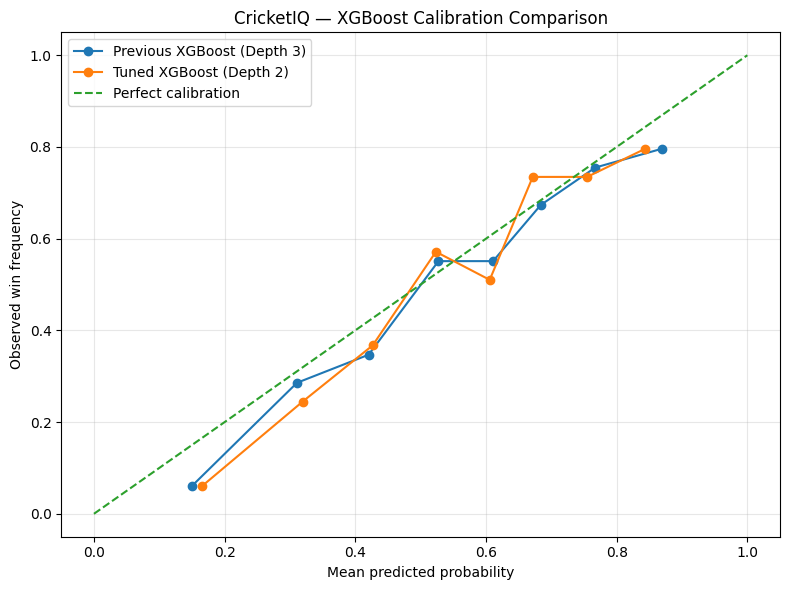

In [44]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss
import numpy as np
import pandas as pd

models_to_calibrate = {
    "Previous XGBoost (Depth 3)": xgb_clean_val_prob,
    "Tuned XGBoost (Depth 2)": xgb_tuned_val_prob
}

calibration_results = []
calibration_data = {}

n_bins = 8

for model_name, probabilities in models_to_calibrate.items():

    # Quantile-based calibration bins
    fraction_positive, mean_predicted = calibration_curve(
        y_validation_clean,
        probabilities,
        n_bins=n_bins,
        strategy="quantile"
    )

    # Calculate Expected Calibration Error
    bin_edges = np.quantile(
        probabilities,
        np.linspace(0, 1, n_bins + 1)
    )

    bin_edges = np.unique(bin_edges)

    ece = 0
    bin_details = []

    for i in range(len(bin_edges) - 1):

        if i == len(bin_edges) - 2:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities <= bin_edges[i + 1])
            )
        else:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities < bin_edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        actual_rate = y_validation_clean[mask].mean()
        predicted_rate = probabilities[mask].mean()

        ece += (
            mask.sum() / len(probabilities)
        ) * abs(actual_rate - predicted_rate)

        bin_details.append({
            "Predicted Probability": predicted_rate,
            "Actual Win Rate": actual_rate,
            "Matches": mask.sum()
        })

    calibration_data[model_name] = (
        mean_predicted,
        fraction_positive
    )

    calibration_results.append({
        "Model": model_name,
        "Brier Score": brier_score_loss(
            y_validation_clean, probabilities
        ),
        "LogLoss": log_loss(
            y_validation_clean, probabilities
        ),
        "ECE": ece
    })

    print(f"\n{model_name} — CALIBRATION BINS")
    display(pd.DataFrame(bin_details).round(4))

# Summary
calibration_summary = pd.DataFrame(
    calibration_results
).set_index("Model")

print("\nCALIBRATION SUMMARY")
print("=" * 65)
display(calibration_summary.round(4))

# Plot calibration curves
plt.figure(figsize=(8, 6))

for model_name, (mean_predicted, fraction_positive) in calibration_data.items():
    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=model_name
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed win frequency")
plt.title("CricketIQ — XGBoost Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score
)

threshold_models = {
    "Previous XGBoost (Depth 3)": xgb_clean_val_prob,
    "Tuned XGBoost (Depth 2)": xgb_tuned_val_prob
}

threshold_values = np.arange(0.35, 0.66, 0.05)

threshold_results = []

for model_name, probabilities in threshold_models.items():

    for threshold in threshold_values:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Accuracy": accuracy_score(
                y_validation_clean, predictions
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_validation_clean, predictions
            ),
            "Macro F1": f1_score(
                y_validation_clean,
                predictions,
                average="macro"
            ),
            "MCC": matthews_corrcoef(
                y_validation_clean, predictions
            ),
            "Precision": precision_score(
                y_validation_clean,
                predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_validation_clean,
                predictions,
                zero_division=0
            )
        })

threshold_comparison_df = pd.DataFrame(threshold_results)

print("THRESHOLD COMPARISON — BOTH XGBOOST FINALISTS")
print("=" * 90)

display(
    threshold_comparison_df.round(4)
)

print("\nBEST THRESHOLD BY MODEL")
print("=" * 90)

for model_name in threshold_models:

    model_results = threshold_comparison_df[
        threshold_comparison_df["Model"] == model_name
    ]

    best_row = model_results.loc[
        model_results["Balanced Accuracy"].idxmax()
    ]

    print(f"\n{model_name}")
    print(best_row.to_string())
    

THRESHOLD COMPARISON — BOTH XGBOOST FINALISTS


,Model,Threshold,Accuracy,Balanced Accuracy,Macro F1,MCC,Precision,Recall
0,Previous XGBoost (Depth 3),0.35,0.6658,0.6644,0.6378,0.3940,0.6086,0.9391
1,Previous XGBoost (Depth 3),0.40,0.6811,0.6801,0.6662,0.3965,0.6295,0.8883
2,Previous XGBoost (Depth 3),0.45,0.7041,0.7033,0.6970,0.4264,0.6588,0.8528
3,Previous XGBoost (Depth 3),0.50,0.6964,0.6959,0.6931,0.4002,0.6653,0.7970
4,Previous XGBoost (Depth 3),0.55,0.6939,0.6938,0.6938,0.3878,0.6897,0.7107
5,Previous XGBoost (Depth 3),0.60,0.7041,0.7043,0.7035,0.4106,0.7288,0.6548
6,Previous XGBoost (Depth 3),0.65,0.6811,0.6818,0.6761,0.3760,0.7466,0.5533
7,Tuned XGBoost (Depth 2),0.35,0.6709,0.6695,0.6422,0.4096,0.6111,0.9492
8,Tuned XGBoost (Depth 2),0.40,0.6786,0.6774,0.6615,0.3960,0.6254,0.8985
9,Tuned XGBoost (Depth 2),0.45,0.7015,0.7007,0.6931,0.4247,0.6538,0.8629



BEST THRESHOLD BY MODEL

Previous XGBoost (Depth 3)
Model                Previous XGBoost (Depth 3)
Threshold                                   0.6
Accuracy                               0.704082
Balanced Accuracy                      0.704334
Macro F1                               0.703456
MCC                                    0.410597
Precision                              0.728814
Recall                                 0.654822

Tuned XGBoost (Depth 2)
Model                Tuned XGBoost (Depth 2)
Threshold                                0.5
Accuracy                            0.711735
Balanced Accuracy                   0.711272
Macro F1                            0.709143
MCC                                 0.429851
Precision                           0.681034
Recall                               0.80203


In [46]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from xgboost import XGBClassifier
import numpy as np
import pandas as pd

# Finalist configurations
finalist_configs = {
    "Previous XGBoost (Depth 3)": {
        "max_depth": 3,
        "min_child_weight": 20
    },
    "Tuned XGBoost (Depth 2)": {
        "max_depth": 2,
        "min_child_weight": 10
    }
}

# Unique chronological dates from training period
unique_dates = np.array(
    sorted(train_df["match_date"].dropna().unique())
)

date_splitter = TimeSeriesSplit(n_splits=4)

# Store out-of-fold predictions
oof_predictions = {
    name: np.full(len(X_train_raw), np.nan)
    for name in finalist_configs
}

oof_fold_numbers = np.full(len(X_train_raw), -1)

for fold, (train_date_idx, val_date_idx) in enumerate(
    date_splitter.split(unique_dates), start=1
):

    fold_train_dates = unique_dates[train_date_idx]
    fold_val_dates = unique_dates[val_date_idx]

    train_idx = np.flatnonzero(
        train_df["match_date"].isin(fold_train_dates).to_numpy()
    )

    val_idx = np.flatnonzero(
        train_df["match_date"].isin(fold_val_dates).to_numpy()
    )

    X_fold_train = X_train_raw.iloc[train_idx].copy()
    X_fold_val = X_train_raw.iloc[val_idx].copy()

    y_fold_train = y_train_clean[train_idx]

    # Learn venue categories from fold training data only
    venue_counts = X_fold_train["venue"].value_counts()
    common_venues_fold = venue_counts[
        venue_counts >= 5
    ].index

    for dataset in [X_fold_train, X_fold_val]:
        dataset["venue"] = dataset["venue"].where(
            dataset["venue"].isin(common_venues_fold),
            "Other"
        )

    # Fit preprocessing only on fold training data
    fold_preprocessor = clone(preprocessor_clean)

    X_fold_train_processed = fold_preprocessor.fit_transform(
        X_fold_train
    )

    X_fold_val_processed = fold_preprocessor.transform(
        X_fold_val
    )

    # Train both finalists
    for model_name, config in finalist_configs.items():

        fold_model = XGBClassifier(
            n_estimators=300,
            max_depth=config["max_depth"],
            learning_rate=0.03,
            min_child_weight=config["min_child_weight"],
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=2.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        fold_model.fit(
            X_fold_train_processed,
            y_fold_train
        )

        probabilities = fold_model.predict_proba(
            X_fold_val_processed
        )[:, 1]

        oof_predictions[model_name][val_idx] = probabilities

    oof_fold_numbers[val_idx] = fold

    print(
        f"Fold {fold} completed | "
        f"Training: {len(train_idx)} | "
        f"Validation: {len(val_idx)}"
    )

# Keep only matches that received out-of-fold predictions
oof_mask = ~np.isnan(
    oof_predictions["Previous XGBoost (Depth 3)"]
)

oof_y_true = y_train_clean[oof_mask]
oof_fold_numbers = oof_fold_numbers[oof_mask]

oof_predictions = {
    name: probabilities[oof_mask]
    for name, probabilities in oof_predictions.items()
}

print("\nOUT-OF-FOLD PREDICTION SUMMARY")
print("=" * 65)
print("Total OOF matches:", len(oof_y_true))
print("Earlier training matches excluded:", len(y_train_clean) - len(oof_y_true))
print("OOF target distribution:")
print(pd.Series(oof_y_true).value_counts().sort_index())
print("\nAll OOF predictions generated successfully.")

Fold 1 completed | Training: 351 | Validation: 365
Fold 2 completed | Training: 716 | Validation: 359
Fold 3 completed | Training: 1075 | Validation: 375
Fold 4 completed | Training: 1450 | Validation: 380

OUT-OF-FOLD PREDICTION SUMMARY
Total OOF matches: 1479
Earlier training matches excluded: 351
OOF target distribution:
0    628
1    851
Name: count, dtype: int64

All OOF predictions generated successfully.


In [47]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score
)

oof_thresholds = np.arange(0.35, 0.66, 0.05)

oof_threshold_results = []

for model_name, probabilities in oof_predictions.items():

    for threshold in oof_thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        oof_threshold_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Accuracy": accuracy_score(
                oof_y_true, predictions
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                oof_y_true, predictions
            ),
            "Macro F1": f1_score(
                oof_y_true,
                predictions,
                average="macro"
            ),
            "MCC": matthews_corrcoef(
                oof_y_true, predictions
            ),
            "Precision": precision_score(
                oof_y_true,
                predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                oof_y_true,
                predictions,
                zero_division=0
            )
        })

oof_threshold_df = pd.DataFrame(
    oof_threshold_results
)

print("OUT-OF-FOLD THRESHOLD COMPARISON")
print("=" * 90)

display(oof_threshold_df.round(4))

# Select threshold maximizing balanced accuracy
selected_thresholds = {}

print("\nSELECTED THRESHOLDS")
print("=" * 90)

for model_name in oof_predictions:

    model_results = oof_threshold_df[
        oof_threshold_df["Model"] == model_name
    ]

    best_row = model_results.loc[
        model_results["Balanced Accuracy"].idxmax()
    ]

    selected_thresholds[model_name] = float(
        best_row["Threshold"]
    )

    print(f"\n{model_name}")
    print(best_row.to_string())

print("\nFINAL OOF-SELECTED THRESHOLDS")
print("=" * 90)
print(selected_thresholds)

OUT-OF-FOLD THRESHOLD COMPARISON


,Model,Threshold,Accuracy,Balanced Accuracy,Macro F1,MCC,Precision,Recall
0,Previous XGBoost (Depth 3),0.35,0.6640,0.6183,0.6014,0.3049,0.6458,0.9213
1,Previous XGBoost (Depth 3),0.40,0.6707,0.6344,0.6286,0.3116,0.6616,0.8754
2,Previous XGBoost (Depth 3),0.45,0.6802,0.6547,0.6555,0.3314,0.6846,0.8237
3,Previous XGBoost (Depth 3),0.50,0.6795,0.6668,0.6682,0.3380,0.7092,0.7509
4,Previous XGBoost (Depth 3),0.55,0.6788,0.6794,0.6757,0.3551,0.7429,0.6757
5,Previous XGBoost (Depth 3),0.60,0.6728,0.6850,0.6726,0.3678,0.7776,0.6040
6,Previous XGBoost (Depth 3),0.65,0.6504,0.6733,0.6496,0.3539,0.8014,0.5217
7,Tuned XGBoost (Depth 2),0.35,0.6680,0.6226,0.6067,0.3152,0.6485,0.9236
8,Tuned XGBoost (Depth 2),0.40,0.6775,0.6405,0.6347,0.3283,0.6649,0.8860
9,Tuned XGBoost (Depth 2),0.45,0.6883,0.6613,0.6621,0.3491,0.6875,0.8402



SELECTED THRESHOLDS

Previous XGBoost (Depth 3)
Model                Previous XGBoost (Depth 3)
Threshold                                   0.6
Accuracy                               0.672752
Balanced Accuracy                      0.684959
Macro F1                               0.672589
MCC                                    0.367768
Precision                               0.77761
Recall                                 0.603995

Tuned XGBoost (Depth 2)
Model                Tuned XGBoost (Depth 2)
Threshold                                0.6
Accuracy                            0.670047
Balanced Accuracy                   0.681357
Macro F1                            0.669794
MCC                                 0.360209
Precision                             0.7713
Recall                              0.606345

FINAL OOF-SELECTED THRESHOLDS
{'Previous XGBoost (Depth 3)': 0.6, 'Tuned XGBoost (Depth 2)': 0.6}


In [48]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)

selected_threshold = 0.60

validation_threshold_results = []

validation_finalists = {
    "Previous XGBoost (Depth 3)": xgb_clean_val_prob,
    "Tuned XGBoost (Depth 2)": xgb_tuned_val_prob
}

for model_name, probabilities in validation_finalists.items():

    predictions = (
        probabilities >= selected_threshold
    ).astype(int)

    validation_threshold_results.append({
        "Model": model_name,
        "Threshold": selected_threshold,
        "Accuracy": accuracy_score(
            y_validation_clean, predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_validation_clean, predictions
        ),
        "Precision": precision_score(
            y_validation_clean, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validation_clean, predictions,
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_validation_clean, predictions,
            average="macro"
        ),
        "MCC": matthews_corrcoef(
            y_validation_clean, predictions
        )
    })

    print(f"\n{model_name}")
    print("=" * 60)
    print(confusion_matrix(
        y_validation_clean, predictions
    ))

validation_threshold_df = pd.DataFrame(
    validation_threshold_results
).set_index("Model")

print("\nHELD-OUT VALIDATION — OOF-SELECTED THRESHOLD")
print("=" * 75)
display(validation_threshold_df.round(4))


Previous XGBoost (Depth 3)
[[147  48]
 [ 68 129]]

Tuned XGBoost (Depth 2)
[[143  52]
 [ 73 124]]

HELD-OUT VALIDATION — OOF-SELECTED THRESHOLD


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,Macro F1,MCC
Model,,,,,,,
Previous XGBoost (Depth 3),0.6,0.7041,0.7043,0.7288,0.6548,0.7035,0.4106
Tuned XGBoost (Depth 2),0.6,0.6811,0.6814,0.7045,0.6294,0.6804,0.3647


In [49]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# Final selected model: Previous XGBoost (Depth 3)
final_model = xgb_clean_model

# Generate test probabilities
final_test_prob = final_model.predict_proba(
    X_test_clean_processed
)[:, 1]

# Apply threshold selected using training-period OOF predictions
FINAL_THRESHOLD = 0.60

final_test_pred = (
    final_test_prob >= FINAL_THRESHOLD
).astype(int)

# Evaluate final test performance
final_test_metrics = {
    "Accuracy": accuracy_score(
        y_test_clean, final_test_pred
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test_clean, final_test_pred
    ),
    "Precision": precision_score(
        y_test_clean, final_test_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test_clean, final_test_pred,
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_test_clean, final_test_pred,
        average="macro"
    ),
    "MCC": matthews_corrcoef(
        y_test_clean, final_test_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_test_clean, final_test_prob
    ),
    "LogLoss": log_loss(
        y_test_clean, final_test_prob
    ),
    "Brier Score": brier_score_loss(
        y_test_clean, final_test_prob
    )
}

print("CRICKETIQ — FINAL TEST RESULTS")
print("=" * 70)

print("Model: XGBoost (Depth 3)")
print("Threshold:", FINAL_THRESHOLD)
print("Test matches:", len(y_test_clean))

print("\nFINAL TEST METRICS")
print("=" * 70)

for metric, value in final_test_metrics.items():
    print(f"{metric:20}: {value:.4f}")

print("\nCONFUSION MATRIX")
print("=" * 70)
print(confusion_matrix(y_test_clean, final_test_pred))

print("\nCLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test_clean,
        final_test_pred,
        target_names=["Team 2 Win", "Team 1 Win"],
        zero_division=0
    )
)

CRICKETIQ — FINAL TEST RESULTS
Model: XGBoost (Depth 3)
Threshold: 0.6
Test matches: 392

FINAL TEST METRICS
Accuracy            : 0.6454
Balanced Accuracy   : 0.6456
Precision           : 0.6576
Recall              : 0.6142
Macro F1            : 0.6451
MCC                 : 0.2917
ROC-AUC             : 0.7055
LogLoss             : 0.6287
Brier Score         : 0.2191

CONFUSION MATRIX
[[132  63]
 [ 76 121]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Team 2 Win       0.63      0.68      0.66       195
  Team 1 Win       0.66      0.61      0.64       197

    accuracy                           0.65       392
   macro avg       0.65      0.65      0.65       392
weighted avg       0.65      0.65      0.65       392



In [51]:
# Create a match-level error analysis dataset
error_analysis_df = test_df.reset_index(drop=True).copy()

error_analysis_df["Actual"] = y_test_clean
error_analysis_df["Predicted"] = final_test_pred
error_analysis_df["Team_1_Win_Probability"] = final_test_prob

# Prediction confidence = probability assigned to the predicted class
error_analysis_df["Prediction_Confidence"] = np.maximum(
    final_test_prob,
    1 - final_test_prob
)

# Check whether prediction was correct
error_analysis_df["Correct"] = (
    error_analysis_df["Actual"] ==
    error_analysis_df["Predicted"]
)

# Convert numerical labels into readable outcomes
error_analysis_df["Actual_Result"] = np.where(
    error_analysis_df["Actual"] == 1,
    "Team 1 Win",
    "Team 2 Win"
)

error_analysis_df["Predicted_Result"] = np.where(
    error_analysis_df["Predicted"] == 1,
    "Team 1 Win",
    "Team 2 Win"
)

# Identify correct and incorrect predictions
correct_predictions = error_analysis_df[
    error_analysis_df["Correct"]
].copy()

incorrect_predictions = error_analysis_df[
    ~error_analysis_df["Correct"]
].copy()

# Display overall summary
print("CRICKETIQ — ERROR ANALYSIS DATASET")
print("=" * 70)

print("Total test matches:", len(error_analysis_df))
print("Correct predictions:", len(correct_predictions))
print("Incorrect predictions:", len(incorrect_predictions))

print(
    "Error rate:",
    f"{len(incorrect_predictions) / len(error_analysis_df) * 100:.2f}%"
)

# Display selected columns
display_columns = [
    "match_date",
    "team_1",
    "team_2",
    "venue",
    "Actual_Result",
    "Predicted_Result",
    "Team_1_Win_Probability",
    "Prediction_Confidence",
    "Correct"
]

print("\nSAMPLE PREDICTIONS")
display(error_analysis_df[display_columns].head(10))

# Show the 15 most confidently incorrect predictions
print("\n15 MOST CONFIDENTLY INCORRECT PREDICTIONS")
display(
    incorrect_predictions
    .sort_values("Prediction_Confidence", ascending=False)
    [display_columns]
    .head(15)
)

CRICKETIQ — ERROR ANALYSIS DATASET
Total test matches: 392
Correct predictions: 253
Incorrect predictions: 139
Error rate: 35.46%

SAMPLE PREDICTIONS


,match_date,team_1,team_2,venue,Actual_Result,Predicted_Result,Team_1_Win_Probability,Prediction_Confidence,Correct
0,2023-09-07,South Africa,Australia,"Mangaung Oval, Bloemfontein",Team 2 Win,Team 1 Win,0.614953,0.614953,False
1,2023-09-08,England,New Zealand,"Sophia Gardens, Cardiff",Team 2 Win,Team 2 Win,0.500972,0.500972,True
2,2023-09-09,Australia,South Africa,"Mangaung Oval, Bloemfontein",Team 1 Win,Team 1 Win,0.611661,0.611661,True
3,2023-09-09,Sri Lanka,Bangladesh,"R Premadasa Stadium, Colombo",Team 1 Win,Team 2 Win,0.571654,0.571654,False
4,2023-09-10,England,New Zealand,"The Rose Bowl, Southampton",Team 1 Win,Team 1 Win,0.668699,0.668699,True
5,2023-09-10,India,Pakistan,"R Premadasa Stadium, Colombo",Team 1 Win,Team 1 Win,0.802901,0.802901,True
6,2023-09-12,South Africa,Australia,"Sedgars Park, Potchefstroom",Team 1 Win,Team 2 Win,0.519395,0.519395,False
7,2023-09-12,India,Sri Lanka,"R Premadasa Stadium, Colombo",Team 1 Win,Team 1 Win,0.728314,0.728314,True
8,2023-09-13,England,New Zealand,"Kennington Oval, London",Team 1 Win,Team 1 Win,0.765320,0.765320,True
9,2023-09-14,Pakistan,Sri Lanka,"R Premadasa Stadium, Colombo",Team 2 Win,Team 1 Win,0.763691,0.763691,False



15 MOST CONFIDENTLY INCORRECT PREDICTIONS


,match_date,team_1,team_2,venue,Actual_Result,Predicted_Result,Team_1_Win_Probability,Prediction_Confidence,Correct
320,2026-06-10,Netherlands,Canada,"Maple Leaf North-West Ground, King City",Team 2 Win,Team 1 Win,0.902393,0.902393,False
144,2024-10-26,Sri Lanka,West Indies,Pallekele International Cricket Stadium,Team 2 Win,Team 1 Win,0.886932,0.886932,False
237,2025-06-12,Scotland,Netherlands,"Forthill, Dundee",Team 2 Win,Team 1 Win,0.881467,0.881467,False
217,2025-05-08,United Arab Emirates,Scotland,"VRA Ground, Amstelveen",Team 1 Win,Team 2 Win,0.135416,0.864584,False
100,2024-03-07,Scotland,Canada,Dubai International Cricket Stadium,Team 2 Win,Team 1 Win,0.863763,0.863763,False
268,2025-10-30,Nepal,United Arab Emirates,"ICC Academy, Dubai",Team 2 Win,Team 1 Win,0.854343,0.854343,False
242,2025-08-10,Pakistan,West Indies,"Brian Lara Stadium, Tarouba, Trinidad",Team 2 Win,Team 1 Win,0.854282,0.854282,False
132,2024-09-24,Australia,England,"Riverside Ground, Chester-le-Street",Team 2 Win,Team 1 Win,0.853085,0.853085,False
337,2026-07-21,New Zealand,West Indies,"Kensington Oval, Bridgetown, Barbados",Team 2 Win,Team 1 Win,0.852415,0.852415,False
273,2025-11-05,Nepal,United Arab Emirates,"ICC Academy, Dubai",Team 2 Win,Team 1 Win,0.840690,0.840690,False


In [52]:
# Calculate probability assigned to the class actually predicted
error_analysis_df["Prediction_Confidence"] = np.where(
    error_analysis_df["Predicted"] == 1,
    error_analysis_df["Team_1_Win_Probability"],
    1 - error_analysis_df["Team_1_Win_Probability"]
)

# Create confidence groups
confidence_bins = [0.0, 0.60, 0.70, 0.80, 0.90, 1.01]

confidence_labels = [
    "Below 60%",
    "60%–69%",
    "70%–79%",
    "80%–89%",
    "90%–100%"
]

error_analysis_df["Confidence_Group"] = pd.cut(
    error_analysis_df["Prediction_Confidence"],
    bins=confidence_bins,
    labels=confidence_labels,
    right=False
)

# Summarise accuracy and errors by confidence group
confidence_analysis = (
    error_analysis_df
    .groupby("Confidence_Group", observed=False)
    .agg(
        Matches=("Correct", "size"),
        Correct=("Correct", "sum"),
        Accuracy=("Correct", "mean")
    )
    .reset_index()
)

confidence_analysis["Errors"] = (
    confidence_analysis["Matches"] -
    confidence_analysis["Correct"]
)

confidence_analysis["Accuracy"] *= 100

print("PREDICTION CONFIDENCE ANALYSIS")
print("=" * 65)
display(confidence_analysis)

# Examine highly confident incorrect predictions
high_confidence_errors = error_analysis_df[
    (~error_analysis_df["Correct"]) &
    (error_analysis_df["Prediction_Confidence"] >= 0.80)
].copy()

print("\nHIGH-CONFIDENCE ERRORS (80% OR ABOVE)")
print("=" * 65)
print("Number of matches:", len(high_confidence_errors))

display(
    high_confidence_errors[
        [
            "match_date",
            "team_1",
            "team_2",
            "venue",
            "Actual_Result",
            "Predicted_Result",
            "Team_1_Win_Probability",
            "Prediction_Confidence"
        ]
    ].sort_values(
        "Prediction_Confidence",
        ascending=False
    )
)

PREDICTION CONFIDENCE ANALYSIS


,Confidence_Group,Matches,Correct,Accuracy,Errors
0,Below 60%,118,62,52.542373,56
1,60%–69%,116,71,61.206897,45
2,70%–79%,90,66,73.333333,24
3,80%–89%,57,44,77.192982,13
4,90%–100%,11,10,90.909091,1



HIGH-CONFIDENCE ERRORS (80% OR ABOVE)
Number of matches: 14


,match_date,team_1,team_2,venue,Actual_Result,Predicted_Result,Team_1_Win_Probability,Prediction_Confidence
320,2026-06-10,Netherlands,Canada,"Maple Leaf North-West Ground, King City",Team 2 Win,Team 1 Win,0.902393,0.902393
144,2024-10-26,Sri Lanka,West Indies,Pallekele International Cricket Stadium,Team 2 Win,Team 1 Win,0.886932,0.886932
237,2025-06-12,Scotland,Netherlands,"Forthill, Dundee",Team 2 Win,Team 1 Win,0.881467,0.881467
217,2025-05-08,United Arab Emirates,Scotland,"VRA Ground, Amstelveen",Team 1 Win,Team 2 Win,0.135416,0.864584
100,2024-03-07,Scotland,Canada,Dubai International Cricket Stadium,Team 2 Win,Team 1 Win,0.863763,0.863763
268,2025-10-30,Nepal,United Arab Emirates,"ICC Academy, Dubai",Team 2 Win,Team 1 Win,0.854343,0.854343
242,2025-08-10,Pakistan,West Indies,"Brian Lara Stadium, Tarouba, Trinidad",Team 2 Win,Team 1 Win,0.854282,0.854282
132,2024-09-24,Australia,England,"Riverside Ground, Chester-le-Street",Team 2 Win,Team 1 Win,0.853085,0.853085
337,2026-07-21,New Zealand,West Indies,"Kensington Oval, Bridgetown, Barbados",Team 2 Win,Team 1 Win,0.852415,0.852415
273,2025-11-05,Nepal,United Arab Emirates,"ICC Academy, Dubai",Team 2 Win,Team 1 Win,0.840690,0.840690


In [53]:
# Create a team-level dataset from all test matches
team_1_analysis = error_analysis_df[
    ["team_1", "Correct"]
].rename(columns={"team_1": "Team"})

team_1_analysis["Role"] = "Team 1"

team_2_analysis = error_analysis_df[
    ["team_2", "Correct"]
].rename(columns={"team_2": "Team"})

team_2_analysis["Role"] = "Team 2"

# Combine both teams into one dataset
team_appearances = pd.concat(
    [team_1_analysis, team_2_analysis],
    ignore_index=True
)

# Calculate team-level performance
team_error_analysis = (
    team_appearances
    .groupby("Team")
    .agg(
        Matches=("Correct", "size"),
        Correct=("Correct", "sum")
    )
    .reset_index()
)

team_error_analysis["Errors"] = (
    team_error_analysis["Matches"] -
    team_error_analysis["Correct"]
)

team_error_analysis["Accuracy"] = (
    team_error_analysis["Correct"] /
    team_error_analysis["Matches"] * 100
)

team_error_analysis["Error_Rate"] = (
    team_error_analysis["Errors"] /
    team_error_analysis["Matches"] * 100
)

# Filter teams with at least five appearances
team_error_analysis = (
    team_error_analysis[
        team_error_analysis["Matches"] >= 5
    ]
    .sort_values("Error_Rate", ascending=False)
    .reset_index(drop=True)
)

print("TEAM-WISE ERROR ANALYSIS")
print("=" * 70)

display(
    team_error_analysis[
        [
            "Team",
            "Matches",
            "Correct",
            "Errors",
            "Accuracy",
            "Error_Rate"
        ]
    ].round(2)
)

print("\nHIGHEST ERROR-RATE TEAMS")
display(team_error_analysis.head(10).round(2))

print("\nLOWEST ERROR-RATE TEAMS")
display(
    team_error_analysis
    .sort_values("Error_Rate")
    .head(10)
    .round(2)
)

TEAM-WISE ERROR ANALYSIS


,Team,Matches,Correct,Errors,Accuracy,Error_Rate
0,Oman,30,15,15,50.00,50.00
1,Canada,33,19,14,57.58,42.42
2,Nepal,38,22,16,57.89,42.11
3,Scotland,29,17,12,58.62,41.38
4,India,49,29,20,59.18,40.82
5,West Indies,37,22,15,59.46,40.54
6,South Africa,50,30,20,60.00,40.00
7,Bangladesh,49,30,19,61.22,38.78
8,England,52,32,20,61.54,38.46
9,Australia,52,33,19,63.46,36.54



HIGHEST ERROR-RATE TEAMS


,Team,Matches,Correct,Errors,Accuracy,Error_Rate
0,Oman,30,15,15,50.00,50.00
1,Canada,33,19,14,57.58,42.42
2,Nepal,38,22,16,57.89,42.11
3,Scotland,29,17,12,58.62,41.38
4,India,49,29,20,59.18,40.82
5,West Indies,37,22,15,59.46,40.54
6,South Africa,50,30,20,60.00,40.00
7,Bangladesh,49,30,19,61.22,38.78
8,England,52,32,20,61.54,38.46
9,Australia,52,33,19,63.46,36.54



LOWEST ERROR-RATE TEAMS


,Team,Matches,Correct,Errors,Accuracy,Error_Rate
19,Ireland,19,16,3,84.21,15.79
18,Afghanistan,36,30,6,83.33,16.67
17,Namibia,37,27,10,72.97,27.03
16,New Zealand,52,37,15,71.15,28.85
15,United States of America,33,23,10,69.70,30.30
14,Zimbabwe,23,16,7,69.57,30.43
13,Sri Lanka,50,33,17,66.00,34.00
12,United Arab Emirates,32,21,11,65.62,34.38
11,Pakistan,46,30,16,65.22,34.78
10,Netherlands,37,24,13,64.86,35.14


In [54]:
# Venue-level prediction performance
venue_error_analysis = (
    error_analysis_df
    .groupby("venue")
    .agg(
        Matches=("Correct", "size"),
        Correct=("Correct", "sum")
    )
    .reset_index()
)

venue_error_analysis["Errors"] = (
    venue_error_analysis["Matches"] -
    venue_error_analysis["Correct"]
)

venue_error_analysis["Accuracy"] = (
    venue_error_analysis["Correct"] /
    venue_error_analysis["Matches"] * 100
)

venue_error_analysis["Error_Rate"] = (
    venue_error_analysis["Errors"] /
    venue_error_analysis["Matches"] * 100
)

# Only consider venues with at least 5 test matches
venue_error_analysis = (
    venue_error_analysis[
        venue_error_analysis["Matches"] >= 5
    ]
    .sort_values("Error_Rate", ascending=False)
    .reset_index(drop=True)
)

print("VENUE-WISE ERROR ANALYSIS")
print("=" * 75)

display(
    venue_error_analysis[
        [
            "venue",
            "Matches",
            "Correct",
            "Errors",
            "Accuracy",
            "Error_Rate"
        ]
    ].round(2)
)

print("\n10 VENUES WITH THE HIGHEST ERROR RATES")
display(venue_error_analysis.head(10).round(2))

print("\n10 VENUES WITH THE LOWEST ERROR RATES")
display(
    venue_error_analysis
    .sort_values("Error_Rate")
    .head(10)
    .round(2)
)

print("\nVENUE COVERAGE")
print("Total unique test venues:", error_analysis_df["venue"].nunique())
print("Venues with at least 5 matches:", len(venue_error_analysis))

VENUE-WISE ERROR ANALYSIS


,venue,Matches,Correct,Errors,Accuracy,Error_Rate
0,"Eden Gardens, Kolkata",5,2,3,40.00,60.00
1,Dubai International Cricket Stadium,13,6,7,46.15,53.85
2,"Maple Leaf North-West Ground, King City",13,6,7,46.15,53.85
3,"R Premadasa Stadium, Colombo",17,9,8,52.94,47.06
4,Al Amerat Cricket Ground Oman Cricket (Ministry Turf 1),18,10,8,55.56,44.44
5,"Tribhuvan University International Cricket Ground, Kirtipur",21,12,9,57.14,42.86
6,"United Cricket Club Ground, Windhoek",5,3,2,60.00,40.00
7,"Shere Bangla National Stadium, Mirpur",12,8,4,66.67,33.33
8,"Grand Prairie Stadium, Dallas",9,6,3,66.67,33.33
9,"Namibia Cricket Ground, Windhoek",7,5,2,71.43,28.57



10 VENUES WITH THE HIGHEST ERROR RATES


,venue,Matches,Correct,Errors,Accuracy,Error_Rate
0,"Eden Gardens, Kolkata",5,2,3,40.00,60.00
1,Dubai International Cricket Stadium,13,6,7,46.15,53.85
2,"Maple Leaf North-West Ground, King City",13,6,7,46.15,53.85
3,"R Premadasa Stadium, Colombo",17,9,8,52.94,47.06
4,Al Amerat Cricket Ground Oman Cricket (Ministry Turf 1),18,10,8,55.56,44.44
5,"Tribhuvan University International Cricket Ground, Kirtipur",21,12,9,57.14,42.86
6,"United Cricket Club Ground, Windhoek",5,3,2,60.00,40.00
7,"Shere Bangla National Stadium, Mirpur",12,8,4,66.67,33.33
8,"Grand Prairie Stadium, Dallas",9,6,3,66.67,33.33
9,"Namibia Cricket Ground, Windhoek",7,5,2,71.43,28.57



10 VENUES WITH THE LOWEST ERROR RATES


,venue,Matches,Correct,Errors,Accuracy,Error_Rate
19,"Narendra Modi Stadium, Ahmedabad",5,5,0,100.00,0.00
18,"Sportpark Maarschalkerweerd, Utrecht",9,8,1,88.89,11.11
17,Rawalpindi Cricket Stadium,8,7,1,87.50,12.50
15,"M Chinnaswamy Stadium, Bengaluru",5,4,1,80.00,20.00
16,Sharjah Cricket Stadium,10,8,2,80.00,20.00
14,"Central Broward Regional Park Stadium Turf Ground, Lauderhill",5,4,1,80.00,20.00
13,Pallekele International Cricket Stadium,8,6,2,75.00,25.00
11,"Forthill, Dundee",15,11,4,73.33,26.67
12,Harare Sports Club,15,11,4,73.33,26.67
9,"Namibia Cricket Ground, Windhoek",7,5,2,71.43,28.57



VENUE COVERAGE
Total unique test venues: 112
Venues with at least 5 matches: 20


In [55]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    brier_score_loss
)

# Extract calendar year
error_analysis_df["Year"] = pd.to_datetime(
    error_analysis_df["match_date"]
).dt.year

yearly_results = []

for year, group in error_analysis_df.groupby("Year"):

    actual = group["Actual"]
    predicted = group["Predicted"]
    probabilities = group["Team_1_Win_Probability"]

    yearly_results.append({
        "Year": year,
        "Matches": len(group),
        "Correct": int(group["Correct"].sum()),
        "Errors": int((~group["Correct"]).sum()),
        "Accuracy": accuracy_score(actual, predicted) * 100,
        "Balanced_Accuracy": balanced_accuracy_score(
            actual, predicted
        ) * 100,
        "ROC_AUC": (
            roc_auc_score(actual, probabilities)
            if actual.nunique() == 2 else np.nan
        ),
        "Brier_Score": brier_score_loss(actual, probabilities)
    })

yearly_performance = pd.DataFrame(yearly_results)

print("YEAR-WISE TEST PERFORMANCE")
print("=" * 75)

display(
    yearly_performance.round(4)
)

print("\nOVERALL TEST PERIOD")
print(
    "Start:",
    error_analysis_df["match_date"].min()
)
print(
    "End:",
    error_analysis_df["match_date"].max()
)

print(
    "\nHighest yearly accuracy:",
    yearly_performance.loc[
        yearly_performance["Accuracy"].idxmax(),
        "Year"
    ]
)

print(
    "Lowest yearly accuracy:",
    yearly_performance.loc[
        yearly_performance["Accuracy"].idxmin(),
        "Year"
    ]
)

YEAR-WISE TEST PERFORMANCE


,Year,Matches,Correct,Errors,Accuracy,Balanced_Accuracy,ROC_AUC,Brier_Score
0,2023,79,54,25,68.3544,68.4531,0.7580,0.2017
1,2024,97,55,42,56.7010,56.2334,0.5734,0.2674
2,2025,109,74,35,67.8899,68.0425,0.7375,0.2081
3,2026,107,70,37,65.4206,65.9301,0.7423,0.1992



OVERALL TEST PERIOD
Start: 2023-09-07 00:00:00
End: 2026-10-25 00:00:00

Highest yearly accuracy: 2023
Lowest yearly accuracy: 2024


In [56]:
# Extract year and month
error_analysis_df["Match_Date"] = pd.to_datetime(
    error_analysis_df["match_date"]
)

error_analysis_df["Month"] = (
    error_analysis_df["Match_Date"].dt.to_period("M").astype(str)
)

monthly_results = []

for month, group in error_analysis_df.groupby("Month"):

    actual = group["Actual"]
    predicted = group["Predicted"]
    probabilities = group["Team_1_Win_Probability"]

    monthly_results.append({
        "Month": month,
        "Matches": len(group),
        "Correct": int(group["Correct"].sum()),
        "Errors": int((~group["Correct"]).sum()),
        "Accuracy": accuracy_score(actual, predicted) * 100,
        "Balanced_Accuracy": balanced_accuracy_score(
            actual, predicted
        ) * 100,
        "ROC_AUC": (
            roc_auc_score(actual, probabilities)
            if actual.nunique() == 2 else np.nan
        ),
        "Brier_Score": brier_score_loss(
            actual, probabilities
        )
    })

monthly_performance = pd.DataFrame(monthly_results)

# Display months with at least 5 matches
monthly_performance_filtered = (
    monthly_performance[
        monthly_performance["Matches"] >= 5
    ]
    .sort_values("Month")
    .reset_index(drop=True)
)

print("MONTHLY TEST PERFORMANCE")
print("=" * 85)

display(monthly_performance_filtered.round(4))

# Focus specifically on 2024
print("\n2024 MONTHLY PERFORMANCE")
print("=" * 85)

display(
    monthly_performance_filtered[
        monthly_performance_filtered["Month"].str.startswith("2024")
    ].round(4)
)

# Identify the weakest months with at least 5 matches
print("\nFIVE WEAKEST MONTHS (MINIMUM 5 MATCHES)")
print("=" * 85)

display(
    monthly_performance_filtered
    .sort_values("Accuracy")
    .head(5)
    .round(4)
)

c:\CricIQ\venv\lib\site-packages\sklearn\metrics\_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\CricIQ\venv\lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\CricIQ\venv\lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\CricIQ\venv\lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


MONTHLY TEST PERFORMANCE


,Month,Matches,Correct,Errors,Accuracy,Balanced_Accuracy,ROC_AUC,Brier_Score
0,2023-09,21,14,7,66.6667,61.6667,0.6111,0.2074
1,2023-10,31,23,8,74.1935,74.5833,0.8083,0.1856
2,2023-11,16,11,5,68.7500,68.7500,0.8281,0.1760
3,2023-12,11,6,5,54.5455,52.7778,0.7222,0.2735
4,2024-02,16,13,3,81.2500,88.4615,0.8974,0.2110
5,2024-03,9,4,5,44.4444,50.0000,0.6111,0.3039
6,2024-07,5,4,1,80.0000,83.3333,0.6667,0.2414
7,2024-08,8,4,4,50.0000,71.4286,0.4286,0.2928
8,2024-09,19,9,10,47.3684,46.4286,0.5476,0.2907
9,2024-10,10,6,4,60.0000,62.5000,0.5833,0.2774



2024 MONTHLY PERFORMANCE


,Month,Matches,Correct,Errors,Accuracy,Balanced_Accuracy,ROC_AUC,Brier_Score
4,2024-02,16,13,3,81.2500,88.4615,0.8974,0.2110
5,2024-03,9,4,5,44.4444,50.0000,0.6111,0.3039
6,2024-07,5,4,1,80.0000,83.3333,0.6667,0.2414
7,2024-08,8,4,4,50.0000,71.4286,0.4286,0.2928
8,2024-09,19,9,10,47.3684,46.4286,0.5476,0.2907
9,2024-10,10,6,4,60.0000,62.5000,0.5833,0.2774
10,2024-11,20,10,10,50.0000,48.4848,0.5354,0.2735
11,2024-12,8,3,5,37.5000,37.5000,0.3125,0.3042



FIVE WEAKEST MONTHS (MINIMUM 5 MATCHES)


,Month,Matches,Correct,Errors,Accuracy,Balanced_Accuracy,ROC_AUC,Brier_Score
13,2025-03,9,3,6,33.3333,35.0000,0.4000,0.2793
11,2024-12,8,3,5,37.5000,37.5000,0.3125,0.3042
5,2024-03,9,4,5,44.4444,50.0000,0.6111,0.3039
8,2024-09,19,9,10,47.3684,46.4286,0.5476,0.2907
10,2024-11,20,10,10,50.0000,48.4848,0.5354,0.2735


In [57]:
from sklearn.metrics import confusion_matrix

monthly_results = []

for month, group in error_analysis_df.groupby("Month"):

    actual = group["Actual"].astype(int)
    predicted = group["Predicted"].astype(int)
    probabilities = group["Team_1_Win_Probability"]

    # Check whether both actual outcome classes are present
    has_both_classes = actual.nunique() == 2

    # Fixed-label confusion matrix prevents inconsistent class shapes
    cm = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1]
    )

    # Calculate balanced accuracy only when both actual classes exist
    if has_both_classes:
        recall_team_2 = cm[0, 0] / cm[0].sum()
        recall_team_1 = cm[1, 1] / cm[1].sum()

        balanced_acc = (
            (recall_team_2 + recall_team_1) / 2
        ) * 100

        auc = roc_auc_score(actual, probabilities)
    else:
        balanced_acc = np.nan
        auc = np.nan

    monthly_results.append({
        "Month": month,
        "Matches": len(group),
        "Actual_Team_2_Wins": int((actual == 0).sum()),
        "Actual_Team_1_Wins": int((actual == 1).sum()),
        "Predicted_Team_2_Wins": int((predicted == 0).sum()),
        "Predicted_Team_1_Wins": int((predicted == 1).sum()),
        "Correct": int(group["Correct"].sum()),
        "Errors": int((~group["Correct"]).sum()),
        "Accuracy": accuracy_score(actual, predicted) * 100,
        "Balanced_Accuracy": balanced_acc,
        "ROC_AUC": auc,
        "Brier_Score": brier_score_loss(actual, probabilities)
    })

monthly_performance = pd.DataFrame(monthly_results)

# Focus on 2024
print("CORRECTED 2024 MONTHLY ANALYSIS")
print("=" * 90)

display(
    monthly_performance[
        monthly_performance["Month"].str.startswith("2024")
    ].round(4)
)

# Show months with the most prediction errors
print("\nMONTHS WITH THE MOST ERRORS")
print("=" * 90)

display(
    monthly_performance
    .sort_values("Errors", ascending=False)
    .head(10)
    .round(4)
)

# Identify months where balanced accuracy and AUC are undefined
print("\nMONTHS WITH ONLY ONE ACTUAL OUTCOME CLASS")
print("=" * 90)

display(
    monthly_performance[
        monthly_performance["ROC_AUC"].isna()
    ][
        [
            "Month",
            "Matches",
            "Actual_Team_2_Wins",
            "Actual_Team_1_Wins",
            "Accuracy"
        ]
    ]
)

CORRECTED 2024 MONTHLY ANALYSIS


,Month,Matches,Actual_Team_2_Wins,Actual_Team_1_Wins,Predicted_Team_2_Wins,Predicted_Team_1_Wins,Correct,Errors,Accuracy,Balanced_Accuracy,ROC_AUC,Brier_Score
4,2024-01,2,2,0,2,0,2,0,100.0000,NaN,NaN,0.0395
5,2024-02,16,13,3,10,6,13,3,81.2500,88.4615,0.8974,0.2110
6,2024-03,9,6,3,3,6,4,5,44.4444,50.0000,0.6111,0.3039
7,2024-07,5,3,2,2,3,4,1,80.0000,83.3333,0.6667,0.2414
8,2024-08,8,1,7,5,3,4,4,50.0000,71.4286,0.4286,0.2928
9,2024-09,19,12,7,10,9,9,10,47.3684,46.4286,0.5476,0.2907
10,2024-10,10,6,4,4,6,6,4,60.0000,62.5000,0.5833,0.2774
11,2024-11,20,11,9,13,7,10,10,50.0000,48.4848,0.5354,0.2735
12,2024-12,8,4,4,3,5,3,5,37.5000,37.5000,0.3125,0.3042



MONTHS WITH THE MOST ERRORS


,Month,Matches,Actual_Team_2_Wins,Actual_Team_1_Wins,Predicted_Team_2_Wins,Predicted_Team_1_Wins,Correct,Errors,Accuracy,Balanced_Accuracy,ROC_AUC,Brier_Score
11,2024-11,20,11,9,13,7,10,10,50.0000,48.4848,0.5354,0.2735
9,2024-09,19,12,7,10,9,9,10,47.3684,46.4286,0.5476,0.2907
14,2025-02,25,14,11,17,8,16,9,64.0000,62.0130,0.7078,0.2238
1,2023-10,31,15,16,19,12,23,8,74.1935,74.5833,0.8083,0.1856
0,2023-09,21,6,15,7,14,14,7,66.6667,61.6667,0.6111,0.2074
30,2026-07,17,11,6,10,7,10,7,58.8235,56.8182,0.5455,0.2821
15,2025-03,9,4,5,6,3,3,6,33.3333,35.0000,0.4000,0.2793
12,2024-12,8,4,4,3,5,3,5,37.5000,37.5000,0.3125,0.3042
6,2024-03,9,6,3,3,6,4,5,44.4444,50.0000,0.6111,0.3039
2,2023-11,16,8,8,9,7,11,5,68.7500,68.7500,0.8281,0.1760



MONTHS WITH ONLY ONE ACTUAL OUTCOME CLASS


,Month,Matches,Actual_Team_2_Wins,Actual_Team_1_Wins,Accuracy
4,2024-01,2,2,0,100.000000
16,2025-04,2,0,2,50.000000
19,2025-07,3,0,3,66.666667
24,2025-12,2,2,0,50.000000


In [58]:
# Filter 2024 matches
results_2024 = error_analysis_df[
    error_analysis_df["Year"] == 2024
].copy()

errors_2024 = results_2024[
    ~results_2024["Correct"]
].copy()

print("2024 ERROR ANALYSIS")
print("=" * 75)

print("Total matches:", len(results_2024))
print("Correct predictions:", results_2024["Correct"].sum())
print("Incorrect predictions:", len(errors_2024))

# Display every incorrect match
print("\nALL INCORRECTLY PREDICTED MATCHES IN 2024")
print("=" * 75)

display(
    errors_2024[
        [
            "match_date",
            "team_1",
            "team_2",
            "venue",
            "Actual_Result",
            "Predicted_Result",
            "Team_1_Win_Probability",
            "Prediction_Confidence"
        ]
    ].sort_values("match_date")
)

# Create order-independent matchup identifiers
results_2024["Matchup"] = results_2024.apply(
    lambda row: " vs ".join(
        sorted([row["team_1"], row["team_2"]])
    ),
    axis=1
)

# Analyse repeated matchups
matchup_analysis_2024 = (
    results_2024
    .groupby("Matchup")
    .agg(
        Matches=("Correct", "size"),
        Correct=("Correct", "sum")
    )
    .reset_index()
)

matchup_analysis_2024["Errors"] = (
    matchup_analysis_2024["Matches"] -
    matchup_analysis_2024["Correct"]
)

matchup_analysis_2024["Error_Rate"] = (
    matchup_analysis_2024["Errors"] /
    matchup_analysis_2024["Matches"] * 100
)

print("\nREPEATED MATCHUPS IN 2024")
print("=" * 75)

display(
    matchup_analysis_2024[
        matchup_analysis_2024["Matches"] >= 2
    ]
    .sort_values(
        ["Error_Rate", "Matches"],
        ascending=[False, False]
    )
    .round(2)
)

# High-confidence errors
print("\nMOST CONFIDENTLY INCORRECT 2024 PREDICTIONS")
print("=" * 75)

display(
    errors_2024
    .sort_values("Prediction_Confidence", ascending=False)
    [[
        "match_date",
        "team_1",
        "team_2",
        "venue",
        "Actual_Result",
        "Predicted_Result",
        "Team_1_Win_Probability",
        "Prediction_Confidence"
    ]]
    .head(10)
)

2024 ERROR ANALYSIS
Total matches: 97
Correct predictions: 55
Incorrect predictions: 42

ALL INCORRECTLY PREDICTED MATCHES IN 2024


,match_date,team_1,team_2,venue,Actual_Result,Predicted_Result,Team_1_Win_Probability,Prediction_Confidence
90,2024-02-15,Nepal,Namibia,"Tribhuvan University International Cricket Ground, Kirtipur",Team 2 Win,Team 1 Win,0.763754,0.763754
93,2024-02-21,Nepal,Namibia,"Tribhuvan University International Cricket Ground, Kirtipur",Team 2 Win,Team 1 Win,0.611106,0.611106
96,2024-02-28,United Arab Emirates,Canada,Dubai International Cricket Stadium,Team 2 Win,Team 1 Win,0.785653,0.785653
97,2024-03-01,Scotland,Canada,Dubai International Cricket Stadium,Team 2 Win,Team 1 Win,0.819965,0.819965
99,2024-03-05,Canada,United Arab Emirates,Dubai International Cricket Stadium,Team 1 Win,Team 2 Win,0.582335,0.417665
100,2024-03-07,Scotland,Canada,Dubai International Cricket Stadium,Team 2 Win,Team 1 Win,0.863763,0.863763
104,2024-03-15,Bangladesh,Sri Lanka,"Zahur Ahmed Chowdhury Stadium, Chattogram",Team 2 Win,Team 1 Win,0.677392,0.677392
105,2024-03-18,Sri Lanka,Bangladesh,"Zahur Ahmed Chowdhury Stadium, Chattogram",Team 2 Win,Team 1 Win,0.648558,0.648558
109,2024-07-24,Namibia,Oman,"Forthill, Dundee",Team 2 Win,Team 1 Win,0.779482,0.779482
111,2024-08-04,Sri Lanka,India,"R Premadasa Stadium, Colombo",Team 1 Win,Team 2 Win,0.292598,0.707402



REPEATED MATCHUPS IN 2024


,Matchup,Matches,Correct,Errors,Error_Rate
9,Bangladesh vs West Indies,3,0,3,100.00
12,Canada vs Oman,2,0,2,100.00
13,Canada vs Scotland,2,0,2,100.00
14,Canada vs United Arab Emirates,2,0,2,100.00
17,India vs Sri Lanka,2,0,2,100.00
19,Namibia vs Nepal,2,0,2,100.00
29,Netherlands vs Oman,2,0,2,100.00
31,Netherlands vs United States of America,2,0,2,100.00
32,New Zealand vs Sri Lanka,2,0,2,100.00
8,Bangladesh vs Sri Lanka,3,1,2,66.67



MOST CONFIDENTLY INCORRECT 2024 PREDICTIONS


,match_date,team_1,team_2,venue,Actual_Result,Predicted_Result,Team_1_Win_Probability,Prediction_Confidence
144,2024-10-26,Sri Lanka,West Indies,Pallekele International Cricket Stadium,Team 2 Win,Team 1 Win,0.886932,0.886932
100,2024-03-07,Scotland,Canada,Dubai International Cricket Stadium,Team 2 Win,Team 1 Win,0.863763,0.863763
132,2024-09-24,Australia,England,"Riverside Ground, Chester-le-Street",Team 2 Win,Team 1 Win,0.853085,0.853085
125,2024-09-20,Namibia,United Arab Emirates,"United Cricket Club Ground, Windhoek",Team 2 Win,Team 1 Win,0.838850,0.838850
97,2024-03-01,Scotland,Canada,Dubai International Cricket Stadium,Team 2 Win,Team 1 Win,0.819965,0.819965
96,2024-02-28,United Arab Emirates,Canada,Dubai International Cricket Stadium,Team 2 Win,Team 1 Win,0.785653,0.785653
109,2024-07-24,Namibia,Oman,"Forthill, Dundee",Team 2 Win,Team 1 Win,0.779482,0.779482
90,2024-02-15,Nepal,Namibia,"Tribhuvan University International Cricket Ground, Kirtipur",Team 2 Win,Team 1 Win,0.763754,0.763754
122,2024-09-18,Nepal,Oman,"Maple Leaf North-West Ground, King City",Team 2 Win,Team 1 Win,0.762125,0.762125
165,2024-11-24,Zimbabwe,Pakistan,"Queens Sports Club, Bulawayo",Team 1 Win,Team 2 Win,0.249839,0.750161


In [60]:
# Work with incorrectly predicted 2024 matches
repeated_errors_2024 = errors_2024.copy()

# Create matchup column directly in this dataframe
repeated_errors_2024["Matchup"] = repeated_errors_2024.apply(
    lambda row: " vs ".join(
        sorted([row["team_1"], row["team_2"]])
    ),
    axis=1
)

# Identify actual and predicted winners
repeated_errors_2024["Actual_Winner"] = np.where(
    repeated_errors_2024["Actual"] == 1,
    repeated_errors_2024["team_1"],
    repeated_errors_2024["team_2"]
)

repeated_errors_2024["Predicted_Winner"] = np.where(
    repeated_errors_2024["Predicted"] == 1,
    repeated_errors_2024["team_1"],
    repeated_errors_2024["team_2"]
)

# Group incorrect matches by matchup
repeated_matchup_errors = (
    repeated_errors_2024
    .groupby("Matchup")
    .agg(
        Incorrect_Matches=("Correct", "size"),
        Actual_Winners=("Actual_Winner", lambda x: list(x)),
        Predicted_Winners=("Predicted_Winner", lambda x: list(x)),
        Average_Confidence=("Prediction_Confidence", "mean"),
        Venues=("venue", lambda x: list(x))
    )
    .reset_index()
)

# Keep matchups with at least two incorrect predictions
repeated_matchup_errors = (
    repeated_matchup_errors[
        repeated_matchup_errors["Incorrect_Matches"] >= 2
    ]
    .sort_values(
        ["Incorrect_Matches", "Average_Confidence"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

print("REPEATED INCORRECT MATCHUPS — 2024")
print("=" * 85)

display(repeated_matchup_errors.round(4))

# Teams most frequently predicted as winners in incorrect matches
print("\nPREDICTED WINNERS IN INCORRECT MATCHES")
print("=" * 85)

display(
    repeated_errors_2024
    .groupby("Predicted_Winner")
    .size()
    .reset_index(name="Incorrect_Predictions")
    .sort_values("Incorrect_Predictions", ascending=False)
)

# Actual winners in incorrect matches
print("\nACTUAL WINNERS IN INCORRECT MATCHES")
print("=" * 85)

display(
    repeated_errors_2024
    .groupby("Actual_Winner")
    .size()
    .reset_index(name="Actual_Wins")
    .sort_values("Actual_Wins", ascending=False)
)

REPEATED INCORRECT MATCHUPS — 2024


,Matchup,Incorrect_Matches,Actual_Winners,Predicted_Winners,Average_Confidence,Venues
0,Bangladesh vs West Indies,3,"[West Indies, West Indies, West Indies]","[Bangladesh, Bangladesh, Bangladesh]",0.6943,"[Warner Park, Basseterre, St Kitts, Warner Park, Basseterre, St Kitts, Warner Park, Basseterre, St Kitts]"
1,Canada vs Scotland,2,"[Canada, Canada]","[Scotland, Scotland]",0.8419,"[Dubai International Cricket Stadium, Dubai International Cricket Stadium]"
2,England vs West Indies,2,"[West Indies, West Indies]","[England, England]",0.7074,"[Sir Vivian Richards Stadium, North Sound, Antigua, Kensington Oval, Bridgetown, Barbados]"
3,Australia vs England,2,"[England, England]","[Australia, Australia]",0.6955,"[Riverside Ground, Chester-le-Street, Lord's, London]"
4,Namibia vs Nepal,2,"[Namibia, Namibia]","[Nepal, Nepal]",0.6874,"[Tribhuvan University International Cricket Ground, Kirtipur, Tribhuvan University International Cricket Ground, Kirtipur]"
5,India vs Sri Lanka,2,"[Sri Lanka, Sri Lanka]","[India, India]",0.6870,"[R Premadasa Stadium, Colombo, R Premadasa Stadium, Colombo]"
6,Bangladesh vs Sri Lanka,2,"[Sri Lanka, Bangladesh]","[Bangladesh, Sri Lanka]",0.6630,"[Zahur Ahmed Chowdhury Stadium, Chattogram, Zahur Ahmed Chowdhury Stadium, Chattogram]"
7,New Zealand vs Sri Lanka,2,"[Sri Lanka, Sri Lanka]","[New Zealand, New Zealand]",0.6321,"[Rangiri Dambulla International Stadium, Pallekele International Cricket Stadium]"
8,Netherlands vs Oman,2,"[Oman, Oman]","[Netherlands, Netherlands]",0.6225,"[Al Amerat Cricket Ground Oman Cricket (Ministry Turf 1), Al Amerat Cricket Ground Oman Cricket (Ministry Turf 1)]"
9,Canada vs Nepal,2,"[Canada, Canada]","[Nepal, Nepal]",0.6190,"[Maple Leaf North-West Ground, King City, Maple Leaf North-West Ground, King City]"



PREDICTED WINNERS IN INCORRECT MATCHES


,Predicted_Winner,Incorrect_Predictions
6,Nepal,6
2,Bangladesh,4
11,Scotland,3
5,Namibia,3
7,Netherlands,3
12,South Africa,3
15,United States of America,3
8,New Zealand,2
4,India,2
14,United Arab Emirates,2



ACTUAL WINNERS IN INCORRECT MATCHES


,Actual_Winner,Actual_Wins
2,Canada,8
13,West Indies,6
10,Sri Lanka,5
7,Oman,4
8,Pakistan,3
1,Bangladesh,2
3,England,2
12,United States of America,2
11,United Arab Emirates,2
4,Namibia,2


In [61]:
# Create a team-level summary of incorrect 2024 predictions

predicted_bias = (
    repeated_errors_2024
    .groupby("Predicted_Winner")
    .agg(
        Incorrect_Predictions=("Predicted_Winner", "size"),
        Average_Confidence=("Prediction_Confidence", "mean")
    )
    .reset_index()
    .rename(columns={"Predicted_Winner": "Team"})
)

actual_winner_summary = (
    repeated_errors_2024
    .groupby("Actual_Winner")
    .size()
    .reset_index(name="Actual_Wins")
    .rename(columns={"Actual_Winner": "Team"})
)

# Combine both summaries
directional_bias = predicted_bias.merge(
    actual_winner_summary,
    on="Team",
    how="outer"
).fillna(0)

directional_bias["Incorrect_Predictions"] = (
    directional_bias["Incorrect_Predictions"].astype(int)
)

directional_bias["Actual_Wins"] = (
    directional_bias["Actual_Wins"].astype(int)
)

directional_bias["Prediction_Bias"] = (
    directional_bias["Incorrect_Predictions"] -
    directional_bias["Actual_Wins"]
)

directional_bias = directional_bias.sort_values(
    "Prediction_Bias",
    ascending=False
).reset_index(drop=True)

print("DIRECTIONAL TEAM BIAS — 2024 INCORRECT PREDICTIONS")
print("=" * 85)

display(directional_bias.round(2))

# Overall summary
print("\nOVERALL DIRECTIONAL BIAS")
print("=" * 85)

print(
    "Incorrect predictions:",
    len(repeated_errors_2024)
)

print(
    "Average confidence in incorrect predictions:",
    round(
        repeated_errors_2024["Prediction_Confidence"].mean() * 100,
        2
    ),
    "%"
)

print(
    "Predictions with confidence >= 80%:",
    (
        repeated_errors_2024["Prediction_Confidence"] >= 0.80
    ).sum()
)

DIRECTIONAL TEAM BIAS — 2024 INCORRECT PREDICTIONS


,Team,Incorrect_Predictions,Average_Confidence,Actual_Wins,Prediction_Bias
0,Nepal,6,0.67,1,5
1,South Africa,3,0.56,0,3
2,Australia,2,0.70,0,2
3,Scotland,3,0.78,1,2
4,Bangladesh,4,0.69,2,2
5,New Zealand,2,0.63,0,2
6,India,2,0.69,0,2
7,Netherlands,3,0.58,2,1
8,United States of America,3,0.54,2,1
9,Namibia,3,0.78,2,1



OVERALL DIRECTIONAL BIAS
Incorrect predictions: 42
Average confidence in incorrect predictions: 66.2 %
Predictions with confidence >= 80%: 5


In [62]:
# Retrieve feature names from the fitted preprocessing pipeline
clean_feature_names = preprocessor_clean.get_feature_names_out()

# Retrieve XGBoost feature importance scores
feature_importance_df = pd.DataFrame({
    "Feature": clean_feature_names,
    "Importance": xgb_clean_model.feature_importances_
})

# Sort features by importance
feature_importance_df = (
    feature_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Calculate percentage importance
feature_importance_df["Importance_Percentage"] = (
    feature_importance_df["Importance"] * 100
)

# Calculate cumulative importance
feature_importance_df["Cumulative_Importance"] = (
    feature_importance_df["Importance"].cumsum() * 100
)

print("CRICKETIQ — TOP 30 FEATURE IMPORTANCES")
print("=" * 85)

display(
    feature_importance_df.head(30).round(4)
)

# Summarise importance by feature category
def identify_feature_category(feature):
    feature = feature.lower()

    if "team_1" in feature or "team_2" in feature:
        return "Team-related"

    elif "venue" in feature or "city" in feature:
        return "Venue-related"

    elif "player" in feature:
        return "Player-related"

    elif "h2h" in feature:
        return "Head-to-head"

    elif "elo" in feature:
        return "Elo-related"

    else:
        return "Other"

feature_importance_df["Category"] = (
    feature_importance_df["Feature"]
    .apply(identify_feature_category)
)

category_importance = (
    feature_importance_df
    .groupby("Category")["Importance"]
    .sum()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index(name="Total_Importance_Percentage")
)

print("\nFEATURE IMPORTANCE BY CATEGORY")
print("=" * 85)

display(category_importance.round(2))

CRICKETIQ — TOP 30 FEATURE IMPORTANCES


,Feature,Importance,Importance_Percentage,Cumulative_Importance
0,numeric__elo_difference,0.0200,2.0012,2.001200
1,numeric__win_pct_difference,0.0184,1.8422,3.843500
2,numeric__team_2_h2h_win_pct,0.0169,1.6932,5.536700
3,numeric__home_win_pct_difference,0.0139,1.3864,6.923100
4,numeric__team_1_player_pre_match_recent_5_batting_innings_mean,0.0112,1.1183,8.041400
5,numeric__team_2_player_pre_match_recent_5_batting_innings_mean,0.0089,0.8865,8.927900
6,numeric__team_2_player_pre_match_recent_5_batting_dismissals_mean,0.0087,0.8746,9.802500
7,numeric__team_2_player_pre_match_recent_5_batting_dismissals_sum,0.0085,0.8540,10.656500
8,numeric__team_2_player_pre_match_career_batting_runs_mean,0.0085,0.8525,11.509000
9,numeric__team_2_player_pre_match_recent_5_bowling_innings_mean,0.0079,0.7914,12.300400



FEATURE IMPORTANCE BY CATEGORY


,Category,Total_Importance_Percentage
0,Team-related,93.519997
1,Other,3.770000
2,Elo-related,2.000000
3,Venue-related,0.710000
4,Head-to-head,0.000000


In [63]:
def identify_feature_category(feature):
    feature = feature.lower()

    # Check specific categories before general team prefixes
    if "player" in feature:
        return "Player"

    elif "h2h" in feature:
        return "Head-to-head"

    elif "elo" in feature:
        return "Elo"

    elif "venue" in feature or "city" in feature:
        return "Venue"

    elif (
        "team_1" in feature or
        "team_2" in feature
    ):
        return "Team strength"

    else:
        return "Other"


# Apply corrected categorisation
feature_importance_df["Category"] = (
    feature_importance_df["Feature"]
    .apply(identify_feature_category)
)

# Calculate importance by category
corrected_category_importance = (
    feature_importance_df
    .groupby("Category")["Importance"]
    .sum()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index(name="Importance_Percentage")
)

print("CORRECTED FEATURE IMPORTANCE BY CATEGORY")
print("=" * 75)

display(corrected_category_importance.round(2))

# Show the top 10 features within each category
print("\nTOP FEATURES WITHIN EACH CATEGORY")
print("=" * 75)

for category in corrected_category_importance["Category"]:

    print(f"\n{category.upper()}")

    display(
        feature_importance_df[
            feature_importance_df["Category"] == category
        ][
            ["Feature", "Importance_Percentage"]
        ]
        .head(10)
        .round(4)
    )

# Verify total importance
print("\nTOTAL IMPORTANCE:")
print(
    round(
        corrected_category_importance[
            "Importance_Percentage"
        ].sum(),
        4
    ),
    "%"
)

CORRECTED FEATURE IMPORTANCE BY CATEGORY


,Category,Importance_Percentage
0,Player,86.209999
1,Other,3.770000
2,Elo,3.130000
3,Team strength,3.110000
4,Head-to-head,2.380000
5,Venue,1.390000



TOP FEATURES WITHIN EACH CATEGORY

PLAYER


,Feature,Importance_Percentage
4,numeric__team_1_player_pre_match_recent_5_batting_innings_mean,1.1183
5,numeric__team_2_player_pre_match_recent_5_batting_innings_mean,0.8865
6,numeric__team_2_player_pre_match_recent_5_batting_dismissals_mean,0.8746
7,numeric__team_2_player_pre_match_recent_5_batting_dismissals_sum,0.8540
8,numeric__team_2_player_pre_match_career_batting_runs_mean,0.8525
9,numeric__team_2_player_pre_match_recent_5_bowling_innings_mean,0.7914
10,numeric__team_1_player_pre_match_career_batting_dismissals_mean,0.7313
12,numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_mean,0.7011
13,numeric__team_1_player_pre_match_recent_10_bowling_runs_conceded_mean,0.7000
14,numeric__team_1_player_pre_match_career_matches_played_mean,0.6989



OTHER


,Feature,Importance_Percentage
1,numeric__win_pct_difference,1.8422
3,numeric__home_win_pct_difference,1.3864
47,numeric__away_win_pct_difference,0.5424
220,numeric__recent_form_difference,0.0000
223,numeric__home_advantage,0.0000


... (5 outputs left out)

,Feature,Importance_Percentage
2,numeric__team_2_h2h_win_pct,1.6932
15,numeric__team_1_h2h_win_pct,0.6895
221,numeric__h2h_win_pct_difference,0.0000



VENUE


,Feature,Importance_Percentage
99,numeric__venue_win_pct_difference,0.4079
129,numeric__team_1_venue_win_pct,0.3789
192,numeric__team_2_venue_win_pct,0.3105
199,categorical__venue_country_England,0.2978
222,numeric__neutral_venue,0.0000
224,categorical__venue_country_Antigua and Barbuda,0.0000
225,categorical__city_standard_Whangarei,0.0000
226,categorical__venue_country_Wales,0.0000
227,categorical__venue_country_United States of America,0.0000
228,categorical__venue_country_United Arab Emirates,0.0000



TOTAL IMPORTANCE:
100.0 %


In [67]:
print("VALIDATION DATA TYPE CHECK")
print("=" * 60)

print("X_validation_clean type:", type(X_validation_clean))
print("X_validation_clean shape:", X_validation_clean.shape)

print("\nOriginal raw categorical columns:")
display(
    X_validation_clean.select_dtypes(
        include=["object", "category"]
    ).dtypes
)

print("\nTransformed validation matrix:")
print("X_validation shape:", X_validation.shape)
print("Expected model features:", len(clean_feature_names))

print("\nTransformed data type:", type(X_validation))
print("Transformed shape:", X_validation.shape)

print("\nDoes transformed data contain missing values?")
print(np.isnan(X_validation).sum())

print("\nDoes transformed data contain infinite values?")
print(np.isinf(X_validation).sum())

VALIDATION DATA TYPE CHECK
X_validation_clean type: <class 'pandas.core.frame.DataFrame'>
X_validation_clean shape: (392, 270)

Original raw categorical columns:


team_1           object
team_2           object
venue            object
city_standard    object
venue_country    object
dtype: object


Transformed validation matrix:
X_validation shape: (392, 637)
Expected model features: 639

Transformed data type: <class 'numpy.ndarray'>
Transformed shape: (392, 637)

Does transformed data contain missing values?
0

Does transformed data contain infinite values?
0


In [68]:
# Transform raw validation data using the clean preprocessor
X_validation_clean_transformed = preprocessor_clean.transform(
    X_validation_clean
)

# Verify dimensions and data quality
print("CLEAN VALIDATION MATRIX")
print("=" * 60)

print("Shape:", X_validation_clean_transformed.shape)
print("Expected features:", len(clean_feature_names))

print("Contains NaN:", np.isnan(X_validation_clean_transformed).any())
print("Contains infinity:", np.isinf(X_validation_clean_transformed).any())

print("\nFeature count matches:",
      X_validation_clean_transformed.shape[1] == len(clean_feature_names))

print("\nFirst 10 feature names:")
print(clean_feature_names[:10])

CLEAN VALIDATION MATRIX
Shape: (392, 639)
Expected features: 639
Contains NaN: False
Contains infinity: False

Feature count matches: True

First 10 feature names:
['numeric__team_1_win_pct' 'numeric__team_2_win_pct'
 'numeric__win_pct_difference' 'numeric__team_1_recent_form'
 'numeric__team_2_recent_form' 'numeric__recent_form_difference'
 'numeric__team_1_h2h_win_pct' 'numeric__team_2_h2h_win_pct'
 'numeric__h2h_win_pct_difference' 'numeric__team_1_venue_win_pct']


In [69]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on clean validation data
permutation_results = permutation_importance(
    estimator=xgb_clean_model,
    X=X_validation_clean_transformed,
    y=y_validation_clean,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create importance dataframe
permutation_importance_df = pd.DataFrame({
    "Feature": clean_feature_names,
    "Importance_Mean": permutation_results.importances_mean,
    "Importance_Std": permutation_results.importances_std
})

# Sort by importance
permutation_importance_df = permutation_importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

# Display baseline performance and top features
baseline_auc = xgb_clean_model.predict_proba(
    X_validation_clean_transformed
)[:, 1]

print("Baseline Validation ROC-AUC:",
      round(roc_auc_score(y_validation_clean, baseline_auc), 4))

print("\nTOP 25 FEATURES — PERMUTATION IMPORTANCE")
display(permutation_importance_df.head(25))

print("\nFEATURES WITH NEGATIVE IMPORTANCE")
display(
    permutation_importance_df[
        permutation_importance_df["Importance_Mean"] < 0
    ].head(15)
)

Baseline Validation ROC-AUC: 0.774

TOP 25 FEATURES — PERMUTATION IMPORTANCE


,Feature,Importance_Mean,Importance_Std
0,numeric__elo_difference,0.063811,0.015947
1,numeric__team_2_player_pre_match_recent_5_batting_innings_sum,0.031355,0.005557
2,numeric__team_1_player_pre_match_recent_10_bowling_runs_conceded_mean,0.013297,0.005568
3,numeric__team_2_player_pre_match_recent_5_batting_dismissals_sum,0.011758,0.002100
4,numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_mean,0.008695,0.004638
5,numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_sum,0.006310,0.002062
6,numeric__team_2_player_pre_match_recent_5_bowling_runs_conceded_sum,0.006018,0.000907
7,numeric__team_2_player_pre_match_recent_5_bowling_economy_max,0.003548,0.001418
8,numeric__team_2_player_pre_match_recent_5_batting_balls_max,0.003027,0.000555
9,numeric__team_1_player_pre_match_recent_10_bowling_legal_balls_mean,0.002975,0.001676



FEATURES WITH NEGATIVE IMPORTANCE


,Feature,Importance_Mean,Importance_Std
518,numeric__team_2_player_pre_match_recent_10_batting_dismissals_sum,-0.000003,0.000111
519,numeric__team_2_player_pre_match_recent_10_batting_average_max,-0.000008,0.000164
520,numeric__team_2_player_pre_match_career_batting_runs_sum,-0.000008,0.000118
521,numeric__team_2_player_pre_match_career_batting_sixes_max,-0.000010,0.000178
522,numeric__team_1_player_pre_match_recent_5_batting_runs_max,-0.000010,0.000122
523,numeric__team_2_player_pre_match_career_boundary_runs_sum,-0.000021,0.000074
524,numeric__team_1_player_pre_match_recent_5_bowling_economy_mean,-0.000031,0.000115
525,numeric__team_2_player_pre_match_recent_10_batting_balls_sum,-0.000031,0.000401
526,numeric__team_1_player_pre_match_career_boundary_percentage_mean,-0.000036,0.000103
527,numeric__team_1_player_pre_match_recent_5_bowling_runs_conceded_max,-0.000036,0.000483


In [70]:
# Group features into meaningful cricket-related categories

def classify_feature(feature):

    name = feature.lower()

    # Check player first to avoid classifying player features as team features
    if "player" in name:
        return "Player Performance"

    if "elo" in name:
        return "Elo Rating"

    if "h2h" in name:
        return "Head-to-Head"

    if any(term in name for term in [
        "win_pct", "recent_form", "home_advantage",
        "is_home", "away_win", "home_win"
    ]):
        return "Team Strength and Form"

    if any(term in name for term in [
        "venue", "city", "country"
    ]):
        return "Venue and Location"

    return "Other"


# Create a feature grouping table
feature_groups = pd.DataFrame({
    "Feature": clean_feature_names
})

feature_groups["Category"] = feature_groups["Feature"].apply(
    classify_feature
)

# Display category counts
category_summary = (
    feature_groups.groupby("Category")
    .agg(Feature_Count=("Feature", "count"))
    .sort_values("Feature_Count", ascending=False)
    .reset_index()
)

print("FEATURE CATEGORY DISTRIBUTION")
display(category_summary)

print("\nTOP FEATURES IN EACH CATEGORY")

for category in category_summary["Category"]:
    print(f"\n{category}")
    display(
        permutation_importance_df[
            permutation_importance_df["Feature"].isin(
                feature_groups.loc[
                    feature_groups["Category"] == category,
                    "Feature"
                ]
            )
        ].head(5)
    )

FEATURE CATEGORY DISTRIBUTION


,Category,Feature_Count
0,Player Performance,312
1,Venue and Location,257
2,Other,46
3,Team Strength and Form,18
4,Head-to-Head,3
5,Elo Rating,3



TOP FEATURES IN EACH CATEGORY

Player Performance


,Feature,Importance_Mean,Importance_Std
1,numeric__team_2_player_pre_match_recent_5_batting_innings_sum,0.031355,0.005557
2,numeric__team_1_player_pre_match_recent_10_bowling_runs_conceded_mean,0.013297,0.005568
3,numeric__team_2_player_pre_match_recent_5_batting_dismissals_sum,0.011758,0.002100
4,numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_mean,0.008695,0.004638
5,numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_sum,0.006310,0.002062



Venue and Location


,Feature,Importance_Mean,Importance_Std
99,categorical__venue_country_Saint Vincent and the Grenadines,0.0,0.0
100,categorical__venue_country_Scotland,0.0,0.0
101,categorical__venue_country_South Africa,0.0,0.0
102,categorical__venue_country_Sri Lanka,0.0,0.0
103,categorical__city_standard_Bloemfontein,0.0,0.0


... (4 outputs left out)


Head-to-Head


,Feature,Importance_Mean,Importance_Std
21,numeric__team_2_h2h_win_pct,0.001596,0.001455
43,numeric__team_1_h2h_win_pct,0.000554,0.000207
135,numeric__h2h_win_pct_difference,0.000000,0.000000



Elo Rating


,Feature,Importance_Mean,Importance_Std
0,numeric__elo_difference,0.063811,0.015947
19,numeric__team_1_elo,0.001627,0.001003
616,numeric__team_2_elo,-0.000927,0.001110


In [71]:
def classify_feature(feature):

    name = feature.lower()

    if "player" in name:
        return "Player Performance"

    if "elo" in name:
        return "Elo Rating"

    if "h2h" in name:
        return "Head-to-Head"

    if any(term in name for term in [
        "venue", "city", "country"
    ]):
        return "Venue and Location"

    # One-hot encoded team identity
    if "categorical__team_1_" in name or "categorical__team_2_" in name:
        return "Team Identity"

    if any(term in name for term in [
        "win_pct", "recent_form", "home_advantage",
        "is_home", "away_win", "home_win"
    ]):
        return "Team Strength and Form"

    return "Other"


feature_groups["Category"] = feature_groups["Feature"].apply(
    classify_feature
)

category_summary = (
    feature_groups.groupby("Category")
    .agg(Feature_Count=("Feature", "count"))
    .sort_values("Feature_Count", ascending=False)
    .reset_index()
)

print("CORRECTED FEATURE CATEGORY DISTRIBUTION")
display(category_summary)

print("\nTOP 10 INDIVIDUAL FEATURES BY CATEGORY")

for category in category_summary["Category"]:

    category_features = feature_groups.loc[
        feature_groups["Category"] == category,
        "Feature"
    ]

    top_features = permutation_importance_df[
        permutation_importance_df["Feature"].isin(category_features)
    ].head(10)

    print(f"\n{category}")
    display(top_features)

CORRECTED FEATURE CATEGORY DISTRIBUTION


,Category,Feature_Count
0,Player Performance,312
1,Venue and Location,260
2,Team Identity,46
3,Team Strength and Form,15
4,Head-to-Head,3
5,Elo Rating,3



TOP 10 INDIVIDUAL FEATURES BY CATEGORY

Player Performance


,Feature,Importance_Mean,Importance_Std
1,numeric__team_2_player_pre_match_recent_5_batting_innings_sum,0.031355,0.005557
2,numeric__team_1_player_pre_match_recent_10_bowling_runs_conceded_mean,0.013297,0.005568
3,numeric__team_2_player_pre_match_recent_5_batting_dismissals_sum,0.011758,0.002100
4,numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_mean,0.008695,0.004638
5,numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_sum,0.006310,0.002062
6,numeric__team_2_player_pre_match_recent_5_bowling_runs_conceded_sum,0.006018,0.000907
7,numeric__team_2_player_pre_match_recent_5_bowling_economy_max,0.003548,0.001418
8,numeric__team_2_player_pre_match_recent_5_batting_balls_max,0.003027,0.000555
9,numeric__team_1_player_pre_match_recent_10_bowling_legal_balls_mean,0.002975,0.001676
10,numeric__team_2_player_pre_match_recent_10_batting_innings_sum,0.002304,0.000515



Venue and Location


,Feature,Importance_Mean,Importance_Std
34,numeric__team_2_venue_win_pct,0.000797,0.000561
99,categorical__venue_country_Saint Vincent and the Grenadines,0.000000,0.000000
100,categorical__venue_country_Scotland,0.000000,0.000000
101,categorical__venue_country_South Africa,0.000000,0.000000
102,categorical__venue_country_Sri Lanka,0.000000,0.000000
103,categorical__city_standard_Bloemfontein,0.000000,0.000000
104,categorical__city_standard_Cape Town,0.000000,0.000000
105,categorical__venue_country_Grenada,0.000000,0.000000
106,categorical__venue_country_Trinidad and Tobago,0.000000,0.000000
107,categorical__venue_country_Dominica,0.000000,0.000000


... (4 outputs left out)


Head-to-Head


,Feature,Importance_Mean,Importance_Std
21,numeric__team_2_h2h_win_pct,0.001596,0.001455
43,numeric__team_1_h2h_win_pct,0.000554,0.000207
135,numeric__h2h_win_pct_difference,0.000000,0.000000



Elo Rating


,Feature,Importance_Mean,Importance_Std
0,numeric__elo_difference,0.063811,0.015947
19,numeric__team_1_elo,0.001627,0.001003
616,numeric__team_2_elo,-0.000927,0.001110


In [72]:
from sklearn.metrics import roc_auc_score

# Baseline validation ROC-AUC
baseline_prob = xgb_clean_model.predict_proba(
    X_validation_clean_transformed
)[:, 1]

baseline_auc = roc_auc_score(
    y_validation_clean,
    baseline_prob
)

# Prepare grouped permutation importance
grouped_results = []

X_base = X_validation_clean_transformed.copy()
rng = np.random.default_rng(42)

for category in feature_groups["Category"].unique():

    # Identify feature columns belonging to this category
    category_features = feature_groups.loc[
        feature_groups["Category"] == category,
        "Feature"
    ].tolist()

    feature_indices = [
        np.where(clean_feature_names == feature)[0][0]
        for feature in category_features
    ]

    importance_scores = []

    # Repeat grouped permutation 10 times
    for repeat in range(10):

        X_permuted = X_base.copy()

        # Use the same row permutation for all columns in the group
        shuffled_indices = rng.permutation(len(X_permuted))

        X_permuted[:, feature_indices] = (
            X_base[shuffled_indices][:, feature_indices]
        )

        permuted_prob = xgb_clean_model.predict_proba(
            X_permuted
        )[:, 1]

        permuted_auc = roc_auc_score(
            y_validation_clean,
            permuted_prob
        )

        importance_scores.append(
            baseline_auc - permuted_auc
        )

    grouped_results.append({
        "Category": category,
        "Feature_Count": len(feature_indices),
        "Importance_Mean": np.mean(importance_scores),
        "Importance_Std": np.std(importance_scores)
    })


# Create and display results
grouped_importance_df = pd.DataFrame(grouped_results)

grouped_importance_df = grouped_importance_df.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("BASELINE VALIDATION ROC-AUC:", round(baseline_auc, 4))

print("\nGROUPED PERMUTATION IMPORTANCE")
display(grouped_importance_df)

BASELINE VALIDATION ROC-AUC: 0.774

GROUPED PERMUTATION IMPORTANCE


,Category,Feature_Count,Importance_Mean,Importance_Std
0,Player Performance,312,0.133695,0.021709
1,Elo Rating,3,0.066901,0.012197
2,Head-to-Head,3,0.002796,0.002452
3,Team Identity,46,0.000000,0.000000
4,Venue and Location,260,-0.000193,0.000846
5,Team Strength and Form,15,-0.000266,0.003312


In [73]:
# Check required variables before starting ablation experiments

required_variables = [
    "X_train_clean",
    "X_validation_clean_transformed",
    "y_train_clean",
    "y_validation_clean",
    "xgb_clean_model",
    "clean_feature_names",
    "feature_groups"
]

print("CRICKETIQ — ABLATION EXPERIMENT SETUP")
print("=" * 65)

for variable in required_variables:
    print(f"{variable}: {'Available' if variable in globals() else 'MISSING'}")

print("\nDATASET SHAPES")

if "X_train_clean" in globals():
    print("Training matrix:", X_train_clean.shape)

if "X_validation_clean_transformed" in globals():
    print("Validation matrix:", X_validation_clean_transformed.shape)

print("Feature names:", len(clean_feature_names))

print("\nFEATURE GROUP DISTRIBUTION")
display(
    feature_groups.groupby("Category")
    .size()
    .reset_index(name="Feature_Count")
    .sort_values("Feature_Count", ascending=False)
)

# Verify feature alignment
if "X_train_clean" in globals():
    assert X_train_clean.shape[1] == len(clean_feature_names)

assert X_validation_clean_transformed.shape[1] == len(clean_feature_names)

print("\nFeature alignment checks passed.")

CRICKETIQ — ABLATION EXPERIMENT SETUP
X_train_clean: Available
X_validation_clean_transformed: Available
y_train_clean: Available
y_validation_clean: Available
xgb_clean_model: Available
clean_feature_names: Available
feature_groups: Available

DATASET SHAPES
Training matrix: (1830, 270)
Validation matrix: (392, 639)
Feature names: 639

FEATURE GROUP DISTRIBUTION


,Category,Feature_Count
2,Player Performance,312
5,Venue and Location,260
3,Team Identity,46
4,Team Strength and Form,15
1,Head-to-Head,3
0,Elo Rating,3


AssertionError: 

In [74]:
print("CRICKETIQ — FEATURE ALIGNMENT DIAGNOSTICS")
print("=" * 65)

variables_to_check = [
    "X_train_clean",
    "X_validation_clean_transformed",
    "X_validation",
    "X_train",
    "clean_feature_names",
    "preprocessor_clean"
]

for name in variables_to_check:

    if name in globals():
        value = globals()[name]

        print(f"\n{name}")

        if hasattr(value, "shape"):
            print("Shape:", value.shape)

        elif name == "clean_feature_names":
            print("Number of features:", len(value))

        else:
            print("Type:", type(value))

print("\nMODEL FEATURE COUNT")

print(
    "Model expects:",
    xgb_clean_model.get_booster().num_features()
)

print("\nFEATURE GROUP COUNT")

print(
    "Feature groups:",
    len(feature_groups)
)

print(
    "Unique grouped features:",
    feature_groups["Feature"].nunique()
)

CRICKETIQ — FEATURE ALIGNMENT DIAGNOSTICS

X_train_clean
Shape: (1830, 270)

X_validation_clean_transformed
Shape: (392, 639)

X_validation
Shape: (392, 637)

X_train
Shape: (1830, 637)

clean_feature_names
Shape: (639,)

preprocessor_clean
Type: <class 'sklearn.compose._column_transformer.ColumnTransformer'>

MODEL FEATURE COUNT
Model expects: 639

FEATURE GROUP COUNT
Feature groups: 639
Unique grouped features: 639


In [75]:
# Transform raw training data using the clean preprocessor
X_train_clean_transformed = preprocessor_clean.transform(
    X_train_clean
)

# Verify alignment
print("CLEAN TRAINING MATRIX")
print("=" * 60)

print("Training shape:", X_train_clean_transformed.shape)
print("Validation shape:", X_validation_clean_transformed.shape)
print("Expected features:", len(clean_feature_names))
print("Model expects:", xgb_clean_model.get_booster().num_features())

print("\nMissing values:", np.isnan(X_train_clean_transformed).sum())
print("Infinite values:", np.isinf(X_train_clean_transformed).sum())

assert X_train_clean_transformed.shape[1] == len(clean_feature_names)
assert X_validation_clean_transformed.shape[1] == len(clean_feature_names)

assert X_train_clean_transformed.shape[0] == len(y_train_clean)
assert X_validation_clean_transformed.shape[0] == len(y_validation_clean)

print("\nAll training and validation alignment checks passed.")

CLEAN TRAINING MATRIX
Training shape: (1830, 639)
Validation shape: (392, 639)
Expected features: 639
Model expects: 639

Missing values: 0
Infinite values: 0

All training and validation alignment checks passed.


In [76]:
# Define the selected XGBoost configuration
ablation_model_params = {
    "n_estimators": 300,
    "max_depth": 3,
    "learning_rate": 0.03,
    "min_child_weight": 20,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 2.0,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": 42,
    "n_jobs": -1
}

# Define feature groups to remove
ablation_groups = [
    "Player Performance",
    "Elo Rating",
    "Head-to-Head",
    "Team Identity",
    "Venue and Location",
    "Team Strength and Form"
]

# Prepare feature indices for each group
ablation_feature_indices = {}

for category in ablation_groups:

    category_features = feature_groups.loc[
        feature_groups["Category"] == category,
        "Feature"
    ].tolist()

    indices = [
        np.where(clean_feature_names == feature)[0][0]
        for feature in category_features
    ]

    ablation_feature_indices[category] = indices

# Display experiment plan
print("CRICKETIQ — FEATURE-GROUP ABLATION PLAN")
print("=" * 65)

print("Full feature count:", len(clean_feature_names))

for category, indices in ablation_feature_indices.items():

    print(
        f"Without {category}: "
        f"{len(clean_feature_names) - len(indices)} features remaining"
    )

print("\nTotal experiments:", len(ablation_groups) + 1)
print("Training matches:", len(y_train_clean))
print("Validation matches:", len(y_validation_clean))

CRICKETIQ — FEATURE-GROUP ABLATION PLAN
Full feature count: 639
Without Player Performance: 327 features remaining
Without Elo Rating: 636 features remaining
Without Head-to-Head: 636 features remaining
Without Team Identity: 593 features remaining
Without Venue and Location: 379 features remaining
Without Team Strength and Form: 624 features remaining

Total experiments: 7
Training matches: 1830
Validation matches: 392


In [77]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    log_loss,
    brier_score_loss,
    matthews_corrcoef
)

# Store models and results
ablation_models = {}
ablation_results = []

# Experiment 1: Full model
experiments = {
    "Full Model": []
}

# Experiments 2-7: Remove one feature group
for category, indices in ablation_feature_indices.items():
    experiments[f"Without {category}"] = indices


# Train and evaluate each experiment
for experiment_name, excluded_indices in experiments.items():

    print(f"\nTraining: {experiment_name}")

    # Identify retained features
    retained_indices = [
        i for i in range(len(clean_feature_names))
        if i not in excluded_indices
    ]

    X_train_exp = X_train_clean_transformed[:, retained_indices]
    X_val_exp = X_validation_clean_transformed[:, retained_indices]

    # Create model with identical configuration
    model = XGBClassifier(**ablation_model_params)

    # Train
    model.fit(X_train_exp, y_train_clean)

    # Predict probabilities
    val_prob = model.predict_proba(X_val_exp)[:, 1]

    # Apply selected threshold
    val_pred = (val_prob >= 0.60).astype(int)

    # Evaluate
    metrics = {
        "Experiment": experiment_name,
        "Features": len(retained_indices),
        "Accuracy": accuracy_score(y_validation_clean, val_pred),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_validation_clean, val_pred
        ),
        "ROC_AUC": roc_auc_score(y_validation_clean, val_prob),
        "Log_Loss": log_loss(y_validation_clean, val_prob),
        "Brier_Score": brier_score_loss(y_validation_clean, val_prob),
        "MCC": matthews_corrcoef(y_validation_clean, val_pred)
    }

    ablation_models[experiment_name] = model
    ablation_results.append(metrics)

    print(
        f"Features: {len(retained_indices)} | "
        f"ROC-AUC: {metrics['ROC_AUC']:.4f} | "
        f"Log Loss: {metrics['Log_Loss']:.4f}"
    )


# Build comparison table
ablation_results_df = pd.DataFrame(ablation_results)

ablation_results_df = ablation_results_df.sort_values(
    "ROC_AUC",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("CRICKETIQ — FEATURE-GROUP ABLATION RESULTS")
print("=" * 75)

display(
    ablation_results_df.round(4)
)


Training: Full Model
Features: 639 | ROC-AUC: 0.7740 | Log Loss: 0.5696

Training: Without Player Performance
Features: 327 | ROC-AUC: 0.7040 | Log Loss: 0.6424

Training: Without Elo Rating
Features: 636 | ROC-AUC: 0.7601 | Log Loss: 0.5838

Training: Without Head-to-Head
Features: 636 | ROC-AUC: 0.7731 | Log Loss: 0.5702

Training: Without Team Identity
Features: 593 | ROC-AUC: 0.7774 | Log Loss: 0.5657

Training: Without Venue and Location
Features: 379 | ROC-AUC: 0.7781 | Log Loss: 0.5675

Training: Without Team Strength and Form
Features: 624 | ROC-AUC: 0.7744 | Log Loss: 0.5688

CRICKETIQ — FEATURE-GROUP ABLATION RESULTS


,Experiment,Features,Accuracy,Balanced_Accuracy,ROC_AUC,Log_Loss,Brier_Score,MCC
0,Without Venue and Location,379,0.7117,0.7119,0.7781,0.5675,0.1924,0.4243
1,Without Team Identity,593,0.6939,0.6940,0.7774,0.5657,0.1919,0.3887
2,Without Team Strength and Form,624,0.7015,0.7017,0.7744,0.5688,0.1935,0.4039
3,Full Model,639,0.7041,0.7043,0.7740,0.5696,0.1936,0.4106
4,Without Head-to-Head,636,0.7041,0.7043,0.7731,0.5702,0.1942,0.4094
5,Without Elo Rating,636,0.6964,0.6967,0.7601,0.5838,0.1998,0.3954
6,Without Player Performance,327,0.6480,0.6484,0.7040,0.6424,0.2228,0.3017


In [78]:
# Check SHAP availability and selected model

try:
    import shap
    print("SHAP version:", shap.__version__)

except ImportError:
    print("SHAP is not installed.")
    print("Install it using: pip install shap")

print("\nMODEL INFORMATION")
print("=" * 50)

print("Model:", type(xgb_clean_model).__name__)
print("Number of features:", xgb_clean_model.get_booster().num_features())

print("\nTRAINING DATA:", X_train_clean_transformed.shape)
print("VALIDATION DATA:", X_validation_clean_transformed.shape)

print("\nFeature names:", len(clean_feature_names))

assert X_train_clean_transformed.shape[1] == 639
assert X_validation_clean_transformed.shape[1] == 639
assert len(clean_feature_names) == 639

print("\nSHAP setup checks passed.")

SHAP is not installed.
Install it using: pip install shap

MODEL INFORMATION
Model: XGBClassifier
Number of features: 639

TRAINING DATA: (1830, 639)
VALIDATION DATA: (392, 639)

Feature names: 639

SHAP setup checks passed.


In [79]:
%pip install shap

   ---------------------------------------- 0.0/547.0 kB ? eta -:--:--
   ---------------------------------------- 547.0/547.0 kB 9.2 MB/s  0:00:00
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ------------------------- -------------- 1.8/2.8 MB 10.1 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 7.2 MB/s  0:00:00
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
    --------------------------------------- 0.8/41.9 MB 4.2 MB/s eta 0:00:10
   - -------------------------------------- 1.3/41.9 MB 3.4 MB/s eta 0:00:13
   -- ------------------------------------- 2.1/41.9 MB 3.6 MB/s eta 0:00:12
   -- ------------------------------------- 2.6/41.9 MB 3.2 MB/s eta 0:00:13
   -- ------------------------------------- 2.9/41.9 MB 2.8 MB/s eta 0:00:14
   --- ------------------------------------ 3.1/41.9 MB 2.7 MB/s eta 0:00:15
   --- ------------------------------------ 3.7/41.9 MB 2.5 MB/s eta 0:00:16
   --- -----------------

In [80]:
import shap

print("SHAP installed successfully!")
print("SHAP version:", shap.__version__)

print("Selected model:", type(xgb_clean_model).__name__)
print("Model features:", xgb_clean_model.get_booster().num_features())

SHAP installed successfully!
SHAP version: 0.49.1
Selected model: XGBClassifier
Model features: 639


In [82]:
import shap
import xgboost as xgb

print("SHAP version:", shap.__version__)
print("XGBoost version:", xgb.__version__)

print("\nXGBoost model configuration:")

model_config = xgb_clean_model.get_booster().save_config()

import json

config_dict = json.loads(model_config)

learner_params = config_dict["learner"]["learner_model_param"]

print("Base score:", learner_params["base_score"])
print("Objective:", config_dict["learner"]["objective"]["name"])
print("Number of trees:", xgb_clean_model.get_booster().num_boosted_rounds())

SHAP version: 0.49.1
XGBoost version: 3.2.0

XGBoost model configuration:
Base score: [5.5956286E-1]
Objective: binary:logistic
Number of trees: 300


In [83]:
import xgboost as xgb
import numpy as np

# Convert validation matrix into XGBoost DMatrix
validation_dmatrix = xgb.DMatrix(
    X_validation_clean_transformed,
    feature_names=list(clean_feature_names)
)

# Calculate native SHAP contributions
native_shap_values = xgb_clean_model.get_booster().predict(
    validation_dmatrix,
    pred_contribs=True
)

# Separate feature contributions and expected value
shap_values = native_shap_values[:, :-1]
expected_value = native_shap_values[0, -1]

print("NATIVE TREESHAP RESULTS")
print("=" * 60)

print("SHAP matrix shape:", shap_values.shape)
print("Expected value:", expected_value)
print("Feature count:", len(clean_feature_names))
print("Validation matches:", len(y_validation_clean))

print("\nSHAP value range:")
print("Minimum:", shap_values.min())
print("Maximum:", shap_values.max())

# Verify SHAP additivity against raw model predictions
raw_predictions = xgb_clean_model.get_booster().predict(
    validation_dmatrix,
    output_margin=True
)

reconstructed_predictions = (
    shap_values.sum(axis=1) + expected_value
)

max_difference = np.max(
    np.abs(raw_predictions - reconstructed_predictions)
)

print("\nMaximum additivity difference:", max_difference)

assert shap_values.shape == X_validation_clean_transformed.shape
assert max_difference < 1e-4

print("\nNative TreeSHAP calculation and verification successful.")

NATIVE TREESHAP RESULTS
SHAP matrix shape: (392, 639)
Expected value: 0.2374375
Feature count: 639
Validation matches: 392

SHAP value range:
Minimum: -0.91133624
Maximum: 0.76688814

Maximum additivity difference: 1.4305115e-06

Native TreeSHAP calculation and verification successful.


CRICKETIQ — GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
0,numeric__elo_difference,0.357907
1,numeric__team_2_player_pre_match_recent_5_batting_innings_sum,0.159239
2,numeric__team_1_player_pre_match_recent_10_bowling_runs_conceded_mean,0.156340
3,numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_mean,0.152478
4,numeric__team_1_player_pre_match_recent_5_batting_innings_sum,0.113326
5,numeric__team_2_player_pre_match_recent_5_batting_dismissals_sum,0.107354
6,numeric__win_pct_difference,0.098814
7,numeric__team_2_player_pre_match_career_bowling_legal_balls_mean,0.085316
8,numeric__team_2_player_pre_match_recent_10_batting_strike_rate_max,0.082352
9,numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_sum,0.073965


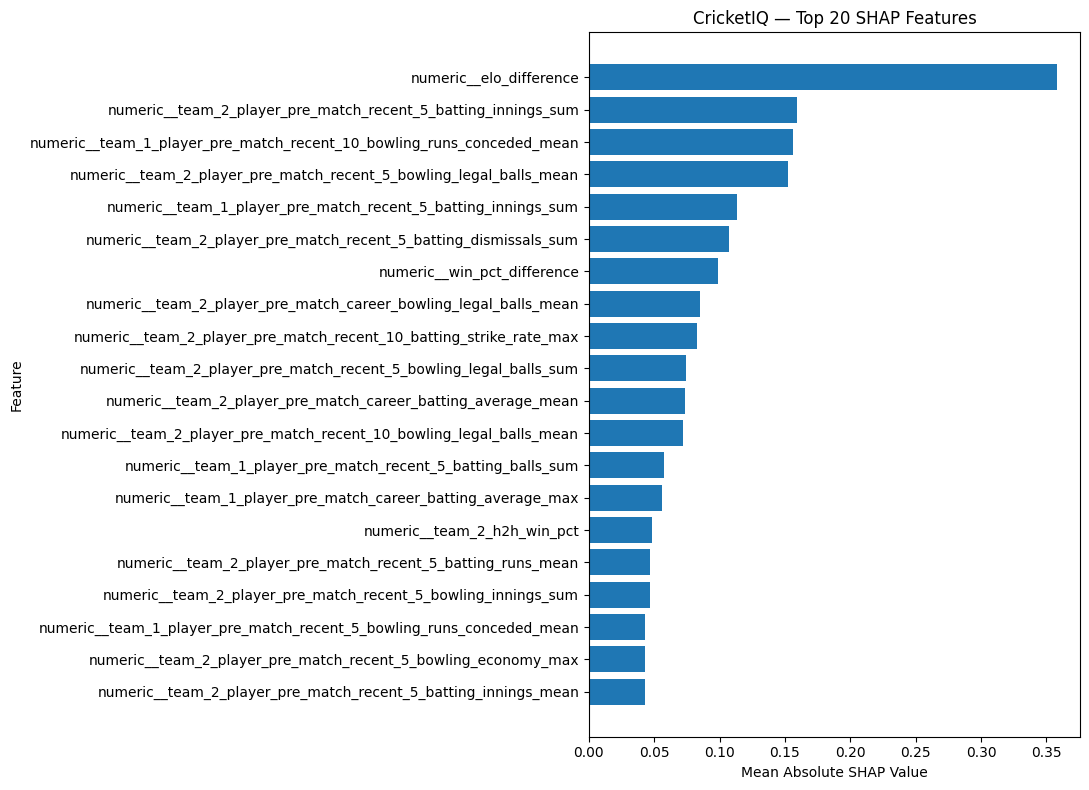

In [84]:
# Calculate global SHAP importance

mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

shap_importance_df = pd.DataFrame({
    "Feature": clean_feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance_df = shap_importance_df.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("CRICKETIQ — GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 65)

display(shap_importance_df.head(25))

# Visualize top 20 features
import matplotlib.pyplot as plt

top_features = shap_importance_df.head(20).sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("CricketIQ — Top 20 SHAP Features")
plt.tight_layout()
plt.show()

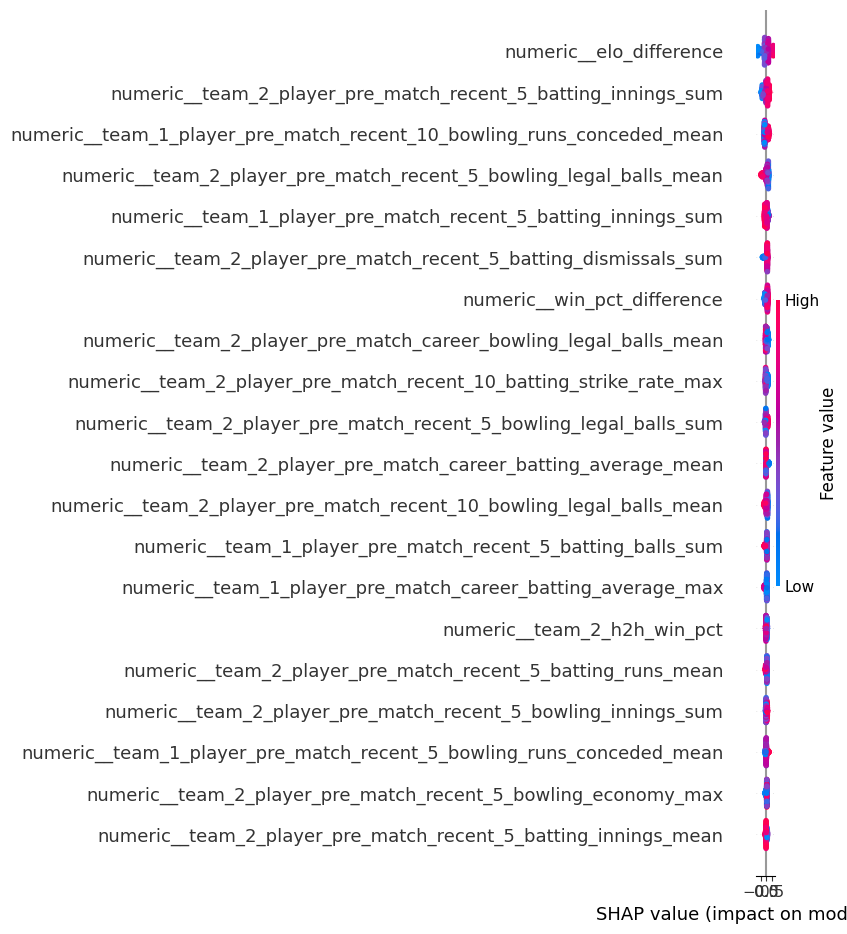

In [85]:
# SHAP summary plot — direction and magnitude of feature influence

shap.summary_plot(
    shap_values,
    X_validation_clean_transformed,
    feature_names=clean_feature_names,
    max_display=20,
    show=True
)

In [86]:
# Inspect actual SHAP contribution distributions

top_10_features = shap_importance_df.head(10)["Feature"].tolist()

diagnostic_rows = []

for feature in top_10_features:

    feature_index = np.where(
        clean_feature_names == feature
    )[0][0]

    values = shap_values[:, feature_index]

    diagnostic_rows.append({
        "Feature": feature,
        "Mean_Absolute_SHAP": np.mean(np.abs(values)),
        "Minimum_SHAP": np.min(values),
        "Maximum_SHAP": np.max(values),
        "SHAP_Std": np.std(values),
        "Positive_Contributions": np.sum(values > 0),
        "Negative_Contributions": np.sum(values < 0)
    })

shap_diagnostic_df = pd.DataFrame(diagnostic_rows)

print("SHAP CONTRIBUTION DIAGNOSTICS")
print("=" * 70)

display(shap_diagnostic_df.round(5))

print("\nOVERALL SHAP DISTRIBUTION")
print("Minimum:", shap_values.min())
print("Maximum:", shap_values.max())
print("Mean absolute:", np.abs(shap_values).mean())
print("Standard deviation:", shap_values.std())

SHAP CONTRIBUTION DIAGNOSTICS


,Feature,Mean_Absolute_SHAP,Minimum_SHAP,Maximum_SHAP,SHAP_Std,Positive_Contributions,Negative_Contributions
0,numeric__elo_difference,0.35791,-0.91134,0.76689,0.44116,192,200
1,numeric__team_2_player_pre_match_recent_5_batting_innings_sum,0.15924,-0.51911,0.31331,0.20724,197,195
2,numeric__team_1_player_pre_match_recent_10_bowling_runs_conceded_mean,0.15634,-0.24304,0.28747,0.15872,144,248
3,numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_mean,0.15248,-0.53446,0.22211,0.18564,230,162
4,numeric__team_1_player_pre_match_recent_5_batting_innings_sum,0.11333,-0.19378,0.27569,0.12483,235,157
5,numeric__team_2_player_pre_match_recent_5_batting_dismissals_sum,0.10735,-0.38454,0.10602,0.12957,313,79
6,numeric__win_pct_difference,0.09881,-0.22290,0.13780,0.10734,250,142
7,numeric__team_2_player_pre_match_career_bowling_legal_balls_mean,0.08532,-0.08801,0.21226,0.08695,250,142
8,numeric__team_2_player_pre_match_recent_10_batting_strike_rate_max,0.08235,-0.11072,0.17303,0.08717,168,224
9,numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_sum,0.07397,-0.18087,0.14598,0.07831,114,278



OVERALL SHAP DISTRIBUTION
Minimum: -0.91133624
Maximum: 0.76688814
Mean absolute: 0.006703646
Standard deviation: 0.02770959


SHAP DISTRIBUTION CHECK

numeric__elo_difference
5th percentile: -0.83775574
25th percentile: -0.19408289
Median: -0.031103492
75th percentile: 0.20728335
95th percentile: 0.68157685
Minimum: -0.91133624
Maximum: 0.76688814

numeric__team_2_player_pre_match_recent_5_batting_innings_sum
5th percentile: -0.42689914
25th percentile: -0.09328704
Median: 0.002738183
75th percentile: 0.119677246
95th percentile: 0.25648525
Minimum: -0.51910686
Maximum: 0.3133109

numeric__team_1_player_pre_match_recent_10_bowling_runs_conceded_mean
5th percentile: -0.20652948
25th percentile: -0.17654188
Median: -0.13773729
75th percentile: 0.14644498
95th percentile: 0.20968823
Minimum: -0.24303806
Maximum: 0.28746802

numeric__team_2_player_pre_match_recent_5_bowling_legal_balls_mean
5th percentile: -0.38831416
25th percentile: -0.06291692
Median: 0.08742955
75th percentile: 0.16403674
95th percentile: 0.19701394
Minimum: -0.5344564
Maximum: 0.22211048

numeric__team_1_player_pre_match_recent_5_batting_inn

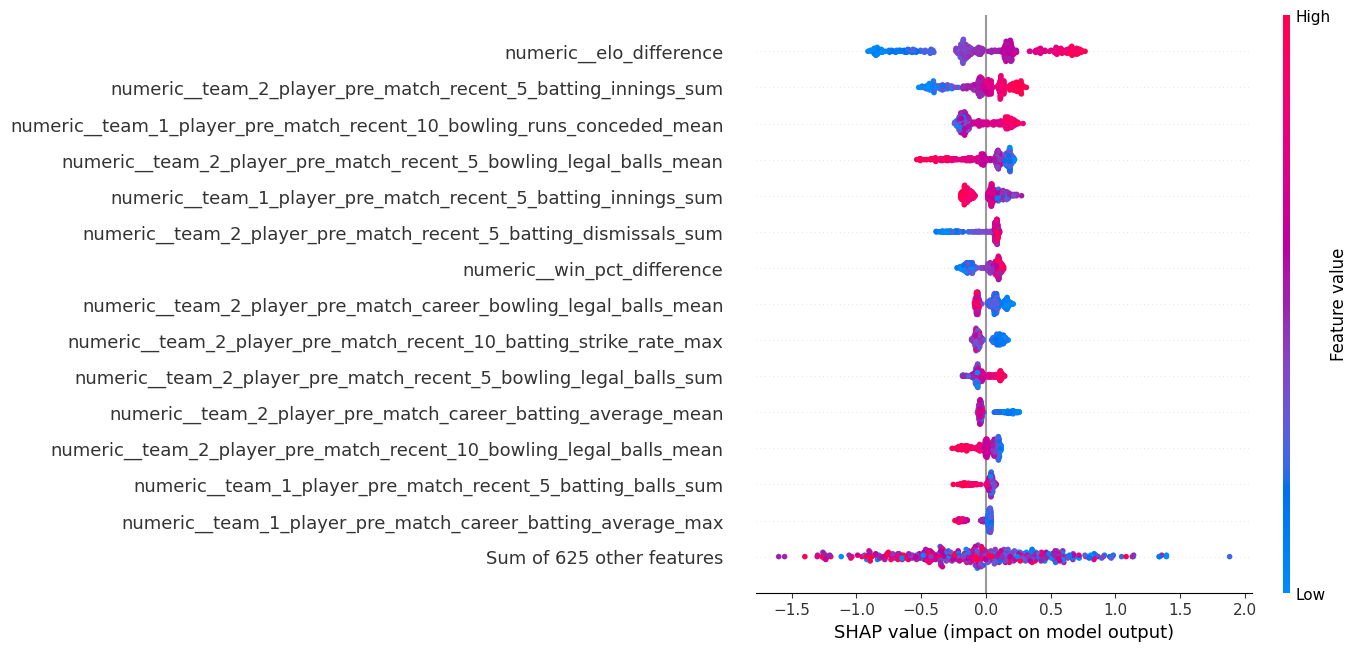

In [87]:
# Inspect SHAP distributions for the top five features

print("SHAP DISTRIBUTION CHECK")
print("=" * 65)

for feature in shap_importance_df.head(5)["Feature"]:

    idx = np.where(clean_feature_names == feature)[0][0]
    values = shap_values[:, idx]

    print(f"\n{feature}")
    print("5th percentile:", np.percentile(values, 5))
    print("25th percentile:", np.percentile(values, 25))
    print("Median:", np.median(values))
    print("75th percentile:", np.percentile(values, 75))
    print("95th percentile:", np.percentile(values, 95))
    print("Minimum:", values.min())
    print("Maximum:", values.max())

# Create SHAP Explanation object
shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(len(y_validation_clean), expected_value),
    data=X_validation_clean_transformed,
    feature_names=list(clean_feature_names)
)

# Generate updated beeswarm plot
shap.plots.beeswarm(
    shap_explanation,
    max_display=15,
    show=True
)

In [88]:
# Select a validation match for individual explanation

# Choose a match with a relatively strong prediction
validation_probabilities = xgb_clean_model.predict_proba(
    X_validation_clean_transformed
)[:, 1]

# Find the match with the highest Team 1 win probability
selected_match_idx = int(np.argmax(validation_probabilities))

selected_probability = validation_probabilities[selected_match_idx]

selected_match = validation_df.iloc[selected_match_idx]

print("CRICKETIQ — INDIVIDUAL MATCH EXPLANATION")
print("=" * 60)

print("Match:", selected_match["team_1"], "vs", selected_match["team_2"])
print("Date:", selected_match["match_date"])
print("Actual outcome:", y_validation_clean.iloc[selected_match_idx]
      if hasattr(y_validation_clean, "iloc")
      else y_validation_clean[selected_match_idx])

print("\nTeam 1 win probability:", round(selected_probability, 4))
print("Team 2 win probability:", round(1 - selected_probability, 4))

print("\nSelected validation index:", selected_match_idx)

CRICKETIQ — INDIVIDUAL MATCH EXPLANATION
Match: Bangladesh vs Zimbabwe
Date: 2020-03-06 00:00:00
Actual outcome: 1

Team 1 win probability: 0.9774
Team 2 win probability: 0.0226

Selected validation index: 39


INDIVIDUAL SHAP EXPLANATION
Match: Bangladesh vs Zimbabwe
Team 1 win probability: 0.9774
Expected value (raw margin): 0.2374
Reconstructed raw margin: 3.765582


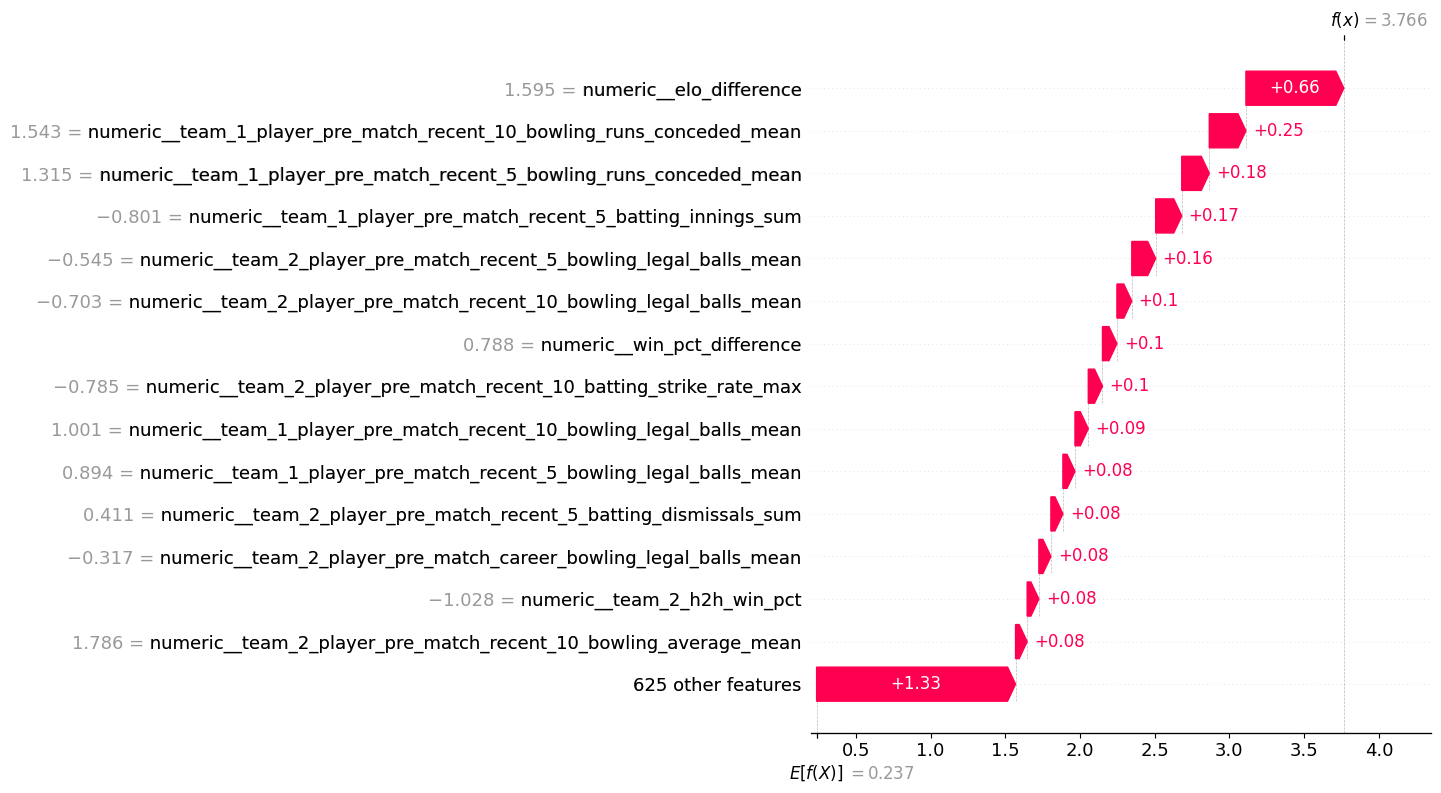

In [89]:
# Extract SHAP contributions for the selected match

selected_shap_values = shap_values[selected_match_idx]

selected_feature_values = X_validation_clean_transformed[
    selected_match_idx
]

# Create individual SHAP explanation
individual_explanation = shap.Explanation(
    values=selected_shap_values,
    base_values=expected_value,
    data=selected_feature_values,
    feature_names=list(clean_feature_names)
)

print("INDIVIDUAL SHAP EXPLANATION")
print("=" * 60)

print("Match: Bangladesh vs Zimbabwe")
print("Team 1 win probability:", round(selected_probability, 4))
print("Expected value (raw margin):", round(expected_value, 4))

print(
    "Reconstructed raw margin:",
    round(expected_value + selected_shap_values.sum(), 6)
)

# Display the 15 strongest feature contributions
shap.plots.waterfall(
    individual_explanation,
    max_display=15
)

In [90]:
# CricketIQ — Performance Drift Investigation
# Cell 1: Year-wise prediction behaviour

yearly_drift = (
    error_analysis_df.groupby("Year")
    .agg(
        Matches=("Correct", "count"),
        Correct_Predictions=("Correct", "sum"),
        Accuracy=("Correct", "mean"),
        Mean_Prediction_Confidence=("Prediction_Confidence", "mean"),
        Mean_Team1_Probability=("Team_1_Win_Probability", "mean"),
        Prediction_Errors=("Correct", lambda x: (~x).sum())
    )
    .reset_index()
)

yearly_drift["Error_Rate"] = (
    1 - yearly_drift["Accuracy"]
)

# Calculate actual Team 1 win percentage
actual_team1_win_rate = (
    error_analysis_df.groupby("Year")["Actual"]
    .mean()
    .reset_index(name="Actual_Team1_Win_Rate")
)

yearly_drift = yearly_drift.merge(
    actual_team1_win_rate,
    on="Year"
)

yearly_drift = yearly_drift.sort_values("Year")

print("CRICKETIQ — YEAR-WISE PREDICTION BEHAVIOUR")
print("=" * 75)

display(yearly_drift.round(4))

print("\n2024 COMPARISON WITH OTHER YEARS")

comparison_columns = [
    "Year",
    "Matches",
    "Accuracy",
    "Mean_Prediction_Confidence",
    "Mean_Team1_Probability",
    "Actual_Team1_Win_Rate",
    "Error_Rate"
]

display(yearly_drift[comparison_columns].round(4))

CRICKETIQ — YEAR-WISE PREDICTION BEHAVIOUR


,Year,Matches,Correct_Predictions,Accuracy,Mean_Prediction_Confidence,Mean_Team1_Probability,Prediction_Errors,Error_Rate,Actual_Team1_Win_Rate
0,2023,79,54,0.6835,0.6574,0.5606,25,0.3165,0.5190
1,2024,97,55,0.5670,0.6680,0.5359,42,0.4330,0.4021
2,2025,109,74,0.6789,0.6638,0.5603,35,0.3211,0.5138
3,2026,107,70,0.6542,0.6647,0.5611,37,0.3458,0.5701



2024 COMPARISON WITH OTHER YEARS


,Year,Matches,Accuracy,Mean_Prediction_Confidence,Mean_Team1_Probability,Actual_Team1_Win_Rate,Error_Rate
0,2023,79,0.6835,0.6574,0.5606,0.5190,0.3165
1,2024,97,0.5670,0.6680,0.5359,0.4021,0.4330
2,2025,109,0.6789,0.6638,0.5603,0.5138,0.3211
3,2026,107,0.6542,0.6647,0.5611,0.5701,0.3458


In [91]:
from sklearn.metrics import (
    roc_auc_score,
    log_loss,
    brier_score_loss,
    balanced_accuracy_score
)

yearly_metrics = []

for year, group in error_analysis_df.groupby("Year"):

    y_true = group["Actual"].astype(int).to_numpy()
    y_prob = group["Team_1_Win_Probability"].to_numpy()

    # Apply the selected classification threshold
    y_pred = (y_prob >= 0.60).astype(int)

    # ROC-AUC and balanced accuracy require both classes
    if len(np.unique(y_true)) == 2:
        auc = roc_auc_score(y_true, y_prob)
        balanced_acc = balanced_accuracy_score(y_true, y_pred)
    else:
        auc = np.nan
        balanced_acc = np.nan

    yearly_metrics.append({
        "Year": year,
        "Matches": len(group),
        "ROC_AUC": auc,
        "Log_Loss": log_loss(y_true, y_prob, labels=[0, 1]),
        "Brier_Score": brier_score_loss(y_true, y_prob),
        "Balanced_Accuracy": balanced_acc
    })

yearly_metrics_df = pd.DataFrame(yearly_metrics)

print("CRICKETIQ — YEARLY MODEL QUALITY")
print("=" * 70)

display(yearly_metrics_df.round(4))

CRICKETIQ — YEARLY MODEL QUALITY


,Year,Matches,ROC_AUC,Log_Loss,Brier_Score,Balanced_Accuracy
0,2023,79,0.7580,0.5867,0.2017,0.6845
1,2024,97,0.5734,0.7369,0.2674,0.5623
2,2025,109,0.7375,0.6054,0.2081,0.6804
3,2026,107,0.7423,0.5854,0.1992,0.6593


In [92]:
# CricketIQ — Feature Distribution Drift Analysis

# Verify required datasets
print("AVAILABLE DATA")
print("=" * 60)

print("X_test_raw:", X_test_raw.shape)
print("test_df:", test_df.shape)

# Identify year for each test match
drift_data = X_test_raw.copy()

drift_data["Year"] = pd.to_datetime(
    test_df["match_date"]
).dt.year.to_numpy()

# Select top 10 numerical features from SHAP
top_shap_features = shap_importance_df[
    shap_importance_df["Feature"].str.startswith("numeric__")
].head(10)["Feature"].str.replace(
    "numeric__", "", regex=False
).tolist()

# Keep only features available in the raw test dataset
available_features = [
    feature for feature in top_shap_features
    if feature in drift_data.columns
]

print("\nTop SHAP features available:", len(available_features))
print(available_features)

# Calculate yearly feature statistics
drift_results = []

for feature in available_features:

    for year in sorted(drift_data["Year"].unique()):

        year_values = drift_data.loc[
            drift_data["Year"] == year, feature
        ]

        drift_results.append({
            "Feature": feature,
            "Year": year,
            "Mean": year_values.mean(),
            "Median": year_values.median(),
            "Missing_Percentage": year_values.isna().mean() * 100
        })

feature_drift_df = pd.DataFrame(drift_results)

print("\nYEAR-WISE FEATURE DISTRIBUTION")
display(
    feature_drift_df.round(3)
)

print("\n2024 FEATURE DISTRIBUTION")
display(
    feature_drift_df[
        feature_drift_df["Year"] == 2024
    ].sort_values("Feature")
)

AVAILABLE DATA
X_test_raw: (392, 270)
test_df: (392, 294)

Top SHAP features available: 10
['elo_difference', 'team_2_player_pre_match_recent_5_batting_innings_sum', 'team_1_player_pre_match_recent_10_bowling_runs_conceded_mean', 'team_2_player_pre_match_recent_5_bowling_legal_balls_mean', 'team_1_player_pre_match_recent_5_batting_innings_sum', 'team_2_player_pre_match_recent_5_batting_dismissals_sum', 'win_pct_difference', 'team_2_player_pre_match_career_bowling_legal_balls_mean', 'team_2_player_pre_match_recent_10_batting_strike_rate_max', 'team_2_player_pre_match_recent_5_bowling_legal_balls_sum']

YEAR-WISE FEATURE DISTRIBUTION


,Feature,Year,Mean,Median,Missing_Percentage
0,elo_difference,2023,-4.867,-6.582,0.0
1,elo_difference,2024,-11.384,-5.695,0.0
2,elo_difference,2025,-16.782,-12.319,0.0
3,elo_difference,2026,3.489,6.452,0.0
4,team_2_player_pre_match_recent_5_batting_innings_sum,2023,50.456,53.000,0.0
5,team_2_player_pre_match_recent_5_batting_innings_sum,2024,44.062,46.000,0.0
6,team_2_player_pre_match_recent_5_batting_innings_sum,2025,47.477,49.000,0.0
7,team_2_player_pre_match_recent_5_batting_innings_sum,2026,47.579,50.000,0.0
8,team_1_player_pre_match_recent_10_bowling_runs_conceded_mean,2023,210.834,211.182,0.0
9,team_1_player_pre_match_recent_10_bowling_runs_conceded_mean,2024,180.664,182.091,0.0



2024 FEATURE DISTRIBUTION


,Feature,Year,Mean,Median,Missing_Percentage
1,elo_difference,2024,-11.383589,-5.694889,0.0
9,team_1_player_pre_match_recent_10_bowling_runs_conceded_mean,2024,180.664272,182.090909,0.0
17,team_1_player_pre_match_recent_5_batting_innings_sum,2024,46.257732,46.000000,0.0
29,team_2_player_pre_match_career_bowling_legal_balls_mean,2024,762.389681,674.272727,0.0
33,team_2_player_pre_match_recent_10_batting_strike_rate_max,2024,115.583462,109.677419,0.0
21,team_2_player_pre_match_recent_5_batting_dismissals_sum,2024,35.773196,37.000000,0.0
5,team_2_player_pre_match_recent_5_batting_innings_sum,2024,44.061856,46.000000,0.0
13,team_2_player_pre_match_recent_5_bowling_legal_balls_mean,2024,112.362505,110.083333,0.0
37,team_2_player_pre_match_recent_5_bowling_legal_balls_sum,2024,1172.567010,1184.000000,0.0
25,win_pct_difference,2024,-0.010168,0.007729,0.0


In [93]:
# CricketIQ — Identify teams associated with 2024 prediction errors

results_2024 = error_analysis_df[
    error_analysis_df["Year"] == 2024
].copy()

team_records = []

for _, match in results_2024.iterrows():

    team_1 = match["team_1"]
    team_2 = match["team_2"]

    actual_winner = (
        team_1 if match["Actual"] == 1 else team_2
    )

    predicted_winner = (
        team_1 if match["Predicted"] == 1 else team_2
    )

    # Team 1 record
    team_records.append({
        "Team": team_1,
        "Actual_Wins": int(actual_winner == team_1),
        "Predicted_Wins": int(predicted_winner == team_1),
        "Correct_Match_Prediction": int(match["Correct"])
    })

    # Team 2 record
    team_records.append({
        "Team": team_2,
        "Actual_Wins": int(actual_winner == team_2),
        "Predicted_Wins": int(predicted_winner == team_2),
        "Correct_Match_Prediction": int(match["Correct"])
    })


team_drift_2024 = pd.DataFrame(team_records)

team_drift_summary = (
    team_drift_2024.groupby("Team")
    .agg(
        Appearances=("Team", "count"),
        Actual_Wins=("Actual_Wins", "sum"),
        Predicted_Wins=("Predicted_Wins", "sum"),
        Correct_Matches=("Correct_Match_Prediction", "sum")
    )
    .reset_index()
)

team_drift_summary["Actual_Win_Rate"] = (
    team_drift_summary["Actual_Wins"] /
    team_drift_summary["Appearances"]
)

team_drift_summary["Predicted_Win_Rate"] = (
    team_drift_summary["Predicted_Wins"] /
    team_drift_summary["Appearances"]
)

team_drift_summary["Match_Accuracy"] = (
    team_drift_summary["Correct_Matches"] /
    team_drift_summary["Appearances"]
)

# Focus on teams with at least 3 appearances
team_drift_summary = team_drift_summary[
    team_drift_summary["Appearances"] >= 3
].sort_values(
    ["Match_Accuracy", "Appearances"],
    ascending=[True, False]
).reset_index(drop=True)

print("CRICKETIQ — 2024 TEAM-WISE PERFORMANCE")
print("=" * 75)

display(team_drift_summary.round(3))

print("\n2024 MATCHES:", len(results_2024))
print("UNIQUE TEAMS:", results_2024["team_1"].nunique() +
      len(set(results_2024["team_2"]) - set(results_2024["team_1"])))

CRICKETIQ — 2024 TEAM-WISE PERFORMANCE


,Team,Appearances,Actual_Wins,Predicted_Wins,Correct_Matches,Actual_Win_Rate,Predicted_Win_Rate,Match_Accuracy
0,Bangladesh,9,3,5,3,0.333,0.556,0.333
1,Oman,10,6,4,4,0.600,0.400,0.400
2,Nepal,12,5,10,5,0.417,0.833,0.417
3,Canada,15,8,0,7,0.533,0.000,0.467
4,West Indies,12,6,0,6,0.500,0.000,0.500
5,England,8,3,3,4,0.375,0.375,0.500
6,Sri Lanka,15,12,9,8,0.800,0.600,0.533
7,United States of America,11,7,8,6,0.636,0.727,0.545
8,Pakistan,9,7,5,5,0.778,0.556,0.556
9,Scotland,9,6,8,5,0.667,0.889,0.556



2024 MATCHES: 97
UNIQUE TEAMS: 20


In [94]:
# CricketIQ — 2024 Matchup Error Analysis

matchup_2024 = results_2024.copy()

# Create an order-independent matchup identifier
matchup_2024["Matchup"] = matchup_2024.apply(
    lambda row: " vs ".join(
        sorted([row["team_1"], row["team_2"]])
    ),
    axis=1
)

matchup_summary_2024 = (
    matchup_2024.groupby("Matchup")
    .agg(
        Matches=("Correct", "count"),
        Correct=("Correct", "sum"),
        Mean_Confidence=("Prediction_Confidence", "mean"),
        Mean_Team1_Probability=("Team_1_Win_Probability", "mean")
    )
    .reset_index()
)

matchup_summary_2024["Errors"] = (
    matchup_summary_2024["Matches"] -
    matchup_summary_2024["Correct"]
)

matchup_summary_2024["Accuracy"] = (
    matchup_summary_2024["Correct"] /
    matchup_summary_2024["Matches"]
)

# Focus on repeated matchups
repeated_matchups_2024 = matchup_summary_2024[
    matchup_summary_2024["Matches"] >= 2
].sort_values(
    ["Errors", "Matches"],
    ascending=False
).reset_index(drop=True)

print("CRICKETIQ — REPEATED 2024 MATCHUP ANALYSIS")
print("=" * 75)

display(repeated_matchups_2024.round(3))

print("\nTOTAL REPEATED MATCHUPS:",
      len(repeated_matchups_2024))

CRICKETIQ — REPEATED 2024 MATCHUP ANALYSIS


,Matchup,Matches,Correct,Mean_Confidence,Mean_Team1_Probability,Errors,Accuracy
0,Bangladesh vs West Indies,3,0,0.694,0.694,3,0.000
1,Australia vs England,5,3,0.764,0.522,2,0.600
2,Canada vs Nepal,5,3,0.703,0.436,2,0.600
3,Bangladesh vs Sri Lanka,3,1,0.651,0.567,2,0.333
4,England vs West Indies,3,1,0.679,0.598,2,0.333
5,Pakistan vs South Africa,3,1,0.540,0.460,2,0.333
6,Pakistan vs Zimbabwe,3,1,0.663,0.337,2,0.333
7,Canada vs Oman,2,0,0.612,0.501,2,0.000
8,Canada vs Scotland,2,0,0.842,0.842,2,0.000
9,Canada vs United Arab Emirates,2,0,0.602,0.684,2,0.000



TOTAL REPEATED MATCHUPS: 37


In [95]:
# CricketIQ — Player Data Availability by Year

# Identify player-related raw columns
player_columns = [
    col for col in X_test_raw.columns
    if "player" in col.lower()
]

# Add year information
player_missingness = X_test_raw[player_columns].copy()

player_missingness["Year"] = pd.to_datetime(
    test_df["match_date"]
).dt.year.to_numpy()

# Calculate missingness by year
missingness_results = []

for year, group in player_missingness.groupby("Year"):

    total_cells = group[player_columns].size

    missing_cells = group[player_columns].isna().sum().sum()

    missingness_results.append({
        "Year": year,
        "Matches": len(group),
        "Player_Features": len(player_columns),
        "Missing_Cells": missing_cells,
        "Total_Cells": total_cells,
        "Missing_Percentage": (
            missing_cells / total_cells * 100
        )
    })

missingness_summary = pd.DataFrame(missingness_results)

print("CRICKETIQ — PLAYER FEATURE MISSINGNESS")
print("=" * 65)

display(missingness_summary.round(3))

print("\nPLAYER FEATURE COUNT:", len(player_columns))

CRICKETIQ — PLAYER FEATURE MISSINGNESS


,Year,Matches,Player_Features,Missing_Cells,Total_Cells,Missing_Percentage
0,2023,79,240,0,18960,0.0
1,2024,97,240,0,23280,0.0
2,2025,109,240,0,26160,0.0
3,2026,107,240,0,25680,0.0



PLAYER FEATURE COUNT: 240


In [96]:
# CricketIQ — 2024 Confidence Reliability Analysis

confidence_2024 = results_2024.copy()

# Group predictions by confidence
confidence_bins = [0, 0.60, 0.70, 0.80, 0.90, 1.01]

confidence_labels = [
    "Below 60%",
    "60–69%",
    "70–79%",
    "80–89%",
    "90–100%"
]

confidence_2024["Confidence_Group"] = pd.cut(
    confidence_2024["Prediction_Confidence"],
    bins=confidence_bins,
    labels=confidence_labels,
    right=False
)

confidence_summary_2024 = (
    confidence_2024.groupby(
        "Confidence_Group",
        observed=False
    )
    .agg(
        Matches=("Correct", "count"),
        Correct=("Correct", "sum"),
        Mean_Confidence=("Prediction_Confidence", "mean")
    )
    .reset_index()
)

confidence_summary_2024["Accuracy"] = (
    confidence_summary_2024["Correct"] /
    confidence_summary_2024["Matches"]
)

confidence_summary_2024["Errors"] = (
    confidence_summary_2024["Matches"] -
    confidence_summary_2024["Correct"]
)

print("CRICKETIQ — 2024 CONFIDENCE RELIABILITY")
print("=" * 65)

display(confidence_summary_2024.round(4))

CRICKETIQ — 2024 CONFIDENCE RELIABILITY


,Confidence_Group,Matches,Correct,Mean_Confidence,Accuracy,Errors
0,Below 60%,26,15,0.4991,0.5769,11
1,60–69%,31,16,0.6443,0.5161,15
2,70–79%,24,13,0.7523,0.5417,11
3,80–89%,15,10,0.8573,0.6667,5
4,90–100%,1,1,0.9351,1.0000,0


In [97]:
# CricketIQ — Confidence Reliability Across Test Years

yearly_confidence = error_analysis_df.copy()

confidence_bins = [0, 0.60, 0.70, 0.80, 0.90, 1.01]

confidence_labels = [
    "Below 60%",
    "60–69%",
    "70–79%",
    "80–89%",
    "90–100%"
]

yearly_confidence["Confidence_Group"] = pd.cut(
    yearly_confidence["Prediction_Confidence"],
    bins=confidence_bins,
    labels=confidence_labels,
    right=False
)

confidence_by_year = (
    yearly_confidence.groupby(
        ["Year", "Confidence_Group"],
        observed=False
    )
    .agg(
        Matches=("Correct", "count"),
        Accuracy=("Correct", "mean"),
        Mean_Confidence=("Prediction_Confidence", "mean")
    )
    .reset_index()
)

print("CRICKETIQ — CONFIDENCE RELIABILITY BY YEAR")
print("=" * 75)

display(
    confidence_by_year.pivot(
        index="Confidence_Group",
        columns="Year",
        values="Accuracy"
    ).round(3)
)

print("\nMATCH COUNTS BY CONFIDENCE GROUP")

display(
    confidence_by_year.pivot(
        index="Confidence_Group",
        columns="Year",
        values="Matches"
    ).fillna(0).astype(int)
)

CRICKETIQ — CONFIDENCE RELIABILITY BY YEAR


Year,2023,2024,2025,2026
Confidence_Group,,,,
Below 60%,0.560,0.577,0.556,0.419
60–69%,0.762,0.516,0.586,0.629
70–79%,0.571,0.542,0.917,0.905
80–89%,1.000,0.667,0.643,0.833
90–100%,1.000,1.000,1.000,0.500



MATCH COUNTS BY CONFIDENCE GROUP


Year,2023,2024,2025,2026
Confidence_Group,,,,
Below 60%,25,26,36,31
60–69%,21,31,29,35
70–79%,21,24,24,21
80–89%,10,15,14,18
90–100%,2,1,6,2


In [98]:
# CricketIQ — Inspect Training Out-of-Fold Predictions

print("AVAILABLE OOF PREDICTION KEYS")
print("=" * 55)

print(list(oof_predictions.keys()))

print("\nOOF TARGET INFORMATION")
print("=" * 55)

print("OOF target shape:", np.asarray(oof_y_true).shape)
print("OOF fold shape:", np.asarray(oof_fold_numbers).shape)

for model_name, predictions in oof_predictions.items():

    predictions = np.asarray(predictions)

    print(f"\nModel: {model_name}")
    print("Prediction shape:", predictions.shape)
    print("Minimum probability:", predictions.min())
    print("Maximum probability:", predictions.max())
    print("Mean probability:", predictions.mean())
    print("Contains NaN:", np.isnan(predictions).any())

AVAILABLE OOF PREDICTION KEYS
['Previous XGBoost (Depth 3)', 'Tuned XGBoost (Depth 2)']

OOF TARGET INFORMATION
OOF target shape: (1479,)
OOF fold shape: (1479,)

Model: Previous XGBoost (Depth 3)
Prediction shape: (1479,)
Minimum probability: 0.033608533442020416
Maximum probability: 0.9801545739173889
Mean probability: 0.556303189491867
Contains NaN: False

Model: Tuned XGBoost (Depth 2)
Prediction shape: (1479,)
Minimum probability: 0.02609897032380104
Maximum probability: 0.9806099534034729
Mean probability: 0.5592010162916838
Contains NaN: False


DEPTH-3 OOF BASELINE CALIBRATION
Brier Score : 0.1978
Log Loss    : 0.5762


,Mean_Predicted_Probability,Actual_Win_Frequency
0,0.1687,0.1284
1,0.3158,0.4054
2,0.4083,0.4324
3,0.4770,0.5338
4,0.5335,0.4662
5,0.6003,0.5714
6,0.6622,0.7568
7,0.7245,0.7095
8,0.7909,0.8108
9,0.8820,0.9392


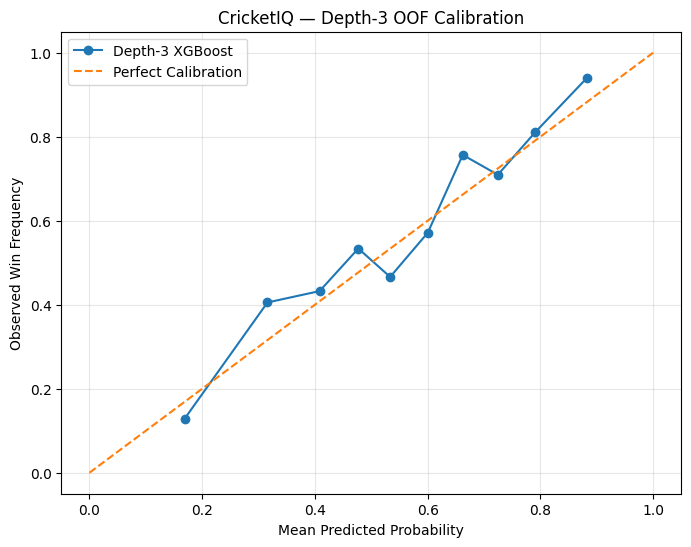

In [99]:
# CricketIQ — Baseline OOF Calibration Analysis

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss
import matplotlib.pyplot as plt

depth3_oof_prob = np.asarray(
    oof_predictions["Previous XGBoost (Depth 3)"]
)

depth3_oof_y = np.asarray(oof_y_true)

# Calculate baseline probability metrics
oof_brier = brier_score_loss(
    depth3_oof_y,
    depth3_oof_prob
)

oof_logloss = log_loss(
    depth3_oof_y,
    depth3_oof_prob
)

print("DEPTH-3 OOF BASELINE CALIBRATION")
print("=" * 55)
print(f"Brier Score : {oof_brier:.4f}")
print(f"Log Loss    : {oof_logloss:.4f}")

# Calculate calibration curve
fraction_positive, mean_predicted = calibration_curve(
    depth3_oof_y,
    depth3_oof_prob,
    n_bins=10,
    strategy="quantile"
)

calibration_table = pd.DataFrame({
    "Mean_Predicted_Probability": mean_predicted,
    "Actual_Win_Frequency": fraction_positive
})

display(calibration_table.round(4))

# Plot reliability diagram
plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Depth-3 XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Win Frequency")
plt.title("CricketIQ — Depth-3 OOF Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [100]:
# CricketIQ — Platt Scaling Calibration

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss

# Convert probabilities to logits
epsilon = 1e-7

oof_logits = np.log(
    np.clip(depth3_oof_prob, epsilon, 1 - epsilon) /
    (1 - np.clip(depth3_oof_prob, epsilon, 1 - epsilon))
).reshape(-1, 1)

# Fit calibrator using OOF predictions only
platt_calibrator = LogisticRegression(
    solver="lbfgs",
    random_state=42
)

platt_calibrator.fit(oof_logits, depth3_oof_y)

# Apply calibrator to validation predictions
validation_prob_original = np.asarray(xgb_clean_val_prob)

validation_logits = np.log(
    np.clip(validation_prob_original, epsilon, 1 - epsilon) /
    (1 - np.clip(validation_prob_original, epsilon, 1 - epsilon))
).reshape(-1, 1)

validation_prob_platt = platt_calibrator.predict_proba(
    validation_logits
)[:, 1]

# Compare probability metrics
platt_comparison = pd.DataFrame([
    {
        "Model": "Original XGBoost",
        "Brier_Score": brier_score_loss(
            y_validation_clean, validation_prob_original
        ),
        "Log_Loss": log_loss(
            y_validation_clean, validation_prob_original
        )
    },
    {
        "Model": "Platt Calibrated",
        "Brier_Score": brier_score_loss(
            y_validation_clean, validation_prob_platt
        ),
        "Log_Loss": log_loss(
            y_validation_clean, validation_prob_platt
        )
    }
])

print("CRICKETIQ — PLATT SCALING COMPARISON")
print("=" * 60)
display(platt_comparison.round(4))

print("\nCALIBRATOR PARAMETERS")
print("Coefficient:", platt_calibrator.coef_[0][0])
print("Intercept:", platt_calibrator.intercept_[0])

CRICKETIQ — PLATT SCALING COMPARISON


,Model,Brier_Score,Log_Loss
0,Original XGBoost,0.1936,0.5696
1,Platt Calibrated,0.1951,0.5738



CALIBRATOR PARAMETERS
Coefficient: 1.0562223370512283
Intercept: 0.08520596148855084


In [101]:
# CricketIQ — Isotonic Regression Calibration

from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, log_loss

# Fit isotonic calibrator using OOF predictions only
isotonic_calibrator = IsotonicRegression(
    y_min=0,
    y_max=1,
    out_of_bounds="clip"
)

isotonic_calibrator.fit(
    depth3_oof_prob,
    depth3_oof_y
)

# Apply to validation predictions
validation_prob_isotonic = isotonic_calibrator.predict(
    validation_prob_original
)

# Compare all three approaches
isotonic_comparison = pd.DataFrame([
    {
        "Model": "Original XGBoost",
        "Brier_Score": brier_score_loss(
            y_validation_clean, validation_prob_original
        ),
        "Log_Loss": log_loss(
            y_validation_clean, validation_prob_original
        )
    },
    {
        "Model": "Platt Scaling",
        "Brier_Score": brier_score_loss(
            y_validation_clean, validation_prob_platt
        ),
        "Log_Loss": log_loss(
            y_validation_clean, validation_prob_platt
        )
    },
    {
        "Model": "Isotonic Regression",
        "Brier_Score": brier_score_loss(
            y_validation_clean, validation_prob_isotonic
        ),
        "Log_Loss": log_loss(
            y_validation_clean, validation_prob_isotonic
        )
    }
])

print("CRICKETIQ — CALIBRATION METHOD COMPARISON")
print("=" * 65)

display(isotonic_comparison.round(4))

print("\nISOTONIC CALIBRATOR")
print("Number of fitted thresholds:", len(isotonic_calibrator.X_thresholds_))

CRICKETIQ — CALIBRATION METHOD COMPARISON


,Model,Brier_Score,Log_Loss
0,Original XGBoost,0.1936,0.5696
1,Platt Scaling,0.1951,0.5738
2,Isotonic Regression,0.1980,0.5824



ISOTONIC CALIBRATOR
Number of fitted thresholds: 40
